# Sistema Inteligente de Detecção e Classificação de Placas de Trânsito
### AED - Projeto Integrador · Checkpoint 2 (N2): modelo treinado

**Pontifícia Universidade Católica de Goiás** - Escola Politécnica e de Artes

Curso de Ciência de Dados e Inteligência Artificial

Disciplina: **CDI1021 · Visão Computacional (2026/2)** -> Prof. Welington Júlio Dias Rodrigues

**Equipe:** Caio Henrique · Fernanda Andrade · Alisson Leonardo · Vitor Manoel · Luiz Antônio

---

Na N1 ([`checkpoint1_pipeline_pdi.ipynb`](checkpoint1_pipeline_pdi.ipynb)) o sistema decidia
por regras de cor e forma. Aqui a decisão passa para um modelo treinado, e o pipeline clássico
da N1 vira a linha de base: é contra ele que o ganho do modelo é medido.

| Critério do Checkpoint 2 | Peso | Onde está |
|---|---|---|
| Dataset anotado e particionado | 25% | Seções 1 a 4 |
| Baseline clássico medido | 15% | Seção 5, e a comparação com o modelo na Seção 9 |
| Modelo treinado e diagnosticado | 30% | Seções 7 e 8 |
| Aumento de dados justificado | 15% | Seção 6 |
| Pipeline de inferência funcionando | 15% | Seção 10 e [`inferir.py`](../inferir.py) |

**Como rodar:** no Colab, *Ambiente de execução → Alterar o tipo de ambiente de execução →
GPU*, depois *Executar tudo* (`Ctrl+F9`). Logo no início, a Seção 0 pede acesso ao Google Drive
e a Seção 1 pede a chave gratuita da API do Roboflow; depois disso, o resto roda sozinho.
As Seções 1 a 6 rodam em CPU em poucos minutos; o treino da Seção 7 é que precisa da GPU.
Sem GPU, o notebook roda inteiro mesmo assim: a Seção 7 pula o treino, e as Seções 8 a 10
usam o modelo já treinado, que está no repositório (`modelos/modelo_n2.pt`).

**Sobre as saídas gravadas aqui.** As das Seções 0 a 7 são da execução no Colab, com GPU T4,
em 05/11/2026, a que treinou o modelo. As das Seções 8 a 10 são de uma execução local, em CPU,
a partir do modelo exportado por ela.

---
## 0. Ambiente

Instala só o que não vem pronto no Google Colab. No Colab, também clona o repositório, porque
a linha de base da Seção 5 usa o notebook e o registro de parâmetros da N1, e, com GPU, pede
acesso ao Google Drive, onde o treino fica salvo. O Ultralytics (YOLO) entra na Seção 6.

In [1]:
import sys, subprocess, importlib

EM_COLAB = "google.colab" in sys.modules


def garantir_pacote(modulo: str, pacote: str | None = None) -> bool:
    """Importa `modulo`; se ausente, instala `pacote` (padrao: mesmo nome) via pip."""
    try:
        importlib.import_module(modulo)
        return True
    except ImportError:
        alvo = pacote or modulo
        print(f"[setup] instalando {alvo} ...")
        codigo = subprocess.call([sys.executable, "-m", "pip", "install", "-q", alvo])
        if codigo != 0:
            print(f"[setup] FALHA ao instalar {alvo}")
            return False
        importlib.invalidate_caches()
        return True


for mod, pkg in [("cv2", "opencv-python"), ("numpy", "numpy"), ("matplotlib", "matplotlib"),
                 ("pandas", "pandas"), ("yaml", "pyyaml"), ("roboflow", "roboflow")]:
    garantir_pacote(mod, pkg)

print("\nAmbiente:", "Google Colab" if EM_COLAB else "local")


Ambiente: Google Colab


In [2]:
import ast, itertools, json, math, os, random, re, shutil, time, zipfile
from dataclasses import asdict, dataclass, field
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Uma cor fixa por conjunto, a mesma em todas as figuras do notebook.
NOMES = ("treino", "validacao", "teste")
NOME_CONJUNTO = {"treino": "Treino", "validacao": "Validação", "teste": "Teste"}
COR_CONJUNTO = {"treino": "#2a78d6", "validacao": "#eb6834", "teste": "#1baf7a"}
# Pastas do export do Roboflow, traduzidas para os mesmos nomes (e as mesmas cores).
CONJUNTO_ROBOFLOW = {"train": "treino", "valid": "validacao", "test": "teste"}


def salvar_figura(fig, caminho: Path) -> Path:
    """Grava a figura: JPEG para painel de foto, PNG para grafico (escolhe pela extensao)."""
    caminho = Path(caminho)
    extras = {"pil_kwargs": {"quality": 85, "optimize": True}} if caminho.suffix == ".jpg" else {}
    fig.savefig(caminho, bbox_inches="tight", **extras)
    return caminho


plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 140, "figure.facecolor": "white",
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "font.size": 9,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

# No Colab o notebook abre sem o resto do repositorio, e a Secao 5 precisa do notebook e do
# registro de parametros da N1. Por isso o repositorio e clonado em /content/aed_visao.
if EM_COLAB and not Path("/content/aed_visao/.git").exists():
    subprocess.call(["git", "clone", "-q", "--depth", "1",
                     "https://github.com/CaioHenri99/aed-visao-placas-transito.git", "/content/aed_visao"])

# Raiz do projeto: /content no Colab, ou a pasta do notebook se estiver rodando local.
RAIZ = Path("/content/aed_visao") if EM_COLAB else Path.cwd()
if not EM_COLAB and RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

DIR_DADOS = RAIZ / "data"
DIR_SAIDA = RAIZ / "outputs" / "n2"
DIR_FIGURAS = DIR_SAIDA / "figuras"
for d in (DIR_DADOS, DIR_SAIDA, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)

try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except ImportError:
    GPU = None

# O Drive e autorizado aqui no comeco: o pedido expira se ninguem responder, e o treino so
# comeca alguns minutos depois.
if EM_COLAB and GPU:
    from google.colab import drive
    drive.mount("/content/drive")

print(f"OpenCV      {cv2.__version__}")
print(f"pandas      {pd.__version__}")
print(f"Python      {sys.version.split()[0]}")
print(f"GPU         {GPU or 'nenhuma (as Secoes 1 a 3 rodam sem; o treino precisa do Colab com GPU)'}")
print(f"\nSaidas      : {DIR_SAIDA.relative_to(RAIZ).as_posix()}/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenCV      4.14.0
pandas      2.2.3
Python      3.13.16
GPU         Tesla T4

Saidas      : outputs/n2/


---
## 1. Aquisição do dataset

A base é a mesma da N1: a [cópia em resolução nativa](https://universe.roboflow.com/caios-workspace-01wh5/placas-de-transito-br-wq5tp/dataset/1)
de *Placas de Trânsito BR*, sem o esticamento para 640×640 que todas as versões publicadas da
base original aplicam.

**Ferramenta e formato de anotação.** As caixas foram desenhadas no **Roboflow** pelo autor da
base original e são exportadas no **formato YOLO**: um `.txt` por imagem, com uma linha
`classe cx cy largura altura` por objeto, em coordenadas normalizadas de 0 a 1. São 68
classes, nomeadas pelos códigos do CONTRAN (`R-19`, `A-2b`) ou por siglas da própria base
(`Del` é o delineador). Cinco linhas, em três arquivos, vêm como polígono em vez de caixa; a
leitura converte cada uma na caixa que a envolve, como na N1.

Os três caminhos de download são os da N1, e basta um funcionar:

| Caminho | Quando usar |
|---|---|
| **A · SDK do Roboflow** | O padrão. A chave fica em `roboflow.com` → *Settings* → *API Keys* |
| **B · link direto** | Se a chave falhar. Copie a URL em *Download Dataset* → `YOLOv8` → *show download code* e cole em `URL_DOWNLOAD_DIRETO` |
| **C · pasta local** | Base já baixada. Aponte `PASTA_LOCAL` (ou a variável de ambiente `AED_PASTA_LOCAL`) |

In [3]:
WORKSPACE = "caios-workspace-01wh5"
PROJETO = "placas-de-transito-br-wq5tp"
VERSAO = 1
FORMATO = "yolov8"          # exporta images/ + labels/ (YOLO) + data.yaml

URL_DOWNLOAD_DIRETO = ""    # caminho B: cole aqui a URL "https://universe.roboflow.com/ds/...?key=..."
PASTA_LOCAL = os.environ.get("AED_PASTA_LOCAL", "")    # caminho C: pasta com a base ja baixada

In [4]:
def baixar_via_sdk(destino: Path) -> Path | None:
    """Caminho A: baixa a versao publica do Roboflow Universe usando o SDK oficial."""
    try:
        from getpass import getpass
        from roboflow import Roboflow
    except ImportError:
        print("[dados] pacote roboflow indisponivel")
        return None
    chave = os.environ.get("ROBOFLOW_API_KEY") or getpass("Chave da API do Roboflow: ").strip()
    if not chave:
        print("[dados] nenhuma chave informada")
        return None
    try:
        rf = Roboflow(api_key=chave)
        projeto = rf.workspace(WORKSPACE).project(PROJETO)
        conjunto = projeto.version(VERSAO).download(FORMATO, location=str(destino))
        return Path(conjunto.location)
    except Exception as erro:                                  # noqa: BLE001
        print(f"[dados] SDK falhou: {type(erro).__name__}: {erro}")
        return None


def baixar_via_url(url: str, destino: Path) -> Path | None:
    """Caminho B: baixa e extrai o zip gerado pelo botao *Download Dataset*."""
    if not url:
        return None
    destino.mkdir(parents=True, exist_ok=True)
    zip_local = destino / "roboflow.zip"
    print("[dados] baixando zip ...")
    codigo = subprocess.call(["curl", "-sSL", "-o", str(zip_local), url])
    if codigo != 0 or not zip_local.exists():
        print("[dados] download direto falhou")
        return None
    with zipfile.ZipFile(zip_local) as z:
        z.extractall(destino)
    zip_local.unlink(missing_ok=True)
    return destino


def localizar_dataset(raiz: Path) -> Path | None:
    """Procura recursivamente a pasta que contem `data.yaml` ou, na falta dele, imagens."""
    raiz = Path(raiz)
    if not raiz.exists():
        return None
    # A base do YOLO (Secao 4) tambem tem data.yaml. Sem este filtro, rodar o notebook de novo
    # na mesma sessao a confundiria com a base baixada, e a Secao 4 apagaria a propria origem.
    candidatos = sorted(p for p in raiz.rglob("data.yaml") if p.parent.name != "n2_yolo")
    if candidatos:
        return candidatos[0].parent
    for ext in ("*.jpg", "*.jpeg", "*.png"):
        achado = next(iter(raiz.rglob(ext)), None)
        if achado is not None:
            return raiz
    return None


def obter_dataset() -> Path:
    """Resolve a origem do dataset seguindo a ordem C -> ja baixado -> A -> B."""
    if PASTA_LOCAL:
        achado = localizar_dataset(Path(PASTA_LOCAL))
        if achado:
            print(f"[dados] usando pasta local: {achado.name}")
            return achado
        raise FileNotFoundError(f"PASTA_LOCAL nao contem imagens: {PASTA_LOCAL}")

    achado = localizar_dataset(DIR_DADOS)
    if achado:
        print(f"[dados] dataset ja presente em: {achado.name}")
        return achado

    alvo = DIR_DADOS / f"{PROJETO}-{VERSAO}"
    for tentativa in (lambda: baixar_via_sdk(alvo),
                      lambda: baixar_via_url(URL_DOWNLOAD_DIRETO, alvo)):
        resultado = tentativa()
        if resultado:
            achado = localizar_dataset(resultado) or localizar_dataset(DIR_DADOS)
            if achado:
                print(f"[dados] dataset disponivel em: {achado.name}")
                return achado

    raise FileNotFoundError(
        "Nao foi possivel obter o dataset.\n"
        "  - Caminho A: informe uma chave valida da API do Roboflow;\n"
        "  - Caminho B: preencha URL_DOWNLOAD_DIRETO na celula de configuracao;\n"
        "  - Caminho C: preencha PASTA_LOCAL com uma pasta que contenha as imagens."
    )

In [5]:
EXTENSOES = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


def listar_imagens(raiz: Path) -> list[Path]:
    """Imagens sob `raiz`, na mesma ordem em qualquer sistema.

    Ordena pelo caminho POSIX em minusculas, senao Windows e Linux dariam amostras
    diferentes para a mesma semente.
    """
    return sorted((p for p in Path(raiz).rglob("*") if p.suffix.lower() in EXTENSOES),
                  key=lambda p: p.as_posix().lower())


def caminho_rotulo(img: Path) -> Path:
    """Caminho do .txt YOLO correspondente a uma imagem (troca images/ por labels/)."""
    partes = list(img.parts)
    for i in range(len(partes) - 1, -1, -1):
        if partes[i] == "images":
            partes[i] = "labels"
            break
    return Path(*partes).with_suffix(".txt")


def ler_rotulos(img: Path) -> list[tuple[int, float, float, float, float]]:
    """Anotacoes YOLO normalizadas: (classe, cx, cy, w, h). Vazio se nao houver.

    A base mistura caixa (4 valores) e poligono (pares x y); o poligono vira a caixa que
    o envolve, senao coordenadas de ponto virariam largura e altura.
    """
    arq = caminho_rotulo(img)
    if not arq.exists():
        return []
    itens = []
    for linha in arq.read_text(encoding="utf-8", errors="ignore").splitlines():
        campos = linha.split()
        if len(campos) < 5:
            continue
        try:
            classe = int(float(campos[0]))
            valores = [float(v) for v in campos[1:]]
        except ValueError:
            continue
        if len(valores) == 4:
            itens.append((classe, *valores))
        elif len(valores) >= 6 and len(valores) % 2 == 0:
            xs, ys = valores[0::2], valores[1::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            itens.append((classe, (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0))
    return itens

In [6]:
DIR_DATASET = obter_dataset()

ARQ_YAML = DIR_DATASET / "data.yaml"
if ARQ_YAML.exists():
    META = yaml.safe_load(ARQ_YAML.read_text(encoding="utf-8"))
    CLASSES = list(META.get("names", []) or [])
    print(f"data.yaml encontrado | {len(CLASSES)} classes anotadas")
    print("Primeiras classes:", CLASSES[:8])
else:
    META, CLASSES = {}, []
    print("Aviso: data.yaml ausente. O inventario segue, mas sem os nomes das classes.")

[dados] dataset ja presente em: placas-de-transito-br-wq5tp-1
data.yaml encontrado | 68 classes anotadas
Primeiras classes: ['A-10b', 'A-11b', 'A-12', 'A-13a', 'A-13b', 'A-14', 'A-15', 'A-18']


---
## 2. Divisão em treino, validação e teste sem vazamento

O enunciado proíbe que imagens do mesmo objeto ou da mesma sessão de captura caiam em
conjuntos diferentes. Nesta base o risco é alto. As fotos vêm de uma câmera veicular, e o nome
de cada arquivo traz a data e a hora da captura (`captura_2023-09-28_15-01-14_png...`). Duas
fotos seguidas saem com poucos segundos de diferença e mostram a mesma placa quase do mesmo
ângulo. Se uma vai para o treino e a outra para o teste, o modelo é avaliado numa imagem que
praticamente já viu.

A data e a hora do nome permitem agrupar as fotos de duas formas:

| Grupo | Regra |
|---|---|
| Trecho | Fotos sem pausa maior que 30 s entre uma e outra (a mesma regra da N1) |
| Dia | Todas as fotos da mesma data, que é uma saída de gravação |

In [7]:
PADRAO_INSTANTE = r"captura_(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})"
LIMITE_TRECHO_S = 30


def montar_tabelas(raiz: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Uma linha por imagem (instante, dia, trecho, conjunto do Roboflow) e uma por objeto."""
    imagens, objetos = [], []
    for img in listar_imagens(raiz):
        rotulos = ler_rotulos(img)
        pasta = img.parent.parent.name
        imagens.append({"arquivo": img.name, "caminho": str(img), "n_objetos": len(rotulos),
                        "conjunto_roboflow": CONJUNTO_ROBOFLOW.get(pasta, pasta)})
        objetos += [{"arquivo": img.name, "classe": CLASSES[c] if c < len(CLASSES) else str(c)}
                    for c, *_ in rotulos]
    imagens = pd.DataFrame(imagens)
    imagens["instante"] = pd.to_datetime(imagens["arquivo"].str.extract(PADRAO_INSTANTE)[0],
                                         format="%Y-%m-%d_%H-%M-%S", errors="coerce")
    sem_data = imagens["instante"].isna().sum()
    if sem_data:
        raise ValueError(f"{sem_data} imagens sem data e hora no nome; a divisao por sessao nao se aplica")
    imagens = imagens.sort_values("instante", kind="stable").reset_index(drop=True)
    imagens["dia"] = imagens["instante"].dt.strftime("%Y-%m-%d")
    pausa = imagens["instante"].diff().dt.total_seconds()
    imagens["trecho"] = (pausa.isna() | (pausa > LIMITE_TRECHO_S)).cumsum()
    objetos = pd.DataFrame(objetos).merge(imagens[["arquivo", "dia", "trecho"]], on="arquivo")
    return imagens, objetos


def dia_curto(dia: str) -> str:
    return f"{dia[8:]}/{dia[5:7]}"


IMAGENS, ANOTACOES = montar_tabelas(DIR_DATASET)
intervalo = IMAGENS.groupby("trecho")["instante"].diff().dt.total_seconds().dropna()

print(f"{len(IMAGENS)} imagens | {len(ANOTACOES)} objetos anotados | "
      f"{IMAGENS['dia'].nunique()} dias | {IMAGENS['trecho'].nunique()} trechos")
print(f"Entre duas fotos seguidas do mesmo trecho: mediana de {intervalo.median():.0f} s "
      f"(90% ficam abaixo de {intervalo.quantile(0.9):.0f} s)\n")

SESSOES = IMAGENS.groupby("dia").agg(inicio=("instante", "min"), fim=("instante", "max"),
                                     imagens=("arquivo", "size"), objetos=("n_objetos", "sum"),
                                     trechos=("trecho", "nunique"))
SESSOES["duracao_min"] = ((SESSOES["fim"] - SESSOES["inicio"]).dt.total_seconds() / 60).round().astype(int)
SESSOES["maior_pausa_min"] = (IMAGENS.groupby("dia")["instante"]
                              .apply(lambda s: s.diff().dt.total_seconds().max() / 60).round().astype(int))
SESSOES["inicio"] = SESSOES["inicio"].dt.strftime("%H:%M")
SESSOES["fim"] = SESSOES["fim"].dt.strftime("%H:%M")
SESSOES.index = SESSOES.index.map(dia_curto)
SESSOES

2963 imagens | 2305 objetos anotados | 8 dias | 190 trechos
Entre duas fotos seguidas do mesmo trecho: mediana de 3 s (90% ficam abaixo de 16 s)



,inicio,fim,imagens,objetos,trechos,duracao_min,maior_pausa_min
dia,,,,,,,
27/09,14:12,14:46,118,171,23,34,2
28/09,15:01,16:10,399,386,26,69,6
29/09,15:43,16:25,634,521,4,43,1
02/10,14:55,16:06,686,561,16,71,4
05/10,15:16,18:26,571,317,52,190,84
09/10,12:52,15:24,152,86,34,152,67
10/10,17:29,18:21,228,145,25,52,7
11/10,16:20,16:45,175,118,10,26,1


### 2.1. Por que o dia é a unidade da divisão

Agrupar por trecho já separaria as fotos seguidas, mas não resolve tudo. No mesmo dia o carro
pode passar mais de uma vez pela mesma placa, e nada no nome do arquivo diz se duas fotos de
trechos diferentes mostram a mesma placa física. Agrupar pelo dia inteiro cobre os dois casos
e segue a letra do enunciado, que fala em "mesma sessão de captura".

Dois dias têm uma pausa de mais de uma hora no meio (05/10 e 09/10), o que pode indicar duas
saídas no mesmo dia. Manter o dia inteiro junto é a leitura mais estrita, e ainda sobram oito
grupos para dividir. O que a divisão não consegue garantir, sem GPS, é que a mesma placa não
apareça em dias diferentes. A Seção 9.4 verifica isso pela cena em volta de cada placa e
encontra 5 placas de validação e teste que também estão no treino, sem efeito mensurável nas
métricas.

### 2.2. A divisão que vem do Roboflow tem vazamento

O export já vem separado em `train`, `valid` e `test`, mas essa separação foi feita foto a
foto, sem olhar a hora. A célula abaixo conta quantos dias e trechos ficaram espalhados entre
os conjuntos e procura pares de fotos seguidas, com até 3 s de diferença e a mesma placa
anotada, que caíram em conjuntos diferentes.

In [8]:
def pares_vizinhos(imagens: pd.DataFrame, objetos: pd.DataFrame, max_s: float) -> pd.DataFrame:
    """Fotos seguidas (ate max_s s), com as mesmas classes anotadas, em conjuntos diferentes."""
    classes = objetos.groupby("arquivo")["classe"].agg(lambda s: tuple(sorted(s)))
    a = imagens.assign(classes=imagens["arquivo"].map(classes))
    b = a.shift(-1)
    dt = (b["instante"] - a["instante"]).dt.total_seconds()
    mesmo = a["classes"].notna() & b["classes"].notna() & (a["classes"].astype(str) == b["classes"].astype(str))
    ok = (dt <= max_s) & mesmo & (a["conjunto_roboflow"] != b["conjunto_roboflow"])
    return pd.DataFrame({"i": a.index[ok], "j": a.index[ok] + 1, "segundos": dt[ok].astype(int)})


por_trecho = IMAGENS.groupby("trecho")["conjunto_roboflow"].nunique()
por_dia = IMAGENS.groupby("dia")["conjunto_roboflow"].nunique()
misturados = por_trecho[por_trecho > 1].index
# Os pares usam so placas; o delineador (Del) e discutido na Secao 2.3.
PARES = pares_vizinhos(IMAGENS, ANOTACOES[ANOTACOES["classe"] != "Del"], max_s=3)

print("Imagens por dia em cada conjunto do Roboflow:")
print(pd.crosstab(IMAGENS["dia"].map(dia_curto), IMAGENS["conjunto_roboflow"].map(NOME_CONJUNTO),
                  margins=True, margins_name="Total").to_string())
print(f"\nDias presentes em mais de um conjunto    : {(por_dia > 1).sum()} de {len(por_dia)}")
print(f"Trechos presentes em mais de um conjunto : {len(misturados)} de {len(por_trecho)} "
      f"({IMAGENS['trecho'].isin(misturados).mean():.0%} das imagens)")
print(f"Pares de fotos seguidas (ate 3 s), mesmas placas anotadas, conjuntos diferentes: {len(PARES)}")

Imagens por dia em cada conjunto do Roboflow:
conjunto_roboflow  Teste  Treino  Validação  Total
dia                                               
02/10                 69     480        137    686
05/10                 57     399        115    571
09/10                 15     107         30    152
10/10                 23     160         45    228
11/10                 18     122         35    175
27/09                 12      82         24    118
28/09                 40     279         80    399
29/09                 63     444        127    634
Total                297    2073        593   2963

Dias presentes em mais de um conjunto    : 8 de 8
Trechos presentes em mais de um conjunto : 132 de 190 (97% das imagens)
Pares de fotos seguidas (ate 3 s), mesmas placas anotadas, conjuntos diferentes: 28


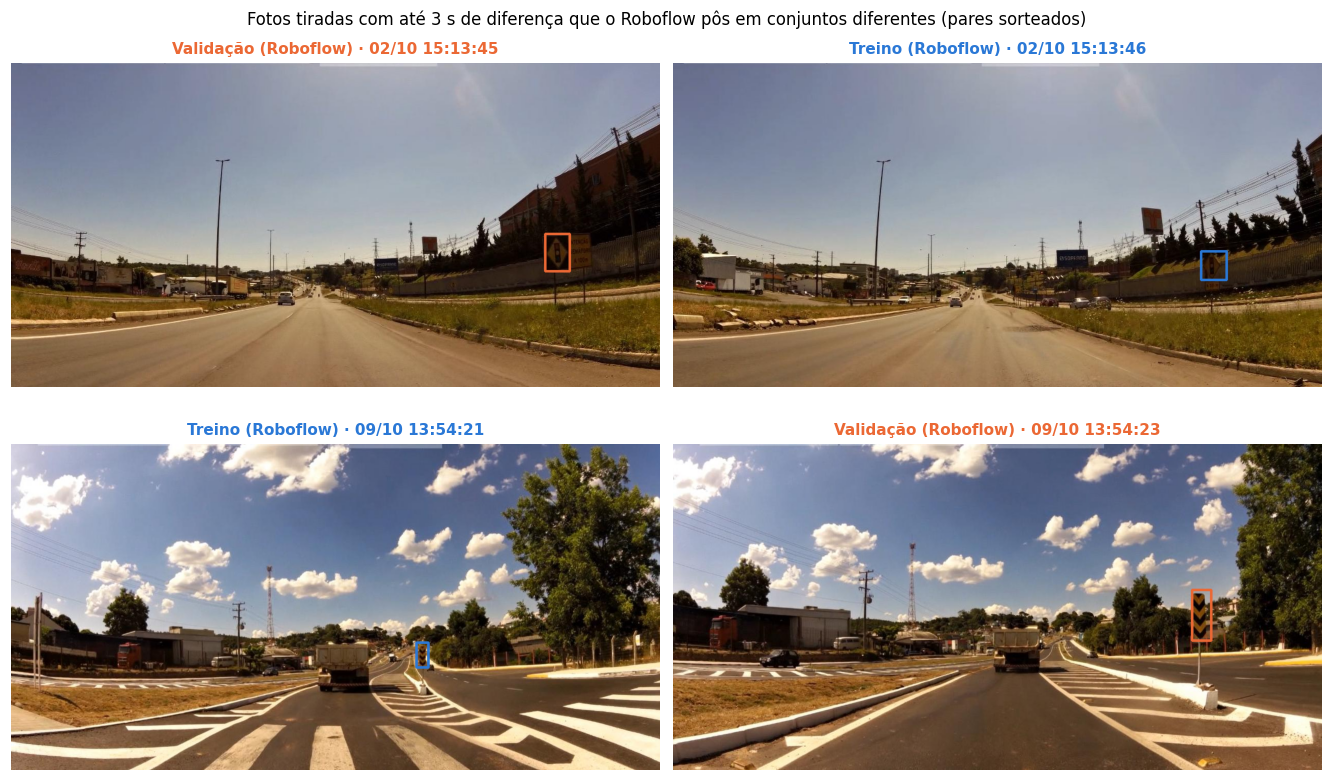

In [9]:
def ler_imagem_com_caixas(caminho: str, cor_hex: str) -> np.ndarray:
    """Imagem RGB com as caixas anotadas desenhadas na cor do conjunto."""
    img = cv2.imdecode(np.fromfile(caminho, dtype=np.uint8), cv2.IMREAD_COLOR)
    alt, larg = img.shape[:2]
    cor = tuple(int(cor_hex[k:k + 2], 16) for k in (5, 3, 1))     # hex -> BGR
    for _, cx, cy, w, h in ler_rotulos(Path(caminho)):
        x0, y0 = int((cx - w / 2) * larg), int((cy - h / 2) * alt)
        x1, y1 = int((cx + w / 2) * larg), int((cy + h / 2) * alt)
        cv2.rectangle(img, (x0 - 4, y0 - 4), (x1 + 4, y1 + 4), cor, 4)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


amostra = PARES.sample(min(2, len(PARES)), random_state=SEMENTE).sort_values("i")
fig, eixos = plt.subplots(len(amostra), 2, figsize=(12, 3.6 * len(amostra)), squeeze=False,
                         layout="constrained")
for linha, (_, par) in zip(eixos, amostra.iterrows()):
    for eixo, idx in zip(linha, (par["i"], par["j"])):
        reg = IMAGENS.loc[idx]
        eixo.imshow(ler_imagem_com_caixas(reg["caminho"], COR_CONJUNTO[reg["conjunto_roboflow"]]))
        eixo.set_title(f"{NOME_CONJUNTO[reg['conjunto_roboflow']]} (Roboflow) · "
                       f"{reg['instante']:%d/%m %H:%M:%S}", color=COR_CONJUNTO[reg["conjunto_roboflow"]],
                       fontweight="bold")
        eixo.axis("off")
fig.suptitle("Fotos tiradas com até 3 s de diferença que o Roboflow pôs em conjuntos diferentes "
             "(pares sorteados)")
salvar_figura(fig, DIR_FIGURAS / "01_vazamento_roboflow.jpg")
plt.show()

Os pares mostram o problema na prática: as duas fotos de cada par são quase a mesma cena,
alguns metros adiante, e caíram em conjuntos diferentes. Avaliar o modelo nessa divisão
mediria a capacidade de lembrar, e não de generalizar. Por isso a divisão do Roboflow é
descartada e refeita por dia.

### 2.3. Uma classe anotada só em metade dos dias

Antes de distribuir os dias, vale conferir se a anotação segue o mesmo critério do começo ao
fim da base. A tabela mostra as classes mais frequentes, dia a dia, e a densidade de anotação
nos dois períodos de gravação.

In [10]:
def periodo(dia: str) -> str:
    return "27/09 a 02/10" if dia <= "2023-10-02" else "05/10 a 11/10"


mais_frequentes = ANOTACOES["classe"].value_counts().head(8).index
POR_DIA = (ANOTACOES[ANOTACOES["classe"].isin(mais_frequentes)]
           .groupby(["dia", "classe"]).size().unstack(fill_value=0)
           .reindex(columns=mais_frequentes, fill_value=0))
POR_DIA.insert(0, "imagens", IMAGENS.groupby("dia").size())
POR_DIA.index = POR_DIA.index.map(dia_curto)

img_periodo = IMAGENS["dia"].map(periodo).value_counts()
anot_periodo = ANOTACOES["dia"].map(periodo)
sem_del = anot_periodo[ANOTACOES["classe"] != "Del"].value_counts()
print("Objetos anotados a cada 100 imagens:")
for p in sorted(img_periodo.index):
    print(f"  {p}: {100 * (anot_periodo == p).sum() / img_periodo[p]:.0f} com o Del, "
          f"{100 * sem_del.get(p, 0) / img_periodo[p]:.0f} sem o Del")
POR_DIA

Objetos anotados a cada 100 imagens:
  05/10 a 11/10: 59 com o Del, 59 sem o Del
  27/09 a 02/10: 89 com o Del, 58 sem o Del


classe,imagens,Del,R-19,I-4,S-14,A-2b,R-1,R-2,LOC-6
dia,,,,,,,,,
27/09,118,68,22,21,1,0,6,8,6
28/09,399,132,48,31,8,13,5,11,13
29/09,634,190,59,22,17,21,15,11,17
02/10,686,179,87,49,20,19,15,28,12
05/10,571,0,36,21,42,38,16,8,19
09/10,152,0,18,8,11,0,9,3,3
10/10,228,0,20,4,16,10,10,9,1
11/10,175,0,11,12,2,3,17,10,10


O delineador (`Del`, o chevron preto e amarelo das curvas) tem de 68 a 190 anotações em cada
um dos quatro primeiros dias e nenhuma nos quatro últimos. As outras classes não mudam: sem o
`Del`, os dois períodos têm praticamente a mesma densidade de anotação. Ou o critério de
anotação mudou no meio da base, ou as estradas gravadas a partir de 05/10 não têm chevrons.
Olhando as fotos, não dá para afirmar qual das duas.

**Decisão: o `Del` sai do modelo.** São três motivos:

1. Não é placa. É um dispositivo auxiliar de sinalização, e o escopo do projeto são as placas.
2. Se o critério de anotação mudou, o modelo receberia lições contraditórias: o mesmo chevron
   como objeto em metade dos dias e como fundo na outra metade.
3. Mantido, ele prende a divisão. Como só existe em quatro dias, ou fica fora da validação, ou
   a divisão perde classes presentes nos três conjuntos (a comparação está na Seção 2.4).

As caixas de `Del` saem dos rótulos, e as imagens que só tinham delineador passam a contar
como fundo.

In [11]:
CLASSES_FORA = ["Del"]
OBJETOS = ANOTACOES[~ANOTACOES["classe"].isin(CLASSES_FORA)].reset_index(drop=True)
IMAGENS["n_objetos_modelo"] = (IMAGENS["arquivo"].map(OBJETOS.groupby("arquivo").size())
                               .fillna(0).astype(int))
so_delineador = ((IMAGENS["n_objetos"] > 0) & (IMAGENS["n_objetos_modelo"] == 0)).sum()
print(f"Objetos anotados: {len(ANOTACOES)} | no modelo: {len(OBJETOS)} "
      f"({len(ANOTACOES) - len(OBJETOS)} delineadores removidos)")
print(f"Imagens que so tinham delineador e passam a ser fundo: {so_delineador}")

Objetos anotados: 2305 | no modelo: 1736 (569 delineadores removidos)
Imagens que so tinham delineador e passam a ser fundo: 376


### 2.4. Regra de distribuição dos dias

A regra usa só as contagens das anotações, nunca o desempenho de um modelo:

1. **Unidade:** o dia. Todas as fotos de um dia vão para o mesmo conjunto.
2. **Tamanhos:** o treino fica com pelo menos 70% das imagens; validação e teste, com pelo
   menos 10% cada.
3. **Classes grandes:** toda classe com 50 objetos ou mais aparece nos três conjuntos. Esta
   condição entrou depois que a primeira versão da busca, ainda com o `Del`, mandou para a
   validação dois dias sem nenhum delineador.
4. **Critério:** o maior número de classes presentes nos três conjuntos. Classe que falta na
   validação não orienta o treino, e classe que falta no teste não pode ser avaliada.
5. **Desempate:** mais objetos anotados no teste, para a medida final ficar mais estável.

Com oito dias, são 3⁸ = 6.561 formas de distribuí-los, e a busca testa todas.

In [12]:
MIN_TREINO, MIN_RETIDO, MIN_CLASSE_GRANDE = 0.70, 0.10, 50


def escolher_divisao(imagens: pd.DataFrame, objetos: pd.DataFrame) -> pd.DataFrame:
    """Todas as distribuicoes validas dos dias, ordenadas pela regra da Secao 2.4."""
    dias = sorted(imagens["dia"].unique())
    img_dia = imagens.groupby("dia").size()
    obj_dia = objetos.groupby("dia").size().reindex(dias, fill_value=0)
    cls_dia = objetos.groupby(["dia", "classe"]).size().unstack(fill_value=0).reindex(dias, fill_value=0)
    grandes = cls_dia.columns[cls_dia.sum() >= MIN_CLASSE_GRANDE]
    candidatos = []
    for atribuicao in itertools.product(range(3), repeat=len(dias)):
        grupos = [[d for d, a in zip(dias, atribuicao) if a == k] for k in range(3)]
        if not all(grupos):
            continue
        fracao = [img_dia[g].sum() / len(imagens) for g in grupos]
        if fracao[0] < MIN_TREINO or min(fracao[1:]) < MIN_RETIDO:
            continue
        presentes = [cls_dia.loc[g].sum() > 0 for g in grupos]
        if not all(p[grandes].all() for p in presentes):
            continue
        candidatos.append({
            "classes_nos_tres": int((presentes[0] & presentes[1] & presentes[2]).sum()),
            "objetos_teste": int(obj_dia[grupos[2]].sum()),
            **{f"%img_{n}": round(100 * f, 1) for n, f in zip(NOMES, fracao)},
            **{f"dias_{n}": ", ".join(dia_curto(d) for d in g) for n, g in zip(NOMES, grupos)},
            "mapa": {d: n for n, g in zip(NOMES, grupos) for d in g},
        })
    return (pd.DataFrame(candidatos)
            .sort_values(["classes_nos_tres", "objetos_teste"], ascending=False, kind="stable")
            .reset_index(drop=True))


CANDIDATOS = escolher_divisao(IMAGENS, OBJETOS)
CANDIDATOS.drop(columns="mapa").to_csv(DIR_SAIDA / "candidatos_divisao.csv", index=False, encoding="utf-8")
MAPA_DIA = CANDIDATOS.loc[0, "mapa"]
IMAGENS["conjunto"] = IMAGENS["dia"].map(MAPA_DIA)
OBJETOS["conjunto"] = OBJETOS["dia"].map(MAPA_DIA)

print(f"{3 ** IMAGENS['dia'].nunique()} distribuicoes testadas, {len(CANDIDATOS)} passam pelas condicoes 1 a 3.")
print("\nAs cinco primeiras pela regra (a primeira e a adotada):")
display(CANDIDATOS.drop(columns="mapa").head(5))

# Mesma busca mantendo o Del, so para mostrar o que ele custaria.
com_del = escolher_divisao(IMAGENS, ANOTACOES).drop(columns="mapa").iloc[0]
print("Melhor divisao possivel se o Del fosse mantido:")
com_del.to_frame("com o Del")

6561 distribuicoes testadas, 14 passam pelas condicoes 1 a 3.

As cinco primeiras pela regra (a primeira e a adotada):


,classes_nos_tres,objetos_teste,%img_treino,%img_validacao,%img_teste,dias_treino,dias_validacao,dias_teste
0,32,263,72.9,13.5,13.6,"27/09, 29/09, 02/10, 05/10, 09/10",28/09,"10/10, 11/10"
1,32,254,72.9,13.6,13.5,"27/09, 29/09, 02/10, 05/10, 09/10","10/10, 11/10",28/09
2,28,307,71.5,13.5,15.0,"29/09, 02/10, 05/10, 10/10",28/09,"27/09, 09/10, 11/10"
3,28,254,71.5,15.0,13.5,"29/09, 02/10, 05/10, 10/10","27/09, 09/10, 11/10",28/09
4,27,357,71.5,11.0,17.4,"29/09, 02/10, 05/10, 10/10","09/10, 11/10","27/09, 28/09"


Melhor divisao possivel se o Del fosse mantido:


,com o Del
classes_nos_tres,29
objetos_teste,386
%img_treino,71.5
%img_validacao,15.0
%img_teste,13.5
dias_treino,"29/09, 02/10, 05/10, 10/10"
dias_validacao,"27/09, 09/10, 11/10"
dias_teste,28/09


### 2.5. Verificação e registro da divisão

Três checagens interrompem a execução se falharem: nenhum dia em mais de um conjunto, nenhum
trecho em mais de um conjunto e nenhum arquivo repetido. A divisão fica gravada em
`outputs/n2/divisao_por_imagem.csv`, uma linha por imagem, para que o treino e a linha de
base usem exatamente as mesmas imagens.

In [13]:
assert IMAGENS.groupby("dia")["conjunto"].nunique().max() == 1, "dia em mais de um conjunto"
assert IMAGENS.groupby("trecho")["conjunto"].nunique().max() == 1, "trecho em mais de um conjunto"
assert IMAGENS["arquivo"].is_unique, "arquivo repetido"
print("Sem vazamento: cada dia, cada trecho e cada arquivo esta em um unico conjunto.\n")

IMAGENS[["arquivo", "dia", "instante", "trecho", "conjunto_roboflow", "conjunto",
         "n_objetos", "n_objetos_modelo"]].to_csv(DIR_SAIDA / "divisao_por_imagem.csv",
                                                  index=False, encoding="utf-8")

RESUMO_DIVISAO = (IMAGENS.groupby("conjunto")
                  .agg(dias=("dia", lambda s: ", ".join(dia_curto(d) for d in sorted(s.unique()))),
                       imagens=("arquivo", "size"), objetos=("n_objetos_modelo", "sum"),
                       sem_objeto=("n_objetos_modelo", lambda s: int((s == 0).sum())))
                  .reindex(list(NOMES)))
RESUMO_DIVISAO["%_imagens"] = (100 * RESUMO_DIVISAO["imagens"] / RESUMO_DIVISAO["imagens"].sum()).round(1)
RESUMO_DIVISAO["%_objetos"] = (100 * RESUMO_DIVISAO["objetos"] / RESUMO_DIVISAO["objetos"].sum()).round(1)
RESUMO_DIVISAO.index = RESUMO_DIVISAO.index.map(NOME_CONJUNTO)
RESUMO_DIVISAO

Sem vazamento: cada dia, cada trecho e cada arquivo esta em um unico conjunto.



,dias,imagens,objetos,sem_objeto,%_imagens,%_objetos
conjunto,,,,,,
Treino,"27/09, 29/09, 02/10, 05/10, 09/10",2161,1219,1050,72.9,70.2
Validação,28/09,399,254,162,13.5,14.6
Teste,"10/10, 11/10",403,263,154,13.6,15.1


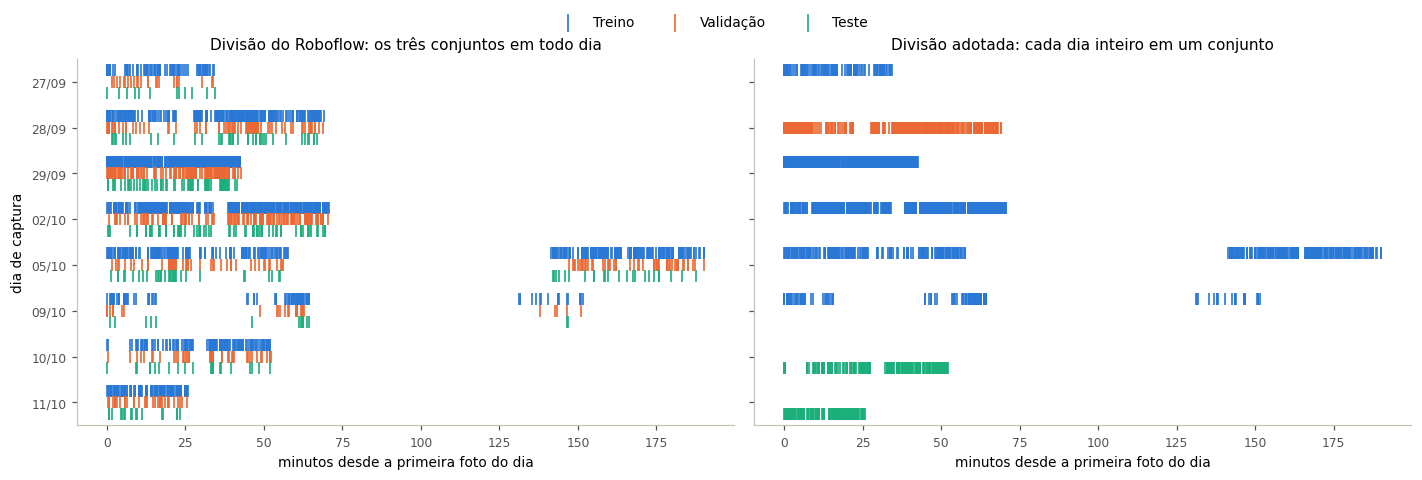

In [14]:
def linha_do_tempo(imagens: pd.DataFrame, coluna: str, eixo, titulo: str):
    """Cada foto e um traco na sua hora do dia; cada dia tem uma faixa por conjunto."""
    dias = sorted(imagens["dia"].unique())
    deslocamento = {"treino": -0.25, "validacao": 0.0, "teste": 0.25}
    for i, dia in enumerate(dias):
        parte = imagens[imagens["dia"] == dia]
        minutos = (parte["instante"] - parte["instante"].min()).dt.total_seconds() / 60
        for nome in NOMES:
            sel = (parte[coluna] == nome).to_numpy()
            eixo.scatter(minutos[sel], np.full(sel.sum(), i + deslocamento[nome]), marker="|",
                         s=60, linewidths=1.1, color=COR_CONJUNTO[nome],
                         label=NOME_CONJUNTO[nome] if i == 0 else None)
    eixo.set_yticks(range(len(dias)), [dia_curto(d) for d in dias])
    eixo.set_ylim(len(dias) - 0.5, -0.5)
    eixo.set_xlabel("minutos desde a primeira foto do dia")
    eixo.set_title(titulo)


fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
linha_do_tempo(IMAGENS, "conjunto_roboflow", eixos[0], "Divisão do Roboflow: os três conjuntos em todo dia")
linha_do_tempo(IMAGENS, "conjunto", eixos[1], "Divisão adotada: cada dia inteiro em um conjunto")
eixos[0].set_ylabel("dia de captura")
alcas, rotulos = eixos[0].get_legend_handles_labels()
fig.legend(alcas, rotulos, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.04),
           markerscale=1.6)
fig.tight_layout()
salvar_figura(fig, DIR_FIGURAS / "02_linha_do_tempo_divisao.png")
plt.show()

---
## 3. Quantidade por classe e desbalanceamento

A contagem é por objeto anotado, já que uma imagem pode ter mais de uma placa, e separada
pelos três conjuntos da divisão adotada. O `Del` já está fora. A tabela completa fica em
`outputs/n2/contagem_por_classe.csv`.

In [15]:
def grupo_da_classe(nome: str) -> str:
    if nome.startswith("R-"):
        return "R (regulamentação)"
    if nome.startswith("A-"):
        return "A (advertência)"
    return "demais códigos"


CLASSES_ESCOPO = [c for c in CLASSES if c not in CLASSES_FORA]
CONTAGEM = (OBJETOS.groupby(["classe", "conjunto"]).size().unstack(fill_value=0)
            .reindex(index=CLASSES_ESCOPO, columns=list(NOMES), fill_value=0))
CONTAGEM["total"] = CONTAGEM.sum(axis=1)
CONTAGEM.insert(0, "grupo", CONTAGEM.index.map(grupo_da_classe))
CONTAGEM = CONTAGEM.sort_values(["total", "treino"], ascending=False, kind="stable")
CONTAGEM.index.name = "classe"
CONTAGEM.to_csv(DIR_SAIDA / "contagem_por_classe.csv", encoding="utf-8")

treino = CONTAGEM["treino"]
duas_maiores = CONTAGEM["total"].nlargest(2)
print(f"Classes no escopo: {len(CONTAGEM)} | presentes no treino: {(treino > 0).sum()}, "
      f"na validacao: {(CONTAGEM['validacao'] > 0).sum()}, no teste: {(CONTAGEM['teste'] > 0).sum()}")
print(f"Maior classe no treino: {treino.idxmax()} com {treino.max()} objetos; "
      f"a classe mediana tem {treino.median():.0f}")
print(f"As duas maiores ({', '.join(duas_maiores.index)}) somam "
      f"{duas_maiores.sum() / CONTAGEM['total'].sum():.0%} dos objetos")
print(f"Classes com menos de 10 objetos no treino: {(treino < 10).sum()} de {len(CONTAGEM)}")
print(f"Classes com um unico objeto na base inteira: {(CONTAGEM['total'] == 1).sum()}")

grupos = CONTAGEM.groupby("grupo")[list(NOMES)].sum()
print("\nComposicao de cada conjunto por grupo de classe (% dos objetos):")
print((100 * grupos / grupos.sum()).round(1).rename(columns=NOME_CONJUNTO).to_string())

pd.set_option("display.max_rows", 100)
CONTAGEM

Classes no escopo: 67 | presentes no treino: 65, na validacao: 39, no teste: 40
Maior classe no treino: R-19 com 222 objetos; a classe mediana tem 4
As duas maiores (R-19, I-4) somam 27% dos objetos
Classes com menos de 10 objetos no treino: 41 de 67
Classes com um unico objeto na base inteira: 10

Composicao de cada conjunto por grupo de classe (% dos objetos):
conjunto            Treino  Validação  Teste
grupo                                       
A (advertência)       28.3       29.5   30.4
R (regulamentação)    39.0       37.4   40.3
demais códigos        32.7       33.1   29.3


conjunto,grupo,treino,validacao,teste,total
classe,,,,,
R-19,R (regulamentação),222,48,31,301
I-4,demais códigos,121,31,16,168
S-14,demais códigos,91,8,18,117
A-2b,A (advertência),78,13,13,104
R-1,R (regulamentação),61,5,27,93
R-2,R (regulamentação),58,11,19,88
LOC-6,demais códigos,57,13,11,81
R-7,R (regulamentação),61,7,9,77
MP,demais códigos,41,10,15,66


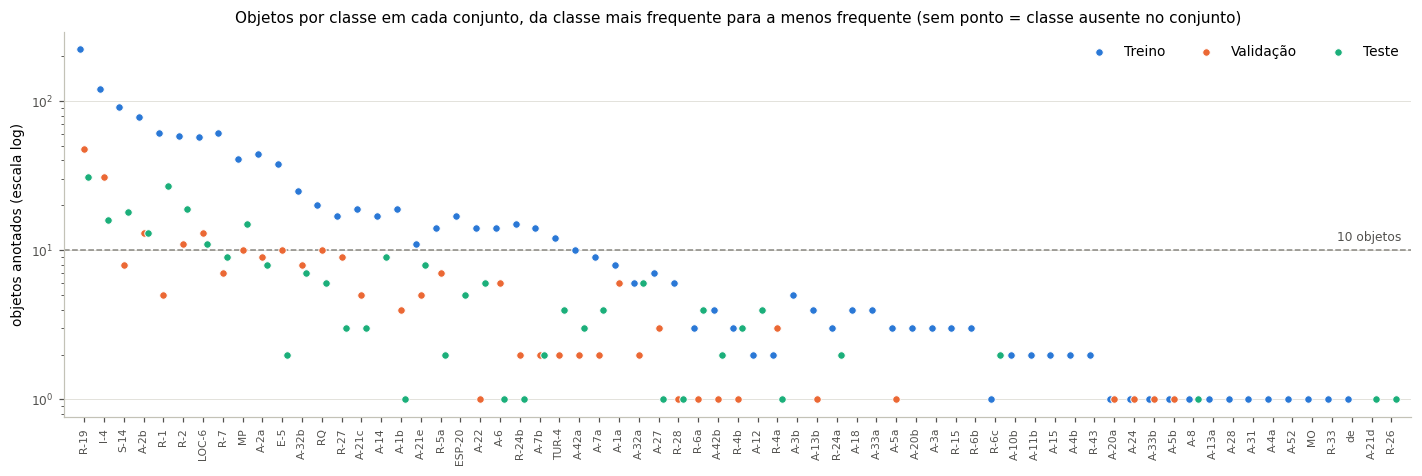

In [16]:
fig, eixo = plt.subplots(figsize=(13, 4.4))
x = np.arange(len(CONTAGEM))
for k, nome in enumerate(NOMES):
    valores = CONTAGEM[nome].to_numpy()
    tem = valores > 0
    eixo.scatter(x[tem] + (k - 1) * 0.22, valores[tem], s=24, color=COR_CONJUNTO[nome],
                 edgecolors="white", linewidths=0.6, zorder=3, label=NOME_CONJUNTO[nome])
eixo.set_yscale("log")
eixo.set_xticks(x, CONTAGEM.index, rotation=90, fontsize=7)
eixo.set_xlim(-1, len(x))
eixo.axhline(10, color="#898781", lw=1, ls="--", zorder=1)
eixo.text(len(x) - 0.5, 11, "10 objetos", ha="right", va="bottom", fontsize=8, color="#52514e")
eixo.grid(axis="y", color="#e1e0d9", lw=0.6)
eixo.set_axisbelow(True)
eixo.set_ylabel("objetos anotados (escala log)")
eixo.set_title("Objetos por classe em cada conjunto, da classe mais frequente para a menos frequente "
               "(sem ponto = classe ausente no conjunto)")
eixo.legend(frameon=False, ncol=3, loc="upper right")
fig.tight_layout()
salvar_figura(fig, DIR_FIGURAS / "03_objetos_por_classe.png")
plt.show()

O desbalanceamento é forte, e aparece de três formas:

- **Poucas classes concentram os exemplos.** `R-19` (velocidade máxima) e `I-4` somam 27% dos
  objetos, enquanto a classe mediana tem só 4 exemplos no treino.
- **A cauda é longa.** 41 das 67 classes têm menos de 10 exemplos no treino, e 10 aparecem uma
  única vez na base inteira.
- **Metade das imagens de treino é só fundo.** São 1.050 de 2.161, contando as 376 que só
  tinham delineador. Fundo ensina o modelo a não ver placa em tudo, mas em excesso puxa o
  recall para baixo. Quanto dele entra no treino fica para a montagem da base de treino.

A composição por grupo, por outro lado, ficou parecida nos três conjuntos (saída acima):
regulamentação, advertência e os demais códigos têm quase a mesma participação no treino, na
validação e no teste.

### 3.1. Quais classes o modelo aprende

Uma classe com dois ou três exemplos não ensina nada ao modelo e não pode ser medida no
teste. A tabela mostra, para cada mínimo de exemplos no treino, quantas classes ficariam e
quantos objetos elas cobririam. As classes abaixo do mínimo não são descartadas: viram uma
classe única, `outra_placa`, que o modelo continua tendo de encontrar.

In [17]:
CORTES = pd.DataFrame([{
    "minimo_no_treino": n,
    "classes_mantidas": int((treino >= n).sum()),
    "%_objetos_cobertos": round(100 * CONTAGEM.loc[treino >= n, "total"].sum() / CONTAGEM["total"].sum(), 1),
    "mantidas_com_exemplo_na_validacao": int(((treino >= n) & (CONTAGEM["validacao"] > 0)).sum()),
    "mantidas_com_exemplo_no_teste": int(((treino >= n) & (CONTAGEM["teste"] > 0)).sum()),
} for n in (5, 10, 20, 30)])
CORTES.to_csv(DIR_SAIDA / "cortes_de_classe.csv", index=False, encoding="utf-8")
CORTES

,minimo_no_treino,classes_mantidas,%_objetos_cobertos,mantidas_com_exemplo_na_validacao,mantidas_com_exemplo_no_teste
0,5,32,94.2,29,30
1,10,26,90.3,24,26
2,20,13,73.8,13,13
3,30,11,69.5,11,11


**Decisão: mínimo de 10 exemplos no treino.** Ficam 26 classes de placa, que cobrem 90% dos
objetos, e todas têm pelo menos um exemplo no teste. As outras 41 classes, com 168 objetos,
viram `outra_placa`. Com mínimo 5, entrariam classes de cinco a nove exemplos, pouco para
aprender e para medir. Com 20, metade das classes viraria `outra_placa`, que deixaria de ser
uma sobra e passaria a ser uma classe grande e misturada.

Duas das classes mantidas, `A-14` e `ESP-20`, não aparecem no dia da validação. Elas continuam
no treino e no teste; só não dá para acompanhar o desempenho delas durante o treino.

In [18]:
MIN_EXEMPLOS_TREINO = 10
OUTRA = "outra_placa"

CLASSES_MODELO = list(CONTAGEM.index[treino >= MIN_EXEMPLOS_TREINO]) + [OUTRA]
CLASSE_DO_MODELO = {c: (c if c in CLASSES_MODELO else OUTRA) for c in CLASSES_ESCOPO}
OBJETOS["classe_modelo"] = OBJETOS["classe"].map(CLASSE_DO_MODELO)

pd.Series(CLASSE_DO_MODELO, name="classe_modelo").rename_axis("classe_original").to_csv(
    DIR_SAIDA / "classes_do_modelo.csv", encoding="utf-8")

CONTAGEM_MODELO = (OBJETOS.groupby(["classe_modelo", "conjunto"]).size().unstack(fill_value=0)
                   .reindex(index=CLASSES_MODELO, columns=list(NOMES), fill_value=0))
CONTAGEM_MODELO["total"] = CONTAGEM_MODELO.sum(axis=1)
CONTAGEM_MODELO.index.name = "classe_modelo"
CONTAGEM_MODELO.to_csv(DIR_SAIDA / "contagem_classes_do_modelo.csv", encoding="utf-8")

agrupadas = [c for c, m in CLASSE_DO_MODELO.items() if m == OUTRA]
t = CONTAGEM_MODELO["treino"].drop(OUTRA)
print(f"Classes do modelo: {len(CLASSES_MODELO)} ({len(CLASSES_MODELO) - 1} placas + {OUTRA})")
print(f"Viram {OUTRA}: {len(agrupadas)} classes, {CONTAGEM_MODELO.loc[OUTRA, 'total']} objetos")
print(f"Desbalanceamento no treino: a maior classe ({t.idxmax()}, {t.max()}) tem "
      f"{t.max() / t.min():.0f} vezes os exemplos da menor ({t.idxmin()}, {t.min()})")
faltam = {NOME_CONJUNTO[n]: list(CONTAGEM_MODELO.index[CONTAGEM_MODELO[n] == 0]) for n in NOMES}
print("Classes do modelo ausentes em algum conjunto:", {k: v for k, v in faltam.items() if v} or "nenhuma")
CONTAGEM_MODELO

Classes do modelo: 27 (26 placas + outra_placa)
Viram outra_placa: 41 classes, 168 objetos
Desbalanceamento no treino: a maior classe (R-19, 222) tem 22 vezes os exemplos da menor (A-42a, 10)
Classes do modelo ausentes em algum conjunto: {'Validação': ['A-14', 'ESP-20']}


conjunto,treino,validacao,teste,total
classe_modelo,,,,
R-19,222,48,31,301
I-4,121,31,16,168
S-14,91,8,18,117
A-2b,78,13,13,104
R-1,61,5,27,93
R-2,58,11,19,88
LOC-6,57,13,11,81
R-7,61,7,9,77
MP,41,10,15,66


---
## 4. Base no formato do YOLO

O YOLO lê uma pasta por conjunto, com `images/` e `labels/` lado a lado, e um `data.yaml` com
os nomes das classes. A base é montada a partir da divisão da Seção 2 e das classes da Seção
3.1:

- **Rótulos refeitos.** Cada linha recebe o número da classe do modelo (26 placas e
  `outra_placa`). As caixas de `Del` saem, e os cinco polígonos da base viram caixa.
- **Imagens sem cópia.** Cada imagem entra como *hard link* do arquivo baixado, então a base
  não ocupa espaço de novo. Se o sistema não permitir, a imagem é copiada.
- **Fundo no treino.** Depois da saída do `Del`, metade das imagens de treino não tem placa
  nenhuma. A documentação do Ultralytics recomenda de 0 a 10% de imagens de fundo, o
  suficiente para reduzir falso positivo sem ensinar o modelo a dizer "não tem placa" o tempo
  todo. O treino fica com todas as imagens anotadas e uma amostra sorteada de fundo, que
  completa 10% do conjunto. A proporção é um hiperparâmetro e pode voltar à mesa na Ex2.
- **Validação e teste inteiros.** Nesses dois conjuntos entram todas as imagens, com ou sem
  placa. Na estrada, a maioria dos quadros não tem placa, e a precisão só é honesta se o
  modelo também for medido neles.

In [19]:
FRACAO_FUNDO_TREINO = 0.10
DIR_YOLO = DIR_DATASET.parent / "n2_yolo"       # ao lado da base baixada, fora do Git
ID_CLASSE = {nome: i for i, nome in enumerate(CLASSES_MODELO)}


def vincular(origem: Path, destino: Path):
    """Hard link quando o sistema permite (nao duplica as imagens); senao, copia."""
    try:
        os.link(origem, destino)
    except OSError:
        shutil.copy2(origem, destino)


def selecionar_imagens(imagens: pd.DataFrame) -> pd.DataFrame:
    """Validacao e teste inteiros; no treino, as anotadas e uma amostra de fundo."""
    treino = imagens[imagens["conjunto"] == "treino"]
    com_placa = treino[treino["n_objetos_modelo"] > 0]
    fundo = treino[treino["n_objetos_modelo"] == 0]
    n_fundo = round(FRACAO_FUNDO_TREINO / (1 - FRACAO_FUNDO_TREINO) * len(com_placa))
    fundo = fundo.sample(min(n_fundo, len(fundo)), random_state=SEMENTE)
    return pd.concat([com_placa, fundo, imagens[imagens["conjunto"] != "treino"]])


def linhas_do_rotulo(img: Path) -> list[str]:
    """Rotulo YOLO na numeracao do modelo, sem as classes fora do escopo."""
    linhas = []
    for c, cx, cy, w, h in ler_rotulos(img):
        nome = CLASSES[c] if c < len(CLASSES) else str(c)
        if nome in CLASSES_FORA:
            continue
        x0, y0 = max(0.0, cx - w / 2), max(0.0, cy - h / 2)    # garante caixa dentro da imagem
        x1, y1 = min(1.0, cx + w / 2), min(1.0, cy + h / 2)
        linhas.append(f"{ID_CLASSE[CLASSE_DO_MODELO[nome]]} {(x0 + x1) / 2:.6f} {(y0 + y1) / 2:.6f} "
                      f"{x1 - x0:.6f} {y1 - y0:.6f}")
    return linhas


def montar_base_yolo(imagens: pd.DataFrame, destino: Path) -> Path:
    """Cria destino/<conjunto>/{images,labels} e o data.yaml. Refaz do zero a cada execucao."""
    if destino.exists():
        shutil.rmtree(destino)
    for nome in NOMES:
        for sub in ("images", "labels"):
            (destino / nome / sub).mkdir(parents=True)
    for reg in imagens.itertuples():
        origem = Path(reg.caminho)
        pasta = destino / reg.conjunto
        vincular(origem, pasta / "images" / origem.name)
        linhas = linhas_do_rotulo(origem)
        (pasta / "labels" / f"{origem.stem}.txt").write_text(
            "".join(f"{l}\n" for l in linhas), encoding="utf-8")
    arq_yaml = destino / "data.yaml"
    arq_yaml.write_text(yaml.safe_dump({
        "path": str(destino), "train": "treino/images", "val": "validacao/images",
        "test": "teste/images", "names": dict(enumerate(CLASSES_MODELO)),
    }, allow_unicode=True, sort_keys=False), encoding="utf-8")
    return arq_yaml


inicio = time.time()
IMAGENS_YOLO = selecionar_imagens(IMAGENS)
ARQ_DATA_YAML = montar_base_yolo(IMAGENS_YOLO, DIR_YOLO)
print(f"Base YOLO montada em {time.time() - inicio:.0f} s: {DIR_YOLO.name}/ ({len(IMAGENS_YOLO)} imagens)")

Base YOLO montada em 1 s: n2_yolo/ (2036 imagens)


A verificação abaixo relê os rótulos gravados, e não as tabelas da memória. Se a contagem de
qualquer classe, em qualquer conjunto, não bater com a da Seção 3.1, a execução para.

In [20]:
def contar_rotulos(destino: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Objetos por classe e resumo por conjunto, lidos dos arquivos gravados."""
    contagem, resumo = {}, []
    for nome in NOMES:
        arquivos = sorted((destino / nome / "labels").glob("*.txt"))
        ids = [int(l.split()[0]) for a in arquivos for l in a.read_text(encoding="utf-8").splitlines()]
        contagem[nome] = pd.Series(ids).map(dict(enumerate(CLASSES_MODELO))).value_counts()
        vazios = sum(1 for a in arquivos if not a.read_text(encoding="utf-8").strip())
        imagens = len(list((destino / nome / "images").iterdir()))
        resumo.append({"conjunto": NOME_CONJUNTO[nome], "imagens": imagens, "com_placa": imagens - vazios,
                       "fundo": vazios, "%_fundo": round(100 * vazios / imagens, 1), "objetos": len(ids)})
    tabela = pd.DataFrame(contagem).reindex(CLASSES_MODELO).fillna(0).astype(int)
    return tabela, pd.DataFrame(resumo).set_index("conjunto")


CONTAGEM_YOLO, RESUMO_YOLO = contar_rotulos(DIR_YOLO)
diferenca = CONTAGEM_YOLO - CONTAGEM_MODELO[list(NOMES)]
assert (diferenca == 0).all().all(), f"contagem diferente:\n{diferenca[(diferenca != 0).any(axis=1)]}"
print("Rotulos conferidos: as contagens por classe batem com a Secao 3.1 nos tres conjuntos.\n")
RESUMO_YOLO.to_csv(DIR_SAIDA / "base_yolo_resumo.csv", encoding="utf-8")
RESUMO_YOLO

Rotulos conferidos: as contagens por classe batem com a Secao 3.1 nos tres conjuntos.



,imagens,com_placa,fundo,%_fundo,objetos
conjunto,,,,,
Treino,1234,1111,123,10.0,1219
Validação,399,237,162,40.6,254
Teste,403,249,154,38.2,263


---
## 5. Linha de base clássica: o pipeline da N1 no conjunto de teste

Sem esse número não dá para dizer quanto o modelo ganha. A linha de base é o pipeline da N1
**exatamente como foi entregue**:

- **O código** vem do próprio notebook da N1. A célula abaixo executa só as células que
  definem o pipeline, e para se alguma delas tentar rodar outra coisa além de definições.
- **Os parâmetros** vêm do registro congelado da N1, `outputs/parametros_adotados.json`.
  Nada é recalibrado.
- **As imagens e o gabarito** são os do modelo: as 403 imagens dos dias de teste e os
  rótulos gravados na Seção 4, sem o `Del`.
- **O casamento** entre detecção e anotação é o da N1: guloso, da maior sobreposição (IoU)
  para a menor, uma detecção para cada anotação.

O pipeline clássico localiza placas, mas não diz qual é a placa. Por isso a comparação justa
é a de **detecção**: acertar onde há uma placa, qualquer que seja a classe. A medida sai em
dois cortes de sobreposição: IoU ≥ 0,50, o padrão dos detectores (é o corte do mAP50), e
IoU ≥ 0,30, o critério da N1.

Uma ressalva: na N1, a divisão entre ajuste e validação foi feita por trecho, e alguns trechos
dos dias de teste participaram da calibração. Se isso favorece alguém, favorece a linha de
base, então o ganho que o modelo mostrar contra ela é um ganho mínimo.

In [21]:
FUNCOES_N1 = {"Parametros", "carregar_imagem", "redimensionar", "corrigir_iluminacao_clahe",
              "suavizar", "mapa_evidencia_cromatica", "limiarizar", "limpar_mascara",
              "extrair_contornos", "executar_pipeline", "casar_deteccoes"}


def carregar_pipeline_n1(arquivo_nb: Path) -> dict:
    """Executa so as celulas da N1 que definem o pipeline e devolve o escopo com as funcoes."""
    nb_n1 = json.loads(Path(arquivo_nb).read_text(encoding="utf-8"))
    escopo = {"cv2": cv2, "np": np, "pd": pd, "math": math, "time": time, "Path": Path,
              "dataclass": dataclass, "field": field, "asdict": asdict}
    definidas = set()
    for celula in nb_n1["cells"]:
        if celula["cell_type"] != "code":
            continue
        fonte = "".join(celula["source"])
        corpo = ast.parse(fonte).body
        nomes = {n.name for n in corpo if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
        if not nomes & FUNCOES_N1:
            continue
        so_definicoes = all(isinstance(n, (ast.FunctionDef, ast.ClassDef, ast.Import,
                                           ast.ImportFrom, ast.Assign)) for n in corpo)
        if not so_definicoes:
            raise RuntimeError(f"celula da N1 com {sorted(nomes)} executa algo alem de definicoes")
        exec(compile(fonte, "<checkpoint1>", "exec"), escopo)
        definidas |= nomes
    faltam = FUNCOES_N1 - definidas
    if faltam:
        raise RuntimeError(f"funcoes da N1 nao encontradas: {sorted(faltam)}")
    return escopo


N1 = carregar_pipeline_n1(RAIZ / "notebooks" / "checkpoint1_pipeline_pdi.ipynb")
REGISTRO_N1 = json.loads((RAIZ / "outputs" / "parametros_adotados.json").read_text(encoding="utf-8"))
_dados = dict(REGISTRO_N1["parametros_adotados"])
_dados["razao_aspecto"] = tuple(_dados["razao_aspecto"])
PARAMS_N1 = N1["Parametros"](**_dados)

print(f"Pipeline da N1 carregado ({len(FUNCOES_N1)} funcoes) | parametros de {REGISTRO_N1['gerado_em']}")
print(f"  limiarizacao {PARAMS_N1.metodo_limiar} (limiar {PARAMS_N1.limiar_global}) | "
      f"kernels {PARAMS_N1.k_abertura}x{PARAMS_N1.k_abertura} e {PARAMS_N1.k_fechamento}x{PARAMS_N1.k_fechamento} | "
      f"area {PARAMS_N1.area_minima} a {PARAMS_N1.area_maxima} px2")

Pipeline da N1 carregado (11 funcoes) | parametros de 2026-09-22 16:49:34
  limiarizacao global (limiar 96) | kernels 3x3 e 9x9 | area 479 a 12887 px2


Antes de medir, uma conferência: o pipeline carregado tem de reproduzir a N1. A célula abaixo
roda nas 250 imagens da validação da N1 e compara, imagem por imagem, o número de detecções
com o que a N1 gravou em `outputs/avaliacao_por_imagem.csv`.

In [22]:
ref_n1 = pd.read_csv(RAIZ / "outputs" / "avaliacao_por_imagem.csv")
caminho_de = dict(zip(IMAGENS["arquivo"], IMAGENS["caminho"]))
agora = [len(N1["executar_pipeline"](caminho_de[a], PARAMS_N1)["objetos"]) for a in ref_n1["imagem"]]
iguais = int((ref_n1["detectados"].to_numpy() == np.array(agora)).sum())
print(f"Deteccoes iguais as da N1: {iguais} de {len(ref_n1)} imagens "
      f"({int(ref_n1['detectados'].sum())} na N1, {sum(agora)} agora)")
assert iguais == len(ref_n1), "o pipeline carregado nao reproduz a N1"

Deteccoes iguais as da N1: 250 de 250 imagens (208 na N1, 208 agora)


In [23]:
def ler_caixas(arq_rotulo: Path) -> list[tuple]:
    """Caixas (x, y, w, h) normalizadas de um rotulo YOLO; a classe e ignorada."""
    caixas = []
    for linha in arq_rotulo.read_text(encoding="utf-8").splitlines():
        _, cx, cy, w, h = (float(v) for v in linha.split()[:5])
        caixas.append((cx - w / 2, cy - h / 2, w, h))
    return caixas


def avaliar_deteccao(deteccoes: dict, gabarito: dict, limiar_iou: float) -> dict:
    """Precisao, recall e F1 de deteccao (sem olhar a classe), somando todas as imagens."""
    vp = fp = fn = 0
    for arquivo, anotadas in gabarito.items():
        a, b, c = N1["casar_deteccoes"](deteccoes.get(arquivo, []), anotadas, limiar_iou)
        vp, fp, fn = vp + a, fp + b, fn + c
    precisao = vp / (vp + fp) if vp + fp else 0.0
    recall = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall else 0.0
    return {"precisao": round(precisao, 3), "recall": round(recall, 3), "f1": round(f1, 3),
            "vp": vp, "fp": fp, "fn": fn}


def detectar_classico(caminho: Path) -> list[tuple]:
    """Caixas do pipeline da N1, normalizadas pelo tamanho da imagem de trabalho."""
    resultado = N1["executar_pipeline"](caminho, PARAMS_N1)
    altura, largura = resultado["dimensoes_trabalho"]
    return [(o["x"] / largura, o["y"] / altura, o["w"] / largura, o["h"] / altura)
            for o in resultado["objetos"]]


pasta_teste = DIR_YOLO / "teste"
GABARITO_TESTE = {img.name: ler_caixas(pasta_teste / "labels" / f"{img.stem}.txt")
                  for img in sorted((pasta_teste / "images").iterdir())}

inicio = time.time()
DET_CLASSICO = {nome: detectar_classico(pasta_teste / "images" / nome) for nome in GABARITO_TESTE}
segundos = time.time() - inicio
print(f"{len(DET_CLASSICO)} imagens de teste processadas em {segundos:.0f} s "
      f"({1000 * segundos / len(DET_CLASSICO):.0f} ms por imagem)")
print(f"Placas anotadas: {sum(map(len, GABARITO_TESTE.values()))} | "
      f"deteccoes do pipeline: {sum(map(len, DET_CLASSICO.values()))}")

403 imagens de teste processadas em 29 s (73 ms por imagem)
Placas anotadas: 263 | deteccoes do pipeline: 313


In [24]:
LINHA_DE_BASE = pd.DataFrame({f"IoU >= {l:.2f}": avaliar_deteccao(DET_CLASSICO, GABARITO_TESTE, l)
                              for l in (0.30, 0.50)})

pd.DataFrame([{"arquivo": a, "placas_anotadas": len(g), "deteccoes": len(DET_CLASSICO[a]),
               **{f"vp_iou_{l:.2f}": N1["casar_deteccoes"](DET_CLASSICO[a], g, l)[0] for l in (0.30, 0.50)}}
              for a, g in GABARITO_TESTE.items()]).to_csv(
    DIR_SAIDA / "linha_de_base_por_imagem.csv", index=False, encoding="utf-8")
(DIR_SAIDA / "linha_de_base.json").write_text(json.dumps({
    "descricao": "Pipeline classico da N1, parametros congelados, deteccao sem classe",
    "parametros": "outputs/parametros_adotados.json",
    "conjunto": "teste", "dias": RESUMO_DIVISAO.loc["Teste", "dias"],
    "imagens": len(GABARITO_TESTE), "placas_anotadas": int(sum(map(len, GABARITO_TESTE.values()))),
    "metricas": LINHA_DE_BASE.to_dict(),
}, ensure_ascii=False, indent=2), encoding="utf-8")
LINHA_DE_BASE

,IoU >= 0.30,IoU >= 0.50
precisao,0.115,0.099
recall,0.137,0.118
f1,0.125,0.108
vp,36.000,31.000
fp,277.000,282.000
fn,227.000,232.000


**No teste, a linha de base tem F1 de 0,125 com IoU ≥ 0,30 e de 0,108 com IoU ≥ 0,50.** Das
263 placas dos dois dias de teste, o pipeline encontra 36 (31 no corte mais exigente), e 277
das suas 313 detecções não são placa. É esse o número que o modelo precisa superar, medido nas
mesmas imagens, com o mesmo gabarito e o mesmo casamento.

O valor fica abaixo do F1 de 0,201 da N1, e a diferença não vem do código: a conferência acima
mostra que o pipeline reproduz a N1 imagem por imagem. O que muda é o conjunto de imagens, como
mostra a seção seguinte. Vale também a ressalva da N1: a base tem placas sem anotação, e cada
uma que o pipeline acerta conta como falso positivo, então a precisão medida é um piso.

### 5.1. A linha de base muda muito de um dia para outro

A mesma linha de base, rodada em cada dia da base inteira, com o mesmo gabarito sem `Del` e
IoU ≥ 0,30. É um diagnóstico, e não uma avaliação: nos dias de treino ninguém foi treinado,
mas a N1 calibrou os parâmetros com trechos de todos os dias.

In [25]:
def gabarito_sem_fora(caminho: str) -> list[tuple]:
    """Caixas (x, y, w, h) normalizadas das anotacoes, sem as classes fora do escopo."""
    return [(cx - w / 2, cy - h / 2, w, h) for c, cx, cy, w, h in ler_rotulos(Path(caminho))
            if (CLASSES[c] if c < len(CLASSES) else str(c)) not in CLASSES_FORA]


inicio = time.time()
linhas = []
for reg in IMAGENS.itertuples():
    det = DET_CLASSICO.get(reg.arquivo) if reg.conjunto == "teste" else detectar_classico(Path(reg.caminho))
    vp, fp, fn = N1["casar_deteccoes"](det, gabarito_sem_fora(reg.caminho), 0.30)
    linhas.append({"dia": reg.dia, "conjunto": NOME_CONJUNTO[reg.conjunto], "vp": vp, "fp": fp, "fn": fn})
POR_DIA_BASE = pd.DataFrame(linhas).groupby(["dia", "conjunto"])[["vp", "fp", "fn"]].sum()
POR_DIA_BASE["precisao"] = (POR_DIA_BASE["vp"] / (POR_DIA_BASE["vp"] + POR_DIA_BASE["fp"])).round(3)
POR_DIA_BASE["recall"] = (POR_DIA_BASE["vp"] / (POR_DIA_BASE["vp"] + POR_DIA_BASE["fn"])).round(3)
POR_DIA_BASE["f1"] = (2 * POR_DIA_BASE["precisao"] * POR_DIA_BASE["recall"]
                      / (POR_DIA_BASE["precisao"] + POR_DIA_BASE["recall"])).fillna(0).round(3)
POR_DIA_BASE = POR_DIA_BASE.reset_index()
POR_DIA_BASE["dia"] = POR_DIA_BASE["dia"].map(dia_curto)
POR_DIA_BASE.to_csv(DIR_SAIDA / "linha_de_base_por_dia.csv", index=False, encoding="utf-8")
total = POR_DIA_BASE[["vp", "fp", "fn"]].sum()
p, r = total["vp"] / (total["vp"] + total["fp"]), total["vp"] / (total["vp"] + total["fn"])
print(f"{len(IMAGENS)} imagens em {time.time() - inicio:.0f} s | base inteira: precisao {p:.3f}, "
      f"recall {r:.3f}, F1 {2 * p * r / (p + r):.3f}\n")
POR_DIA_BASE.set_index("dia")

2963 imagens em 189 s | base inteira: precisao 0.151, recall 0.172, F1 0.161



,conjunto,vp,fp,fn,precisao,recall,f1
dia,,,,,,,
27/09,Treino,8,106,95,0.070,0.078,0.074
28/09,Validação,40,275,214,0.127,0.157,0.140
29/09,Treino,81,233,250,0.258,0.245,0.251
02/10,Treino,55,296,327,0.157,0.144,0.150
05/10,Treino,71,392,246,0.153,0.224,0.182
09/10,Treino,7,99,79,0.066,0.081,0.073
10/10,Teste,13,181,132,0.067,0.090,0.077
11/10,Teste,23,96,95,0.193,0.195,0.194


O F1 da linha de base vai de 0,07 a 0,25 conforme o dia, e na base inteira fica em 0,161, o
mesmo valor que a N1 mediu nas 934 imagens da validação dela. Os dois dias de teste juntam um
dos piores dias para o clássico (10/10) com um dos melhores (11/10). Por isso o número do teste
só vale comparado com o do modelo nas mesmas imagens, e nunca com o da N1, que saiu de outras.

---
## 6. Aumento de dados

O aumento de dados cria, durante o treino, variações das imagens de treino. A regra aqui é só
usar transformação que acontece na operação real: uma câmera presa no carro, filmando a
estrada de dia, com sol, sombra e placas a distâncias diferentes. O ponto de partida são os
padrões do Ultralytics, e cada valor que muda sai de uma medição nas placas do treino ou de
uma propriedade das classes.

A célula abaixo mede as três variações que importam, só nas placas do treino:

- **Saturação e brilho dentro da mesma classe.** Cada placa é comparada com a mediana da sua
  própria classe. A variação entre classes (o miolo branco de uma `R-19` contra o amarelo de
  uma `A-2b`) não interessa, porque o modelo precisa aprender essa diferença, e não
  apagá-la. O que interessa é quanto a mesma placa muda de uma foto para outra: sombra,
  contraluz, tinta desbotada.
- **Tamanho.** O lado de cada caixa, em pixels, na resolução de treino de 1.280 px, que muda
  com a distância até a placa.

A medida usa o miolo da caixa (60% central), para pegar a placa e não o fundo em volta.

In [26]:
# Versao fixa: a mesma em que a tabela de aumento de dados e o teste do codigo foram feitos.
garantir_pacote("ultralytics", "ultralytics==8.4.182")
from ultralytics.cfg import DEFAULT_CFG_DICT
import ultralytics

IMGSZ = 1280


def medir_variacoes(pasta: Path) -> pd.DataFrame:
    """Saturacao e brilho medianos do miolo de cada placa e o lado da caixa a 1.280 px."""
    linhas = []
    for rotulo in sorted((pasta / "labels").glob("*.txt")):
        texto = rotulo.read_text(encoding="utf-8").split("\n")
        caixas = [l.split() for l in texto if l.strip()]
        if not caixas:
            continue
        bgr = cv2.imdecode(np.fromfile(str(pasta / "images" / f"{rotulo.stem}.jpg"), np.uint8), cv2.IMREAD_COLOR)
        alt, larg = bgr.shape[:2]
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        for k, cx, cy, w, h in caixas:
            cx, cy, w, h = float(cx), float(cy), float(w), float(h)
            x0, x1 = int((cx - 0.3 * w) * larg), int((cx + 0.3 * w) * larg)
            y0, y1 = int((cy - 0.3 * h) * alt), int((cy + 0.3 * h) * alt)
            if x1 <= x0 or y1 <= y0:
                continue
            miolo = hsv[y0:y1, x0:x1].reshape(-1, 3)
            linhas.append({"classe": CLASSES_MODELO[int(k)], "S": float(np.median(miolo[:, 1])),
                           "V": float(np.median(miolo[:, 2])),
                           "lado_px": math.sqrt(w * larg * h * alt) * IMGSZ / larg})
    return pd.DataFrame(linhas)


def relativo_a_classe(tabela: pd.DataFrame, coluna: str) -> pd.Series:
    """Valor de cada placa dividido pela mediana da sua classe (sem outra_placa, que mistura classes)."""
    t = tabela[(tabela["classe"] != OUTRA) & (tabela[coluna] > 0)]
    return t[coluna] / t.groupby("classe")[coluna].transform("median")


def ganho_para(p5: float) -> float:
    """Menor ganho, em passos de 0,05, que leva o fator ate o percentil 5 medido."""
    return math.ceil(round((1 - p5) * 20, 6)) / 20


VARIACOES = medir_variacoes(DIR_YOLO / "treino")
rel_s, rel_v = relativo_a_classe(VARIACOES, "S"), relativo_a_classe(VARIACOES, "V")
lado = VARIACOES["lado_px"]
MEDIDAS = {
    "saturacao_p5": round(rel_s.quantile(0.05), 2), "saturacao_p95": round(rel_s.quantile(0.95), 2),
    "brilho_p5": round(rel_v.quantile(0.05), 2), "brilho_p95": round(rel_v.quantile(0.95), 2),
    "lado_p5": round(lado.quantile(0.05), 1), "lado_p10": round(lado.quantile(0.10), 1),
    "lado_mediana": round(lado.median(), 1), "lado_p95": round(lado.quantile(0.95), 1),
}
print(f"{len(VARIACOES)} placas do treino medidas | Ultralytics {ultralytics.__version__}\n")
print(f"Saturacao, relativa a mediana da classe: percentil 5 = {MEDIDAS['saturacao_p5']}x, "
      f"percentil 95 = {MEDIDAS['saturacao_p95']}x")
print(f"Brilho, relativo a mediana da classe   : percentil 5 = {MEDIDAS['brilho_p5']}x, "
      f"percentil 95 = {MEDIDAS['brilho_p95']}x")
print(f"Lado da placa a {IMGSZ} px              : percentil 5 = {MEDIDAS['lado_p5']} px, "
      f"mediana = {MEDIDAS['lado_mediana']} px, percentil 95 = {MEDIDAS['lado_p95']} px")

1219 placas do treino medidas | Ultralytics 8.4.182

Saturacao, relativa a mediana da classe: percentil 5 = 0.46x, percentil 95 = 1.62x
Brilho, relativo a mediana da classe   : percentil 5 = 0.53x, percentil 95 = 2.56x
Lado da placa a 1280 px              : percentil 5 = 18.6 px, mediana = 42.5 px, percentil 95 = 116.7 px


Com as medidas, cada transformação recebe um valor e um motivo. A tabela compara com o padrão
da versão instalada do Ultralytics.

O Ultralytics aplica saturação e brilho multiplicando o canal por um fator sorteado entre
`1 − ganho` e `1 + ganho`. O ganho escolhido é o menor que alcança o percentil 5 medido, ou
seja, a placa mais apagada ou mais escura que ainda é comum na base. O lado de cima não
precisa de mais: brilho alto satura em 255, e a placa contra o sol ou na sombra é que é o caso
difícil.

In [27]:
faixas_n1 = {f["nome"]: f for f in REGISTRO_N1["parametros_adotados"]["faixas"]}
distancia_matiz = abs(faixas_n1["vermelho"]["h_centro"] - faixas_n1["amarelo"]["h_centro"])
HSV_H = DEFAULT_CFG_DICT["hsv_h"]
assert HSV_H * 180 < distancia_matiz / 2, "o deslocamento de matiz poderia trocar vermelho por amarelo"
HSV_S = ganho_para(MEDIDAS["saturacao_p5"])
HSV_V = ganho_para(MEDIDAS["brilho_p5"])
ESCALA = min(0.5, round(1 - MEDIDAS["lado_p5"] / MEDIDAS["lado_mediana"], 2))

AUMENTO = {"fliplr": 0.0, "flipud": 0.0, "degrees": 0.0, "shear": 0.0, "perspective": 0.0,
           "hsv_h": HSV_H, "hsv_s": HSV_S, "hsv_v": HSV_V, "scale": ESCALA, "translate": 0.1,
           "mosaic": 1.0, "close_mosaic": 10, "mixup": 0.0, "cutmix": 0.0}

MOTIVO = {
    "fliplr": "Espelhar troca o sentido da placa: uma A-2b (curva à direita) vira uma A-2a (curva à "
              "esquerda) com o rótulo errado, e números e letras ficam invertidos.",
    "flipud": "A câmera nunca fica de cabeça para baixo.",
    "degrees": "Câmera presa no carro e placa em poste vertical: a placa não aparece girada.",
    "shear": "Mesmo motivo da rotação.",
    "perspective": "A visada oblíqua das placas na beira da estrada já está nas fotos.",
    "hsv_h": f"Desloca a matiz em até {HSV_H * 180:.1f}, menos da metade da distância entre o vermelho "
             f"e o amarelo medidos na N1 ({distancia_matiz:.1f}). Não troca a cor que define o tipo da placa.",
    "hsv_s": f"Leva a saturação até {1 - HSV_S:.2f}x, cobrindo o percentil 5 medido "
             f"({MEDIDAS['saturacao_p5']}x): placa desbotada ou contra o sol.",
    "hsv_v": f"Leva o brilho até {1 - HSV_V:.2f}x, cobrindo o percentil 5 medido "
             f"({MEDIDAS['brilho_p5']}x): placa na sombra ou contra o sol.",
    "scale": f"Reduzir a placa mediana ({MEDIDAS['lado_mediana']:.0f} px) por {1 - ESCALA:.2f} a deixa com "
             f"{MEDIDAS['lado_mediana'] * (1 - ESCALA):.0f} px, perto do percentil 5 ({MEDIDAS['lado_p5']:.0f} px): "
             "imita placas mais distantes sem criar placas menores que as reais.",
    "translate": "A placa aparece em alturas e lados diferentes da via.",
    "mosaic": "Junta quatro fotos em cada exemplo: mais fundos e mais placas por lote, o que ajuda "
              "com pouco mais de mil imagens anotadas.",
    "close_mosaic": "Desliga o mosaico nas 10 últimas épocas, para o fim do treino ver quadros inteiros, "
                    "como na operação.",
    "mixup": "Sobrepor duas fotos cria uma cena que a câmera nunca produz.",
    "cutmix": "Mesmo motivo do mixup.",
}
TABELA_AUMENTO = pd.DataFrame([{"transformacao": k, "adotado": v, "padrao_ultralytics": DEFAULT_CFG_DICT[k],
                                "motivo": MOTIVO[k]} for k, v in AUMENTO.items()]).set_index("transformacao")
TABELA_AUMENTO.to_csv(DIR_SAIDA / "aumento_de_dados.csv", encoding="utf-8")
with pd.option_context("display.max_colwidth", None):
    display(TABELA_AUMENTO)

,adotado,padrao_ultralytics,motivo
transformacao,,,
fliplr,0.000,0.500,"Espelhar troca o sentido da placa: uma A-2b (curva à direita) vira uma A-2a (curva à esquerda) com o rótulo errado, e números e letras ficam invertidos."
flipud,0.000,0.000,A câmera nunca fica de cabeça para baixo.
degrees,0.000,0.000,Câmera presa no carro e placa em poste vertical: a placa não aparece girada.
shear,0.000,0.000,Mesmo motivo da rotação.
perspective,0.000,0.000,A visada oblíqua das placas na beira da estrada já está nas fotos.
hsv_h,0.015,0.015,"Desloca a matiz em até 2.7, menos da metade da distância entre o vermelho e o amarelo medidos na N1 (8.0). Não troca a cor que define o tipo da placa."
hsv_s,0.550,0.700,"Leva a saturação até 0.45x, cobrindo o percentil 5 medido (0.46x): placa desbotada ou contra o sol."
hsv_v,0.500,0.400,"Leva o brilho até 0.50x, cobrindo o percentil 5 medido (0.53x): placa na sombra ou contra o sol."
scale,0.500,0.500,"Reduzir a placa mediana (42 px) por 0.50 a deixa com 21 px, perto do percentil 5 (19 px): imita placas mais distantes sem criar placas menores que as reais."


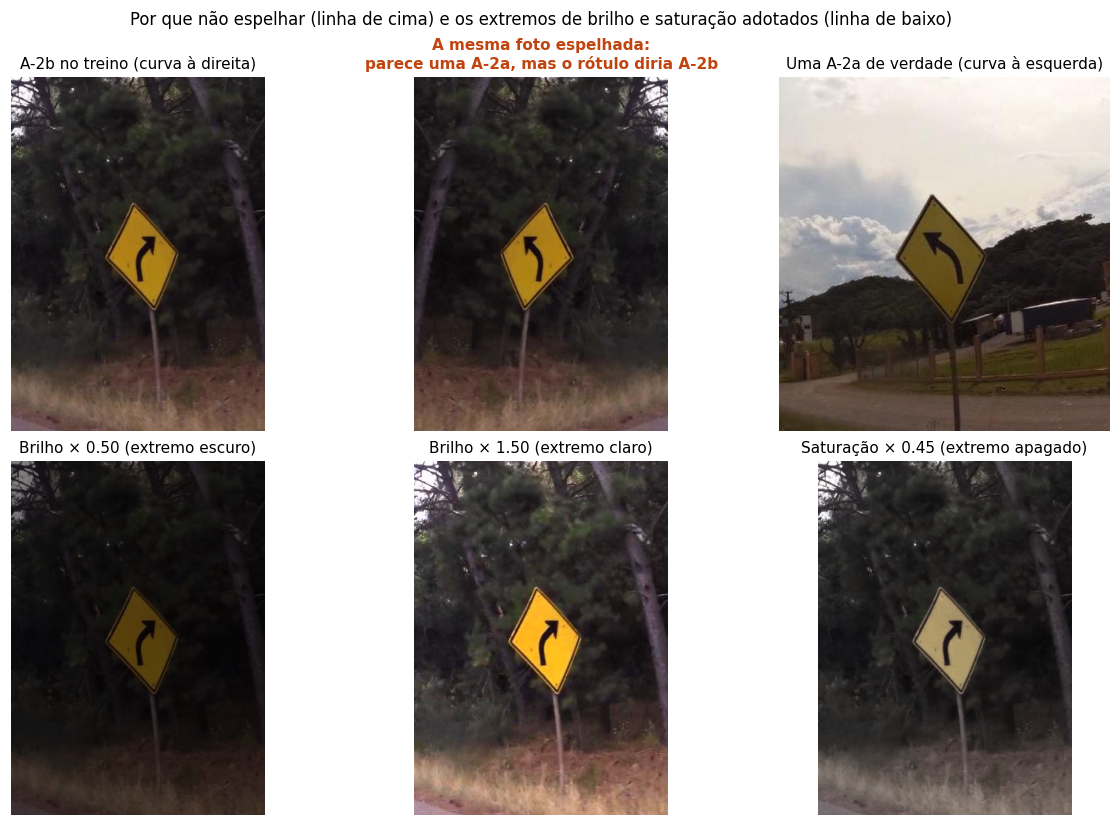

In [28]:
def recorte_da_maior(classe: str, margem: float = 1.0) -> np.ndarray:
    """Recorte RGB em volta da maior placa da classe no treino (escolha deterministica)."""
    k = CLASSES_MODELO.index(classe)
    melhor = None
    for rotulo in (DIR_YOLO / "treino" / "labels").glob("*.txt"):
        for l in rotulo.read_text(encoding="utf-8").splitlines():
            c, cx, cy, w, h = l.split()
            if int(c) == k and (melhor is None or float(w) * float(h) > melhor[0]):
                melhor = (float(w) * float(h), rotulo.stem, float(cx), float(cy), float(w), float(h))
    _, stem, cx, cy, w, h = melhor
    rgb = cv2.cvtColor(cv2.imdecode(np.fromfile(str(DIR_YOLO / "treino" / "images" / f"{stem}.jpg"), np.uint8),
                                    cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    alt, larg = rgb.shape[:2]
    x0, x1 = int((cx - w * (0.5 + margem)) * larg), int((cx + w * (0.5 + margem)) * larg)
    y0, y1 = int((cy - h * (0.5 + margem)) * alt), int((cy + h * (0.5 + margem)) * alt)
    return rgb[max(0, y0):y1, max(0, x0):x1]


def multiplicar_canal(rgb: np.ndarray, canal: int, fator: float) -> np.ndarray:
    """Mesma operacao do RandomHSV do Ultralytics, com o fator fixo no extremo escolhido."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., canal] = np.clip(hsv[..., canal] * fator, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)


direita, esquerda = recorte_da_maior("A-2b"), recorte_da_maior("A-2a")
paineis = [
    (direita, "A-2b no treino (curva à direita)"),
    (cv2.flip(direita, 1), "A mesma foto espelhada:\nparece uma A-2a, mas o rótulo diria A-2b"),
    (esquerda, "Uma A-2a de verdade (curva à esquerda)"),
    (multiplicar_canal(direita, 2, 1 - HSV_V), f"Brilho × {1 - HSV_V:.2f} (extremo escuro)"),
    (multiplicar_canal(direita, 2, 1 + HSV_V), f"Brilho × {1 + HSV_V:.2f} (extremo claro)"),
    (multiplicar_canal(direita, 1, 1 - HSV_S), f"Saturação × {1 - HSV_S:.2f} (extremo apagado)"),
]
fig, eixos = plt.subplots(2, 3, figsize=(11, 7.4), layout="constrained")
for eixo, (img, titulo) in zip(eixos.ravel(), paineis):
    eixo.imshow(img)
    eixo.set_title(titulo)
    eixo.axis("off")
eixos[0, 1].set_title(paineis[1][1], color="#c1440e", fontweight="bold")
fig.suptitle("Por que não espelhar (linha de cima) e os extremos de brilho e saturação adotados (linha de baixo)")
salvar_figura(fig, DIR_FIGURAS / "04_aumento_de_dados.jpg")
plt.show()

Além da tabela, o Ultralytics aplica sozinho, quando o pacote Albumentations está instalado
(o Colab já traz), desfoque, desfoque mediano, escala de cinza e CLAHE, cada um em 1% das
imagens. A probabilidade é baixa e a escala de cinza não chega a tirar a cor do aprendizado,
então esses ficam como estão.

---
## 7. Treino

### 7.1. Arquitetura

- **Família YOLO26**, a mais recente do Ultralytics. Localiza e classifica numa passada só e
  dispensa o NMS (a configuração traz `end2end: True`): a saída do modelo já é a lista final
  de placas, sem um limiar de sobreposição a mais para ajustar na inferência.
- **Transferência de aprendizado.** O treino parte dos pesos aprendidos no COCO e ajusta a
  rede inteira às 27 classes. Com pouco mais de mil imagens anotadas, treinar do zero não
  teria exemplos suficientes.
- **Resolução de 1.280 px**, e não os 640 do padrão. As imagens têm 1.248 px de largura, então
  1.280 mantém a placa no tamanho real. Em 640, o lado de toda placa cairia pela metade: a
  placa mediana ficaria com uns 21 px, e as 5% menores, abaixo de 10 px (Seção 6).
- **Por que essa, e não uma menor?** O tamanho nano (2,6 milhões de parâmetros) é o menor da
  família, e o small (10 milhões) tem quatro vezes mais capacidade. Os dois treinam com a
  mesma configuração, e a regra de escolha, fixada antes do treino, é: **fica o small só se
  superar o nano em pelo menos 0,02 de mAP50 na validação; senão, fica o nano**, que é menor
  e mais rápido. O mAP50 é a métrica da escolha porque usa o mesmo corte de IoU 0,50 da linha
  de base.

### 7.2. Configuração e onde o treino fica salvo

**20 épocas**, com parada antecipada se a validação passar 5 épocas sem melhorar (não chegou
a acontecer). O limite veio do prazo do checkpoint: na T4, cada época leva cerca de 70 s no
nano e 107 s no small, e 100 épocas dos dois tomariam umas cinco horas. Um treino de 100
épocas do nano, começado antes e interrompido na época 22, já estava com mAP50 de 0,708 na
validação; a Seção 8.1 discute o que o limite de 20 épocas custou. O tamanho do lote é
escolhido pelo próprio Ultralytics conforme a memória da GPU, e a semente é fixa.

No Colab, o treino é gravado no Google Drive (`MyDrive/aed_visao_n2/treinos`), porque o treino
pode levar horas numa GPU T4. Se a sessão cair, basta rodar o notebook de novo: o treino
retoma do último *checkpoint*, e um modelo já concluído não é treinado outra vez. Sem GPU, a
seção é pulada. Se faltar tempo para o small, mude `TREINAR_SMALL` para `False` e rode de
novo: o nano concluído é reaproveitado e o notebook fecha só com ele, sem aplicar a regra de
escolha.

In [37]:
import torch
from ultralytics import YOLO

MODO_RAPIDO = os.environ.get("AED_TREINO_RAPIDO") == "1"    # so para testar o codigo na CPU
TREINAR = GPU is not None or MODO_RAPIDO
TREINAR_SMALL = True    # False: fecha so com o nano, se faltar tempo ou GPU para o small
MODELOS = {"yolo26n": "yolo26n.pt"}
if TREINAR_SMALL:
    MODELOS["yolo26s"] = "yolo26s.pt"
MARGEM_MAP50 = 0.02

if EM_COLAB and TREINAR:
    DIR_TREINOS = Path("/content/drive/MyDrive/aed_visao_n2/treinos")
else:
    DIR_TREINOS = Path(os.environ.get("AED_DIR_TREINOS", DIR_DATASET.parent / "treinos"))
DIR_TREINOS.mkdir(parents=True, exist_ok=True)

CONFIG_TREINO = {"imgsz": IMGSZ, "epochs": 20, "patience": 5, "batch": -1, "seed": SEMENTE,
                 "deterministic": True, "workers": 2, "plots": True, **AUMENTO}
if MODO_RAPIDO:
    CONFIG_TREINO.update(imgsz=320, epochs=1, batch=4, fraction=0.05, workers=0, plots=False)

print("Treino:", "modo rapido (teste do codigo, nao e resultado)" if MODO_RAPIDO
      else ("GPU " + GPU) if TREINAR else "pulado, sem GPU")
print("Pasta dos treinos:", DIR_TREINOS.name)

Treino: GPU Tesla T4
Pasta dos treinos: treinos


In [38]:
def treinar(nome: str, peso_inicial: str) -> Path:
    """Treina, retoma um treino interrompido ou reaproveita um concluido."""
    pasta = DIR_TREINOS / nome
    concluido = pasta / "concluido.json"
    if concluido.exists():
        print(f"{nome}: treino concluido antes, reaproveitado")
        return pasta
    ultimo = pasta / "weights" / "last.pt"
    if ultimo.exists() and not MODO_RAPIDO:
        # Treino terminado fica com epoch = -1 no checkpoint. Retomar um desses nao da erro: o
        # Ultralytics comeca outro treino do zero, no conjunto de exemplo (coco8).
        if torch.load(ultimo, map_location="cpu", weights_only=False).get("epoch", -1) < 0:
            print(f"{nome}: o treino ja tinha terminado antes de a sessao cair")
        else:
            print(f"{nome}: retomando do ultimo checkpoint")
            YOLO(str(ultimo)).train(resume=True, data=str(ARQ_DATA_YAML))
    else:
        inicial = DIR_TREINOS / "pesos_iniciais" / peso_inicial
        inicial.parent.mkdir(exist_ok=True)
        YOLO(str(inicial)).train(data=str(ARQ_DATA_YAML), project=str(DIR_TREINOS), name=nome,
                                 exist_ok=True, **CONFIG_TREINO)
    concluido.write_text(json.dumps({"concluido_em": time.strftime("%Y-%m-%d %H:%M:%S"),
                                     "config": CONFIG_TREINO}, indent=2), encoding="utf-8")
    return pasta


def medir_na_validacao(nome: str, pasta: Path) -> dict:
    """Metricas do melhor checkpoint na validacao, no mesmo tamanho de imagem do treino."""
    modelo = YOLO(str(pasta / "weights" / "best.pt"))
    m = modelo.val(data=str(ARQ_DATA_YAML), split="val", imgsz=CONFIG_TREINO["imgsz"], batch=4,
                   plots=False, verbose=False, project=str(DIR_TREINOS / "_validacao"), name=nome, exist_ok=True)
    return {"modelo": nome, "parametros_milhoes": round(sum(p.numel() for p in modelo.model.parameters()) / 1e6, 1),
            "mAP50": round(float(m.box.map50), 3), "mAP50_95": round(float(m.box.map), 3),
            "precisao": round(float(m.box.mp), 3), "recall": round(float(m.box.mr), 3),
            "ms_por_imagem": round(float(m.speed["inference"]), 1)}


if TREINAR:
    PASTAS_TREINO = {nome: treinar(nome, peso) for nome, peso in MODELOS.items()}
    COMPARACAO = pd.DataFrame([medir_na_validacao(n, p) for n, p in PASTAS_TREINO.items()]).set_index("modelo")
    if TREINAR_SMALL:
        ganho_small = COMPARACAO.loc["yolo26s", "mAP50"] - COMPARACAO.loc["yolo26n", "mAP50"]
        MODELO_ESCOLHIDO = "yolo26s" if ganho_small >= MARGEM_MAP50 else "yolo26n"
        print(f"\nO small ganha {ganho_small:+.3f} de mAP50 sobre o nano (margem exigida: {MARGEM_MAP50}). "
              f"Modelo escolhido: {MODELO_ESCOLHIDO}")
    else:
        MODELO_ESCOLHIDO = "yolo26n"
        print("\nSo o nano foi treinado: a regra de escolha entre nano e small nao foi aplicada.")
    display(COMPARACAO)
else:
    print("Sem GPU: o treino foi pulado. As Secoes 8 a 10 usam o treino registrado em "
          "outputs/n2/treino/ e o modelo em modelos/.")

New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aed_visao/data/n2_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.55, hsv_v=0.5, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/conten

,parametros_milhoes,mAP50,mAP50_95,precisao,recall,ms_por_imagem
modelo,,,,,,
yolo26n,2.5,0.623,0.359,0.631,0.627,9.5
yolo26s,10.0,0.770,0.443,0.731,0.735,28.5


In [39]:
DIR_MODELOS = RAIZ / "modelos"
ARQ_MODELO = DIR_MODELOS / "modelo_n2.pt"
ARTEFATOS = ["results.csv", "results.png", "confusion_matrix.png", "confusion_matrix_normalized.png",
             "args.yaml", "labels.jpg", "train_batch0.jpg", "train_batch1.jpg"]

if TREINAR and not MODO_RAPIDO:
    # Curvas, matrizes e configuracao de cada treino vao para o repositorio (sao leves); o peso
    # do modelo escolhido vai para modelos/, que e o que o script de inferencia carrega.
    for nome, pasta in PASTAS_TREINO.items():
        destino = DIR_SAIDA / "treino" / nome
        destino.mkdir(parents=True, exist_ok=True)
        for arquivo in ARTEFATOS:
            if (pasta / arquivo).exists():
                shutil.copy2(pasta / arquivo, destino / arquivo)
    COMPARACAO.to_csv(DIR_SAIDA / "treino" / "comparacao_validacao.csv", encoding="utf-8")
    DIR_MODELOS.mkdir(exist_ok=True)
    shutil.copy2(PASTAS_TREINO[MODELO_ESCOLHIDO] / "weights" / "best.pt", ARQ_MODELO)
    (DIR_SAIDA / "treino" / "escolha_do_modelo.json").write_text(json.dumps({
        "escolhido": MODELO_ESCOLHIDO, "regra": (f"small so se ganhar >= {MARGEM_MAP50} de mAP50 na validacao" if TREINAR_SMALL
                  else "so o nano foi treinado; regra nao aplicada"),
        "classes": CLASSES_MODELO, "config_treino": CONFIG_TREINO,
        "validacao": COMPARACAO.reset_index().to_dict(orient="records"),
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Artefatos em outputs/n2/treino/ e modelo em modelos/{ARQ_MODELO.name} "
          f"({ARQ_MODELO.stat().st_size / 1e6:.1f} MB)")
    if EM_COLAB:
        # Copia no Drive, na mesma estrutura do repositorio: se a sessao do Colab cair, e dali
        # que os arquivos voltam para o Git.
        copia = DIR_TREINOS.parent / "para_o_repositorio"
        shutil.copytree(DIR_SAIDA / "treino", copia / "outputs" / "n2" / "treino", dirs_exist_ok=True)
        (copia / "modelos").mkdir(parents=True, exist_ok=True)
        shutil.copy2(ARQ_MODELO, copia / "modelos" / ARQ_MODELO.name)
        print(f"Copia no Drive: MyDrive/aed_visao_n2/{copia.name}/")
elif MODO_RAPIDO:
    print("Modo rapido: nada e exportado para o repositorio.")
else:
    print("Sem treino nesta execucao: nada a exportar.")

Artefatos em outputs/n2/treino/ e modelo em modelos/modelo_n2.pt (20.4 MB)
Copia no Drive: MyDrive/aed_visao_n2/para_o_repositorio/


---
## 8. Diagnóstico do modelo

O treino da Seção 7 rodou no Colab, numa GPU T4, em 05/11/2026. As curvas, a configuração e o
peso do modelo escolhido foram para o repositório (`outputs/n2/treino/` e
`modelos/modelo_n2.pt`), e esta seção parte deles, por isso roda também sem GPU. Tudo aqui usa
só a validação; o teste fica guardado para a Seção 9.

**O small foi o escolhido.** Na validação, chegou a mAP50 de 0,770, contra 0,623 do nano: um
ganho de 0,147, mais de sete vezes a margem de 0,02 que a regra da Seção 7.1 exigia. O preço é
o tempo, 28,5 ms por imagem numa T4 contra 9,5 ms do nano, o que ainda passa de 30 imagens por
segundo.

In [40]:
DIR_TREINO_REG = DIR_SAIDA / "treino"
ESCOLHA = json.loads((DIR_TREINO_REG / "escolha_do_modelo.json").read_text(encoding="utf-8"))
assert ESCOLHA["classes"] == CLASSES_MODELO, "o modelo registrado foi treinado com outras classes"
MODELO_ESCOLHIDO = ESCOLHA["escolhido"]
COMPARACAO = pd.DataFrame(ESCOLHA["validacao"]).set_index("modelo")
CURVAS = {nome: pd.read_csv(DIR_TREINO_REG / nome / "results.csv") for nome in COMPARACAO.index}
EPOCAS = ESCOLHA["config_treino"]["epochs"]
ULTIMA_COM_MOSAICO = EPOCAS - ESCOLHA["config_treino"]["close_mosaic"]
NOME_TAMANHO = {"yolo26n": "nano", "yolo26s": "small"}

import io
from IPython.display import Image as ImagemJPEG


def mostrar_foto(fig):
    """Mostra um painel de fotos em JPEG: em PNG, cada painel pesaria megabytes no notebook."""
    memoria = io.BytesIO()
    fig.savefig(memoria, format="jpg", dpi=plt.rcParams["figure.dpi"], bbox_inches="tight",
                pil_kwargs={"quality": 85})
    plt.close(fig)
    display(ImagemJPEG(data=memoria.getvalue(), format="jpeg"))

print(f"Treino registrado: {', '.join(NOME_TAMANHO[n] for n in COMPARACAO.index)}, {EPOCAS} epocas, "
      f"mosaico ate a epoca {ULTIMA_COM_MOSAICO} | escolhido: {MODELO_ESCOLHIDO} | peso: modelos/{ARQ_MODELO.name}")
print("iou na N1:", "iou" in N1)

Treino registrado: nano, small, 20 epocas, mosaico ate a epoca 10 | escolhido: yolo26s | peso: modelos/modelo_n2.pt
iou na N1: True


### 8.1. Curvas de treino e validação

As perdas são as do Ultralytics para o YOLO26: `box` mede o erro da caixa e `cls`, o da
classe. A faixa cinza marca as 10 últimas épocas, em que o mosaico fica desligado (Seção 6). A
tabela abaixo da figura mede o vão entre validação e treino em três momentos.

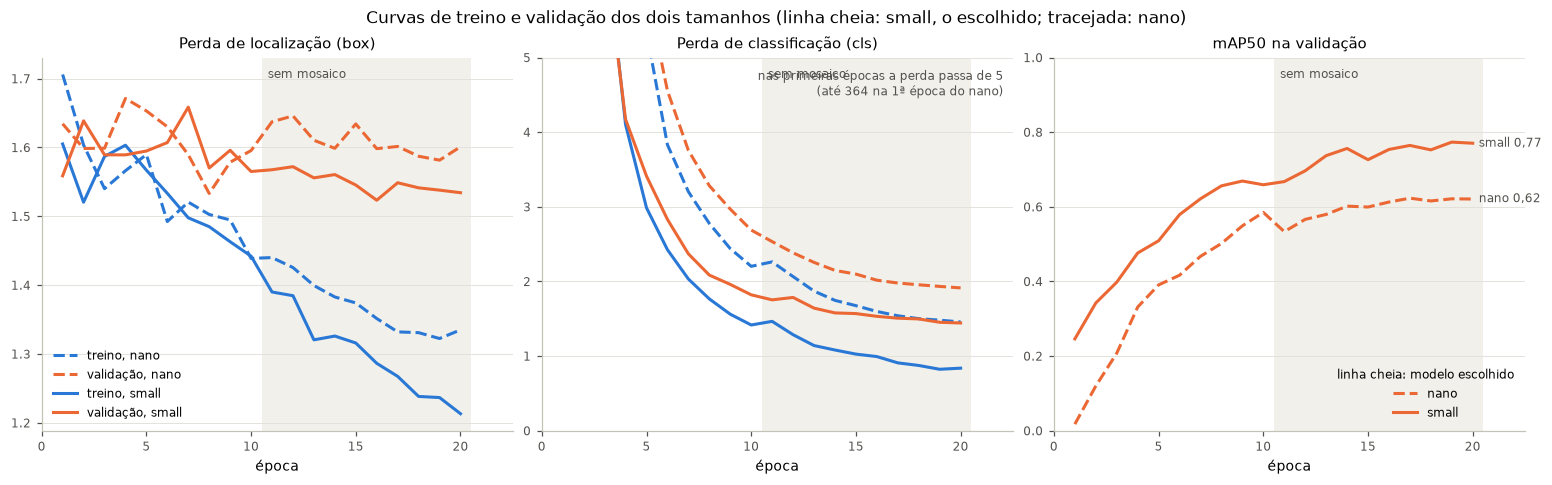

box treino  box validação  vão box  cls treino  cls validação  \
modelo época                                                                  
nano   5           1.590          1.653    0.063       5.343          5.914   
       10          1.439          1.596    0.157       2.202          2.688   
       20          1.335          1.601    0.266       1.456          1.913   
small  5           1.567          1.595    0.028       2.986          3.411   
       10          1.442          1.565    0.123       1.416          1.820   
       20          1.213          1.534    0.321       0.837          1.443   

              vão cls  mAP50 validação  
modelo época                            
nano   5        0.571            0.391  
       10       0.486            0.585  
       20       0.457            0.621  
small  5        0.425            0.509  
       10       0.404            0.659  
       20       0.605            0.770

In [41]:
TINTA, TINTA_2, TINTA_MUDA = "#0b0b0b", "#52514e", "#898781"
fig, eixos = plt.subplots(1, 3, figsize=(14, 4.3), layout="constrained")
for nome, curva in CURVAS.items():
    estilo = "-" if nome == MODELO_ESCOLHIDO else "--"
    tamanho = NOME_TAMANHO[nome]
    for eixo, perda in zip(eixos[:2], ("box_loss", "cls_loss")):
        eixo.plot(curva["epoch"], curva[f"train/{perda}"], estilo, color=COR_CONJUNTO["treino"], lw=2,
                  label=f"treino, {tamanho}")
        eixo.plot(curva["epoch"], curva[f"val/{perda}"], estilo, color=COR_CONJUNTO["validacao"], lw=2,
                  label=f"validação, {tamanho}")
    eixos[2].plot(curva["epoch"], curva["metrics/mAP50(B)"], estilo, color=COR_CONJUNTO["validacao"], lw=2,
                  label=tamanho)
    final = curva.iloc[-1]
    eixos[2].annotate(f"{tamanho} {final['metrics/mAP50(B)']:.2f}".replace(".", ","),
                      (final["epoch"], final["metrics/mAP50(B)"]), xytext=(4, 0), textcoords="offset points",
                      va="center", fontsize=8, color=TINTA_2)

eixos[1].set_ylim(0, 5)
eixos[1].text(0.98, 0.97, "nas primeiras épocas a perda passa de 5\n(até 364 na 1ª época do nano)",
              transform=eixos[1].transAxes, ha="right", va="top", fontsize=8, color=TINTA_2)
titulos = ("Perda de localização (box)", "Perda de classificação (cls)", "mAP50 na validação")
for eixo, titulo in zip(eixos, titulos):
    eixo.axvspan(ULTIMA_COM_MOSAICO + 0.5, EPOCAS + 0.5, color="#f1f0ea", zorder=0, lw=0)
    eixo.text(ULTIMA_COM_MOSAICO + 0.8, 0.97, "sem mosaico", transform=eixo.get_xaxis_transform(),
              va="top", fontsize=8, color=TINTA_2)
    eixo.set_title(titulo)
    eixo.set_xlabel("época")
    eixo.set_xlim(0.5, EPOCAS + 2.5)
    eixo.set_xticks(range(0, EPOCAS + 1, 5))
    eixo.grid(axis="y", color="#e1e0d9", lw=0.6)
    eixo.set_axisbelow(True)
eixos[0].legend(frameon=False, fontsize=8, loc="lower left")
eixos[2].set_ylim(0, 1)
eixos[2].legend(frameon=False, fontsize=8, loc="lower right", title="linha cheia: modelo escolhido",
                title_fontsize=8)
fig.suptitle("Curvas de treino e validação dos dois tamanhos (linha cheia: small, o escolhido; tracejada: nano)")
salvar_figura(fig, DIR_FIGURAS / "05_curvas_de_treino.png")
plt.show()


def vao(curva: pd.DataFrame, epoca: int) -> dict:
    """Perdas de treino e validacao numa epoca e a diferenca entre elas."""
    l = curva.set_index("epoch").loc[epoca]
    return {"box treino": l["train/box_loss"], "box validação": l["val/box_loss"],
            "vão box": l["val/box_loss"] - l["train/box_loss"],
            "cls treino": l["train/cls_loss"], "cls validação": l["val/cls_loss"],
            "vão cls": l["val/cls_loss"] - l["train/cls_loss"], "mAP50 validação": l["metrics/mAP50(B)"]}


VAO = pd.DataFrame([{"modelo": NOME_TAMANHO[n], "época": e, **vao(c, e)}
                    for n, c in CURVAS.items() for e in (5, ULTIMA_COM_MOSAICO, EPOCAS)]).set_index(["modelo", "época"])
VAO.round(3).to_csv(DIR_SAIDA / "treino" / "vao_treino_validacao.csv", encoding="utf-8")
VAO.round(3)

**O que as curvas mostram:**

- **Não há sobreajuste no sentido clássico.** Em 20 épocas, nenhuma perda de validação volta a
  subir, e o mAP50 da validação cresce até o fim: no small, de 0,659 na época 10 para 0,770 na 20.
- **Mas o vão entre treino e validação cresce.** No small, da época 10 para a 20, ele vai de 0,12
  para 0,32 na perda de caixa e de 0,40 para 0,61 na de classe. O treino melhora mais depressa do
  que a validação, que é o começo da memorização. Na caixa isso é nítido: a perda de treino cai
  de 1,61 para 1,21, e a de validação quase não sai do lugar (de 1,56 para 1,53). O ganho de mAP
  na validação vem de encontrar e classificar mais placas, e não de caixas mais justas.
- **Parte do salto depois da época 10 é efeito do mosaico.** A perda de treino é medida nas
  imagens aumentadas. Quando o mosaico desliga, o treino passa a ver quadros inteiros, mais
  fáceis, e a perda dele cai mais depressa. O vão alarga sem que a validação piore.
- **O nano parou por falta de épocas, e não de capacidade.** O mAP50 dele fica em torno de 0,62
  desde a época 17, mas é o cronograma de 20 épocas que leva a taxa de aprendizado quase a zero
  nessa altura. O treino de 100 épocas interrompido (Seção 7.2) estava em 0,708 na época 21, com
  a taxa ainda alta e o mosaico ligado. A vantagem de 0,147 do small foi medida com o mesmo
  orçamento curto para os dois, e esse orçamento favorece o modelo que aprende mais depressa. A
  regra foi aplicada como estava fixada; repetir a comparação com 100 épocas é a primeira tarefa
  da Ex2.

Um detalhe de execução: o nano treinou com lote de 16 imagens e o small, com lote de 4. O
AutoBatch do nano mediu a GPU ainda ocupada pelo treino interrompido e caiu no padrão de 16. Isso
não muda o número de atualizações dos pesos: o Ultralytics acumula o gradiente até 64 imagens
antes de cada passo, nos dois casos.

### 8.2. Limiar de confiança, escolhido na validação

O modelo devolve cada placa com uma confiança de 0 a 1, e o sistema precisa de um corte para
decidir o que mostrar. O corte sai daqui, da validação, e vai para o teste sem mudança. O critério
é o F1 com o acerto mais exigente: placa no lugar certo (IoU ≥ 0,50) **e** com a classe certa,
contado com o mesmo casamento da linha de base, feito classe a classe.

As predições vêm do [`inferir.py`](../inferir.py), o mesmo pipeline da Seção 10, e ficam
gravadas em `outputs/n2/predicoes_validacao.csv`. O limiar escolhido vai para
`modelos/modelo_n2.json`, de onde o `inferir.py` o lê.

In [42]:
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
import inferir

MODELO, CONFIG_INFERENCIA = inferir.carregar_modelo(ARQ_MODELO, ARQ_MODELO.with_suffix(".json"))
CONF_MINIMA = 0.05     # abaixo disso nenhum limiar util; guardar tudo so incharia a tabela


def predizer_conjunto(nome: str) -> pd.DataFrame:
    """Placas do modelo em todas as imagens de um conjunto, pelo pipeline do inferir.py."""
    linhas = []
    for img in sorted((DIR_YOLO / nome / "images").iterdir()):
        imagem, placas = inferir.inferir(MODELO, CONFIG_INFERENCIA, img, limiar=CONF_MINIMA)
        alt, larg = imagem.shape[:2]
        linhas += [{"arquivo": img.name, "classe": p.classe, "confianca": p.confianca,
                    "x": p.caixa[0] / larg, "y": p.caixa[1] / alt,
                    "w": (p.caixa[2] - p.caixa[0]) / larg, "h": (p.caixa[3] - p.caixa[1]) / alt}
                   for p in placas]
    return pd.DataFrame(linhas, columns=["arquivo", "classe", "confianca", "x", "y", "w", "h"])


def gabarito_com_classe(nome: str) -> dict:
    """Anotacoes de cada imagem do conjunto: (classe, x, y, w, h) normalizados."""
    gabarito = {}
    for img in sorted((DIR_YOLO / nome / "images").iterdir()):
        linhas = (DIR_YOLO / nome / "labels" / f"{img.stem}.txt").read_text(encoding="utf-8").split()
        campos = [linhas[k:k + 5] for k in range(0, len(linhas), 5)]
        gabarito[img.name] = [(CLASSES_MODELO[int(c)], float(cx) - float(w) / 2, float(cy) - float(h) / 2,
                               float(w), float(h)) for c, cx, cy, w, h in campos]
    return gabarito


def acima_do_limiar(predicoes: pd.DataFrame, limiar: float) -> dict:
    """Deteccoes com confianca >= limiar, por imagem: (classe, x, y, w, h)."""
    sel = predicoes[predicoes["confianca"] >= limiar]
    return {a: list(g[["classe", "x", "y", "w", "h"]].itertuples(index=False, name=None))
            for a, g in sel.groupby("arquivo")}


def avaliar_com_classe(deteccoes: dict, gabarito: dict, limiar_iou: float) -> dict:
    """Como avaliar_deteccao, mas so vale acerto com a classe certa: o casamento da N1, classe a classe."""
    vp = fp = fn = 0
    for arquivo, anotadas in gabarito.items():
        detectadas = deteccoes.get(arquivo, [])
        for classe in {d[0] for d in detectadas} | {a[0] for a in anotadas}:
            a, b, c = N1["casar_deteccoes"]([d[1:] for d in detectadas if d[0] == classe],
                                            [x[1:] for x in anotadas if x[0] == classe], limiar_iou)
            vp, fp, fn = vp + a, fp + b, fn + c
    precisao = vp / (vp + fp) if vp + fp else 0.0
    recall = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall else 0.0
    return {"precisao": round(precisao, 3), "recall": round(recall, 3), "f1": round(f1, 3),
            "vp": vp, "fp": fp, "fn": fn}


def sem_classe(deteccoes: dict) -> dict:
    """So as caixas, no formato que a avaliar_deteccao da linha de base recebe."""
    return {a: [d[1:] for d in caixas] for a, caixas in deteccoes.items()}


inicio = time.time()
PRED_VALIDACAO = predizer_conjunto("validacao")
GAB_VALIDACAO = gabarito_com_classe("validacao")
PRED_VALIDACAO.to_csv(DIR_SAIDA / "predicoes_validacao.csv", index=False, encoding="utf-8")
segundos = time.time() - inicio
print(f"Validacao: {len(GAB_VALIDACAO)} imagens em {segundos:.0f} s ({1000 * segundos / len(GAB_VALIDACAO):.0f} ms "
      f"por imagem, {'GPU' if GPU else 'CPU'}) | {len(PRED_VALIDACAO)} deteccoes com confianca >= {CONF_MINIMA} | "
      f"{sum(map(len, GAB_VALIDACAO.values()))} placas anotadas")

Validacao: 399 imagens em 249 s (625 ms por imagem, CPU) | 503 deteccoes com confianca >= 0.05 | 254 placas anotadas


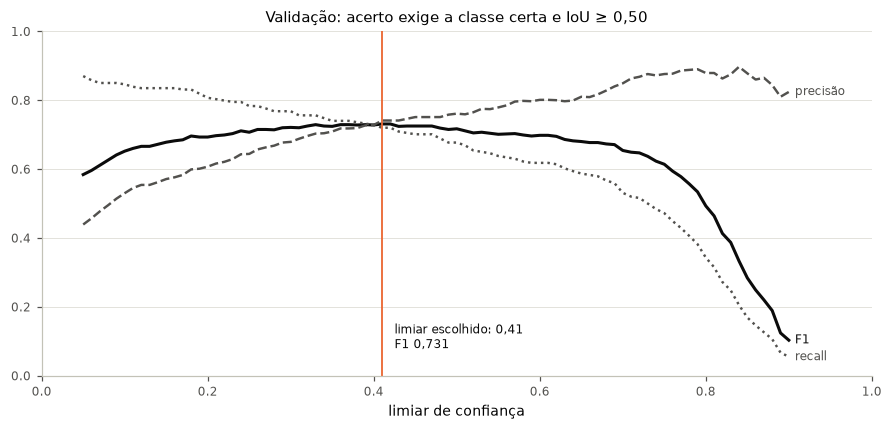

Limiar escolhido na validacao: 0.41 (gravado em modelos/modelo_n2.json)


,precisao,recall,f1,vp,fp,fn
limiar,,,,,,
0.10,0.530,0.846,0.652,215,191,39
0.25,0.644,0.783,0.707,199,110,55
0.41,0.741,0.720,0.731,183,64,71
0.50,0.761,0.677,0.717,172,54,82
0.75,0.876,0.472,0.614,120,17,134


In [43]:
LIMIARES = np.round(np.arange(CONF_MINIMA, 0.91, 0.01), 2)
VARREDURA = pd.DataFrame([{"limiar": l, **avaliar_com_classe(acima_do_limiar(PRED_VALIDACAO, l), GAB_VALIDACAO, 0.50)}
                          for l in LIMIARES]).set_index("limiar")
LIMIAR = float(VARREDURA["f1"].idxmax())        # empate: fica o menor limiar com o F1 maximo
VARREDURA.to_csv(DIR_SAIDA / "limiar_validacao.csv", encoding="utf-8")

CONFIG_INFERENCIA = {
    "modelo": MODELO_ESCOLHIDO, "imgsz": IMGSZ, "limiar_confianca": LIMIAR,
    "criterio_do_limiar": "maior F1 na validacao, contando acerto so com a classe certa e IoU >= 0,50",
    "f1_validacao": float(VARREDURA.loc[LIMIAR, "f1"]), "classes": CLASSES_MODELO,
}
ARQ_MODELO.with_suffix(".json").write_text(json.dumps(CONFIG_INFERENCIA, ensure_ascii=False, indent=2),
                                           encoding="utf-8")

fig, eixo = plt.subplots(figsize=(8, 3.8), layout="constrained")
for coluna, estilo, cor, rotulo in (("f1", "-", TINTA, "F1"), ("precisao", "--", TINTA_2, "precisão"),
                                    ("recall", ":", TINTA_2, "recall")):
    eixo.plot(VARREDURA.index, VARREDURA[coluna], estilo, color=cor, lw=2 if coluna == "f1" else 1.6)
    eixo.annotate(rotulo, (VARREDURA.index[-1], VARREDURA[coluna].iloc[-1]), xytext=(4, 0),
                  textcoords="offset points", va="center", fontsize=8, color=cor)
eixo.axvline(LIMIAR, color=COR_CONJUNTO["validacao"], lw=1.2)
eixo.text(LIMIAR + 0.015, 0.08, f"limiar escolhido: {LIMIAR:.2f}\nF1 {VARREDURA.loc[LIMIAR, 'f1']:.3f}".replace(".", ","),
          fontsize=8, color=TINTA)
eixo.set_xlim(0, 1)
eixo.set_ylim(0, 1)
eixo.set_xlabel("limiar de confiança")
eixo.grid(axis="y", color="#e1e0d9", lw=0.6)
eixo.set_axisbelow(True)
eixo.set_title("Validação: acerto exige a classe certa e IoU ≥ 0,50")
salvar_figura(fig, DIR_FIGURAS / "06_limiar_de_confianca.png")
plt.show()

print(f"Limiar escolhido na validacao: {LIMIAR:.2f} (gravado em modelos/{ARQ_MODELO.with_suffix('.json').name})")
VARREDURA.loc[sorted({0.10, 0.25, LIMIAR, 0.50, 0.75})]

**Limiar de 0,41, com F1 de 0,731 na validação.** A curva do F1 é quase plana: fica entre
0,69 e 0,73 para qualquer corte de 0,20 a 0,60, então a escolha não depende de ajuste fino. Abaixo
do limiar, o modelo ganha recall à custa de alarmes falsos; acima, perde placas para ganhar
precisão.

### 8.3. Matriz de confusão

A matriz é montada a partir das predições, no limiar de 0,41, com o casamento da linha de base.
Primeiro, cada placa anotada é casada com uma detecção da mesma classe; entre as que sobram, com
uma de outra classe, o que revela as trocas. A linha e a coluna `fundo` guardam os dois erros que
não são troca: a placa que o modelo não viu e a detecção onde não há placa anotada.

A matriz que o Ultralytics gravou no treino (`outputs/n2/treino/yolo26s/confusion_matrix.png`)
não é usada: ela contradiz a tabela por classe do próprio treino. A única `A-22` da validação,
por exemplo, tem AP50 de 0,995 nessa tabela e aparece naquela matriz 100% como `R-7`.

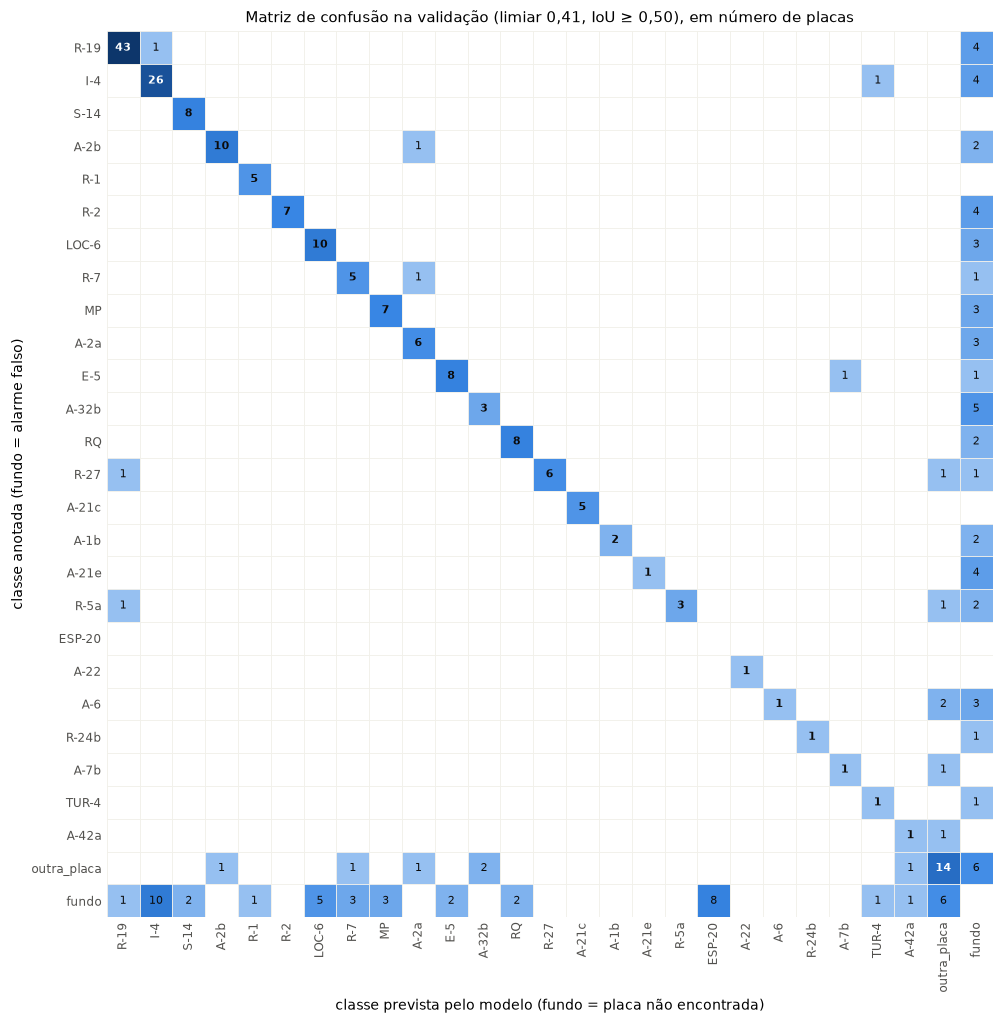

254 placas anotadas: 183 com a classe certa, 52 nao encontradas, 19 encontradas com a classe errada | 45 alarmes falsos

Trocas entre classes de placa (sem fundo):
    anotada    prevista  placas
outra_placa       A-32b       2
        A-6 outra_placa       2
       R-5a        R-19       1
       R-19         I-4       1
       R-5a outra_placa       1
        I-4       TUR-4       1
       R-27 outra_placa       1
outra_placa       A-42a       1
       R-27        R-19       1
       A-7b outra_placa       1
outra_placa        A-2a       1
      A-42a outra_placa       1
        E-5        A-7b       1
        R-7        A-2a       1
outra_placa        A-2b       1
outra_placa         R-7       1
       A-2b        A-2a       1

Alarmes falsos por classe prevista:
prevista
I-4            10
ESP-20          8
outra_placa     6
LOC-6           5
MP              3
R-7             3
E-5             2
RQ              2
S-14            2
R-1             1
TUR-4           1
A-42a           

In [44]:
FUNDO = "fundo"


def parear(detectadas: list, anotadas: list, limiar_iou: float) -> list[tuple[int, int]]:
    """Os pares (deteccao, anotacao) do casamento da N1: guloso, do maior IoU para o menor."""
    pares = sorted(((N1["iou"](d[1:], a[1:]), i, j) for i, d in enumerate(detectadas)
                    for j, a in enumerate(anotadas)), reverse=True)
    usados_d, usados_a, casados = set(), set(), []
    for valor, i, j in pares:
        if valor < limiar_iou:
            break
        if i not in usados_d and j not in usados_a:
            usados_d.add(i)
            usados_a.add(j)
            casados.append((i, j))
    return casados


def tabela_de_erros(deteccoes: dict, gabarito: dict, limiar_iou: float = 0.50) -> pd.DataFrame:
    """Uma linha por placa anotada e por deteccao sobrando: classe anotada x classe prevista.

    Primeiro casa cada classe com ela mesma (o mesmo casamento da avaliacao com classe); depois,
    entre as sobras, casa sem olhar a classe, o que revela as trocas. Placa sem deteccao vira
    prevista = fundo (o modelo nao viu); deteccao sem placa vira anotada = fundo (alarme falso).
    """
    linhas = []
    for arquivo, anotadas in gabarito.items():
        detectadas = deteccoes.get(arquivo, [])
        casados = []
        for classe in {d[0] for d in detectadas} & {a[0] for a in anotadas}:
            idx_d = [i for i, d in enumerate(detectadas) if d[0] == classe]
            idx_a = [j for j, a in enumerate(anotadas) if a[0] == classe]
            casados += [(idx_d[i], idx_a[j]) for i, j in parear([detectadas[i] for i in idx_d],
                                                                [anotadas[j] for j in idx_a], limiar_iou)]
        sobra_d = [i for i in range(len(detectadas)) if i not in {i for i, _ in casados}]
        sobra_a = [j for j in range(len(anotadas)) if j not in {j for _, j in casados}]
        casados += [(sobra_d[i], sobra_a[j]) for i, j in parear([detectadas[i] for i in sobra_d],
                                                                [anotadas[j] for j in sobra_a], limiar_iou)]
        livres_d = set(range(len(detectadas))) - {i for i, _ in casados}
        livres_a = set(range(len(anotadas))) - {j for _, j in casados}
        linhas += [{"arquivo": arquivo, "anotada": anotadas[j][0], "prevista": detectadas[i][0],
                    "caixa": anotadas[j][1:]} for i, j in casados]
        linhas += [{"arquivo": arquivo, "anotada": anotadas[j][0], "prevista": FUNDO, "caixa": anotadas[j][1:]}
                   for j in livres_a]
        linhas += [{"arquivo": arquivo, "anotada": FUNDO, "prevista": detectadas[i][0], "caixa": detectadas[i][1:]}
                   for i in livres_d]
    return pd.DataFrame(linhas)


DET_VALIDACAO = acima_do_limiar(PRED_VALIDACAO, LIMIAR)
ERROS_VAL = tabela_de_erros(DET_VALIDACAO, GAB_VALIDACAO)
ORDEM = CLASSES_MODELO + [FUNDO]
MATRIZ_VAL = pd.crosstab(ERROS_VAL["anotada"], ERROS_VAL["prevista"]).reindex(index=ORDEM, columns=ORDEM, fill_value=0)
MATRIZ_VAL.to_csv(DIR_SAIDA / "matriz_confusao_validacao.csv", encoding="utf-8")

# Conferencia: a matriz tem de reproduzir os acertos da avaliacao com classe no mesmo limiar.
diagonal = int(np.trace(MATRIZ_VAL.loc[CLASSES_MODELO, CLASSES_MODELO].to_numpy()))
assert diagonal == VARREDURA.loc[LIMIAR, "vp"], (diagonal, VARREDURA.loc[LIMIAR, "vp"])

# So as classes que aparecem na validacao (anotadas ou previstas), para a figura caber.
presentes = [c for c in ORDEM if MATRIZ_VAL.loc[c].sum() + MATRIZ_VAL[c].sum() > 0]
m = MATRIZ_VAL.loc[presentes, presentes]
from matplotlib.colors import LinearSegmentedColormap
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, eixo = plt.subplots(figsize=(10.5, 9.2), layout="constrained")
valores = np.ma.masked_equal(m.to_numpy(), 0)
imagem = eixo.imshow(np.sqrt(valores), cmap=AZUL, vmin=0, aspect="equal")
for (i, j), v in np.ndenumerate(m.to_numpy()):
    if v:
        escuro = np.sqrt(v) > 0.55 * np.sqrt(m.to_numpy().max())
        eixo.text(j, i, str(v), ha="center", va="center", fontsize=7.5, color="white" if escuro else TINTA,
                  fontweight="bold" if i == j else "normal")
eixo.set_xticks(range(len(presentes)), presentes, rotation=90, fontsize=8)
eixo.set_yticks(range(len(presentes)), presentes, fontsize=8)
eixo.set_xlabel("classe prevista pelo modelo (fundo = placa não encontrada)")
eixo.set_ylabel("classe anotada (fundo = alarme falso)")
for k in range(len(presentes) + 1):
    eixo.axhline(k - 0.5, color="#f1f0ea", lw=0.6)
    eixo.axvline(k - 0.5, color="#f1f0ea", lw=0.6)
eixo.spines[:].set_visible(False)
eixo.tick_params(length=0)
eixo.set_title(f"Matriz de confusão na validação (limiar {LIMIAR:.2f}, IoU ≥ 0,50), em número de placas".replace(".", ",", 1))
salvar_figura(fig, DIR_FIGURAS / "07_matriz_de_confusao_validacao.png")
plt.show()

trocas = (ERROS_VAL[(ERROS_VAL["anotada"] != ERROS_VAL["prevista"])]
          .value_counts(["anotada", "prevista"]).rename("placas").reset_index())
n_anot = ERROS_VAL[ERROS_VAL["anotada"] != FUNDO].shape[0]
print(f"{n_anot} placas anotadas: {diagonal} com a classe certa, "
      f"{int((ERROS_VAL['prevista'] == FUNDO).sum())} nao encontradas, "
      f"{int(((ERROS_VAL['anotada'] != FUNDO) & (ERROS_VAL['prevista'] != FUNDO) & (ERROS_VAL['anotada'] != ERROS_VAL['prevista'])).sum())} "
      f"encontradas com a classe errada | {int((ERROS_VAL['anotada'] == FUNDO).sum())} alarmes falsos\n")
print("Trocas entre classes de placa (sem fundo):")
print(trocas[(trocas["anotada"] != FUNDO) & (trocas["prevista"] != FUNDO)].to_string(index=False))
print("\nAlarmes falsos por classe prevista:")
print(trocas[trocas["anotada"] == FUNDO].set_index("prevista")["placas"].to_string())

**O modelo quase não troca uma placa por outra. Ele erra por não ver e por ver onde não há
anotação.** Das 254 placas da validação, 183 saem com a classe certa, 52 não são encontradas e
só 19 são encontradas com a classe errada. Há ainda 45 detecções sem placa anotada no lugar.

As 19 trocas seguem um padrão:

- **12 envolvem `outra_placa`.** Essa classe junta 41 tipos raros de placa, e por isso se parece
  com várias das outras. Na figura de erros mais abaixo, uma placa de proibido virar à esquerda
  (`outra_placa`, com o texto "proibido converter à esquerda") sai como `R-7` (proibido
  ultrapassar): o mesmo círculo vermelho cortado, com outro desenho no miolo.
- **As outras são, na maioria, entre placas de mesma forma e cor, que só diferem no
  pictograma:** uma `R-5a` e uma `R-27` lidas como `R-19`, todas círculos de borda vermelha, e
  uma `A-2b` (curva à direita) lida como `A-2a` (curva à esquerda). É o erro esperado. Forma e
  cor, a informação que o pipeline da N1 usava, são justamente o que essas placas têm em comum;
  o que as separa é um desenho de poucos pixels no miolo.

In [45]:
LARGURA_IMG = {}


def lado_px(arquivo: str, caixa: tuple, conjunto: str = "validacao") -> float:
    """Lado equivalente da caixa, em pixels da imagem original."""
    if arquivo not in LARGURA_IMG:
        img = cv2.imdecode(np.fromfile(str(DIR_YOLO / conjunto / "images" / arquivo), np.uint8), cv2.IMREAD_REDUCED_COLOR_8)
        LARGURA_IMG[arquivo] = (img.shape[1] * 8, img.shape[0] * 8)
    larg, alt = LARGURA_IMG[arquivo]
    return math.sqrt(caixa[2] * larg * caixa[3] * alt)


anotadas = ERROS_VAL[ERROS_VAL["anotada"] != FUNDO].copy()
anotadas["lado_px"] = [lado_px(a, c) for a, c in zip(anotadas["arquivo"], anotadas["caixa"])]
anotadas["desfecho"] = np.select([anotadas["prevista"] == anotadas["anotada"], anotadas["prevista"] == FUNDO],
                                 ["classe certa", "não encontrada"], "classe errada")
print("Lado da placa (px na imagem original) por desfecho:")
print(anotadas.groupby("desfecho")["lado_px"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]].round(1).to_string())
for corte in (20, 25, 30):
    peq = anotadas["lado_px"] < corte
    print(f"placas com lado < {corte} px: {peq.sum()} | encontradas com a classe certa: "
          f"{(anotadas.loc[peq, 'desfecho'] == 'classe certa').mean():.0%} | maiores: "
          f"{(anotadas.loc[~peq, 'desfecho'] == 'classe certa').mean():.0%}")

POR_CLASSE_VAL = pd.DataFrame({
    "anotadas": anotadas.groupby("anotada").size(),
    "classe_certa": anotadas[anotadas["desfecho"] == "classe certa"].groupby("anotada").size(),
    "nao_encontradas": anotadas[anotadas["desfecho"] == "não encontrada"].groupby("anotada").size(),
    "classe_errada": anotadas[anotadas["desfecho"] == "classe errada"].groupby("anotada").size(),
    "alarmes_falsos": ERROS_VAL[ERROS_VAL["anotada"] == FUNDO].groupby("prevista").size(),
}).reindex(CLASSES_MODELO).fillna(0).astype(int)
POR_CLASSE_VAL["recall"] = (POR_CLASSE_VAL["classe_certa"] / POR_CLASSE_VAL["anotadas"]).round(2)
POR_CLASSE_VAL.to_csv(DIR_SAIDA / "validacao_por_classe.csv", encoding="utf-8")
POR_CLASSE_VAL

Lado da placa (px na imagem original) por desfecho:
                count   25%   50%   75%
desfecho                               
classe certa    183.0  27.3  41.1  63.0
classe errada    19.0  27.1  43.9  61.0
não encontrada   52.0  20.9  27.2  38.6
placas com lado < 20 px: 33 | encontradas com a classe certa: 58% | maiores: 74%
placas com lado < 25 px: 63 | encontradas com a classe certa: 60% | maiores: 76%
placas com lado < 30 px: 90 | encontradas com a classe certa: 61% | maiores: 78%


,anotadas,classe_certa,nao_encontradas,classe_errada,alarmes_falsos,recall
R-19,48,43,4,1,1,0.90
I-4,31,26,4,1,10,0.84
S-14,8,8,0,0,2,1.00
A-2b,13,10,2,1,0,0.77
R-1,5,5,0,0,1,1.00
R-2,11,7,4,0,0,0.64
LOC-6,13,10,3,0,5,0.77
R-7,7,5,1,1,3,0.71
MP,10,7,3,0,3,0.70
A-2a,9,6,3,0,0,0.67


**As placas não encontradas são, sobretudo, as pequenas.** A placa perdida tem lado mediano de
27 px na imagem original, contra 41 px das encontradas com a classe certa. Entre as placas com
menos de 25 px de lado, o modelo acerta 60%; entre as maiores, 76%. Por classe, os piores recalls
são de `A-6` (1 de 6), `A-21e` (1 de 5) e `A-32b` (3 de 8), três placas de advertência de
pictograma fino. Com cinco a oito exemplos na validação, porém, uma placa a mais ou a menos muda o
recall em 15 a 20 pontos: a tabela por classe aponta suspeitos, mas não ordena as classes.

A primeira figura abaixo sorteia seis exemplos de cada tipo de erro. A segunda mostra todos os
alarmes falsos.

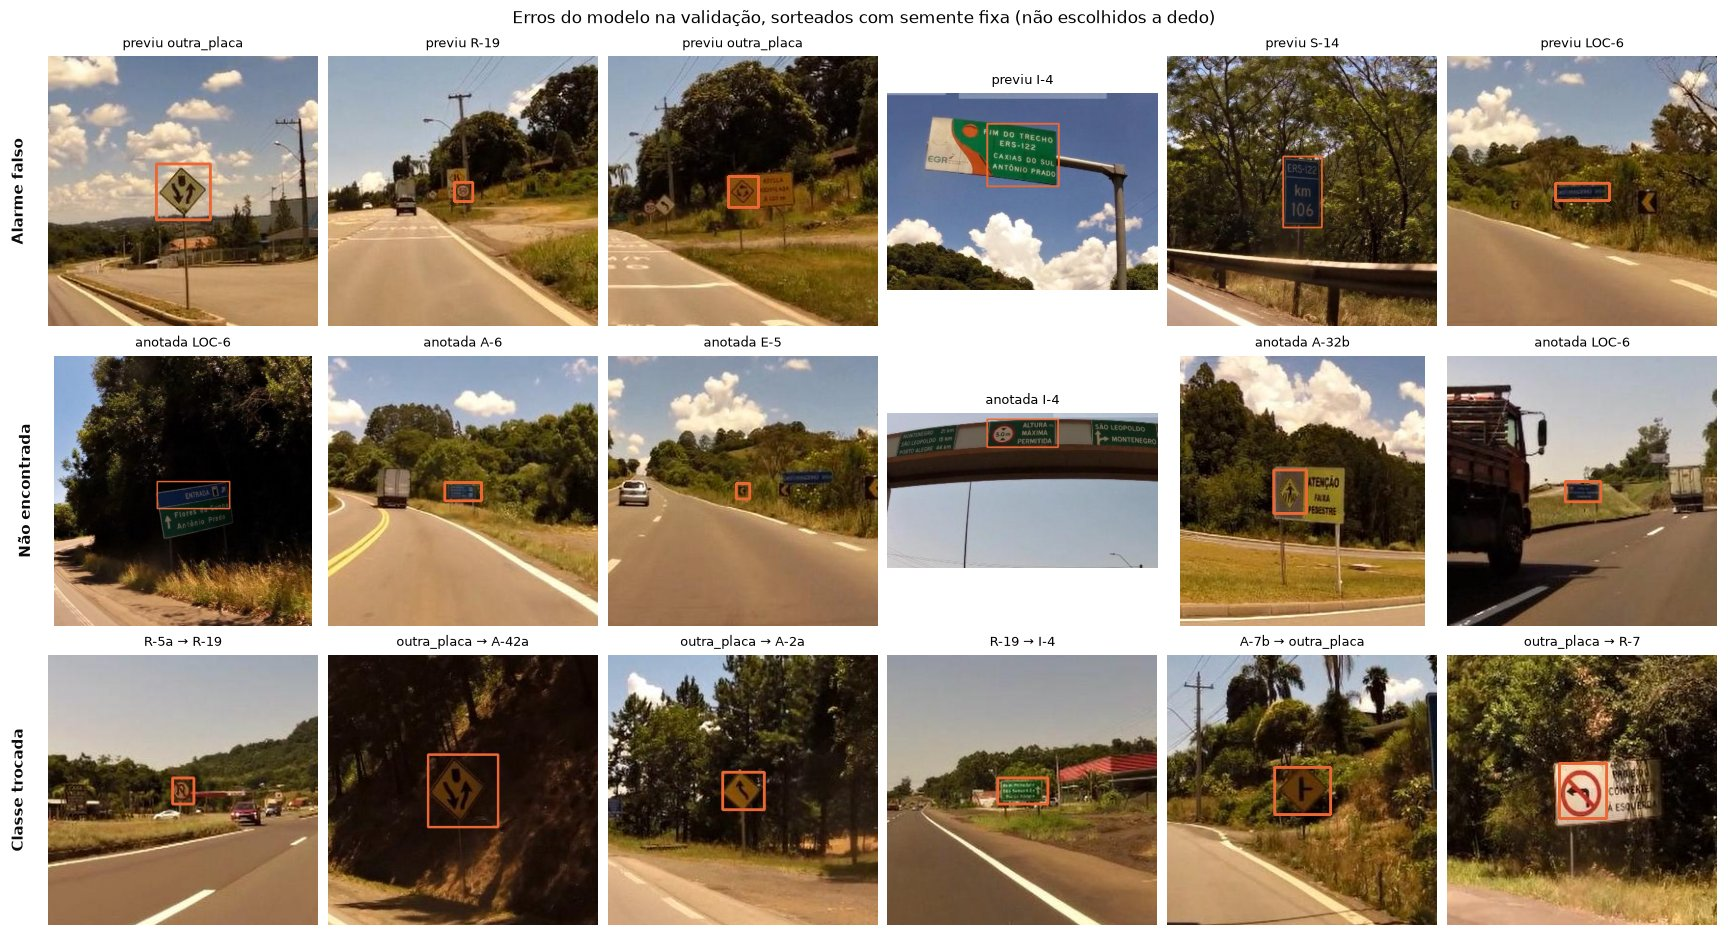

In [46]:
def recorte(arquivo: str, caixa: tuple, conjunto: str, cor_hex: str, margem: float = 2.0, minimo: int = 140) -> np.ndarray:
    """Recorte RGB em volta de uma caixa (x, y, w, h normalizados), com a caixa desenhada."""
    bgr = cv2.imdecode(np.fromfile(str(DIR_YOLO / conjunto / "images" / arquivo), np.uint8), cv2.IMREAD_COLOR)
    alt, larg = bgr.shape[:2]
    x0, y0 = int(caixa[0] * larg), int(caixa[1] * alt)
    x1, y1 = int((caixa[0] + caixa[2]) * larg), int((caixa[1] + caixa[3]) * alt)
    cor = tuple(int(cor_hex[k:k + 2], 16) for k in (5, 3, 1))
    cv2.rectangle(bgr, (x0 - 3, y0 - 3), (x1 + 3, y1 + 3), cor, 2)
    lado = max(minimo, int(margem * max(x1 - x0, y1 - y0)))
    cx, cy = (x0 + x1) // 2, (y0 + y1) // 2
    return cv2.cvtColor(bgr[max(0, cy - lado):cy + lado, max(0, cx - lado):cx + lado], cv2.COLOR_BGR2RGB)


def painel_de_erros(erros: pd.DataFrame, conjunto: str, n: int, arquivo_fig: str, titulo: str):
    """Tres linhas sorteadas com semente fixa: alarmes falsos, placas nao encontradas e trocas de classe."""
    grupos = [
        ("Alarme falso", erros[erros["anotada"] == FUNDO], lambda r: f"previu {r.prevista}"),
        ("Não encontrada", erros[(erros["prevista"] == FUNDO) & (erros["anotada"] != FUNDO)],
         lambda r: f"anotada {r.anotada}"),
        ("Classe trocada", erros[(erros["prevista"] != FUNDO) & (erros["anotada"] != FUNDO)
                                 & (erros["prevista"] != erros["anotada"])],
         lambda r: f"{r.anotada} → {r.prevista}"),
    ]
    fig, eixos = plt.subplots(3, n, figsize=(2.6 * n, 8.4), layout="constrained")
    for linha, (nome, tabela, rotulo) in zip(eixos, grupos):
        amostra = tabela.sample(min(n, len(tabela)), random_state=SEMENTE)
        for eixo in linha:
            eixo.axis("off")
        for eixo, r in zip(linha, amostra.itertuples()):
            eixo.imshow(recorte(r.arquivo, r.caixa, conjunto, COR_CONJUNTO["validacao"] if conjunto == "validacao"
                                else COR_CONJUNTO["teste"]))
            eixo.set_title(rotulo(r), fontsize=8.5)
        linha[0].text(-0.08, 0.5, nome, transform=linha[0].transAxes, rotation=90, ha="right", va="center",
                      fontsize=10, fontweight="bold", color=TINTA)
    fig.suptitle(titulo)
    salvar_figura(fig, DIR_FIGURAS / arquivo_fig)
    mostrar_foto(fig)


painel_de_erros(ERROS_VAL, "validacao", 6, "08_erros_validacao.jpg",
                "Erros do modelo na validação, sorteados com semente fixa (não escolhidos a dedo)")

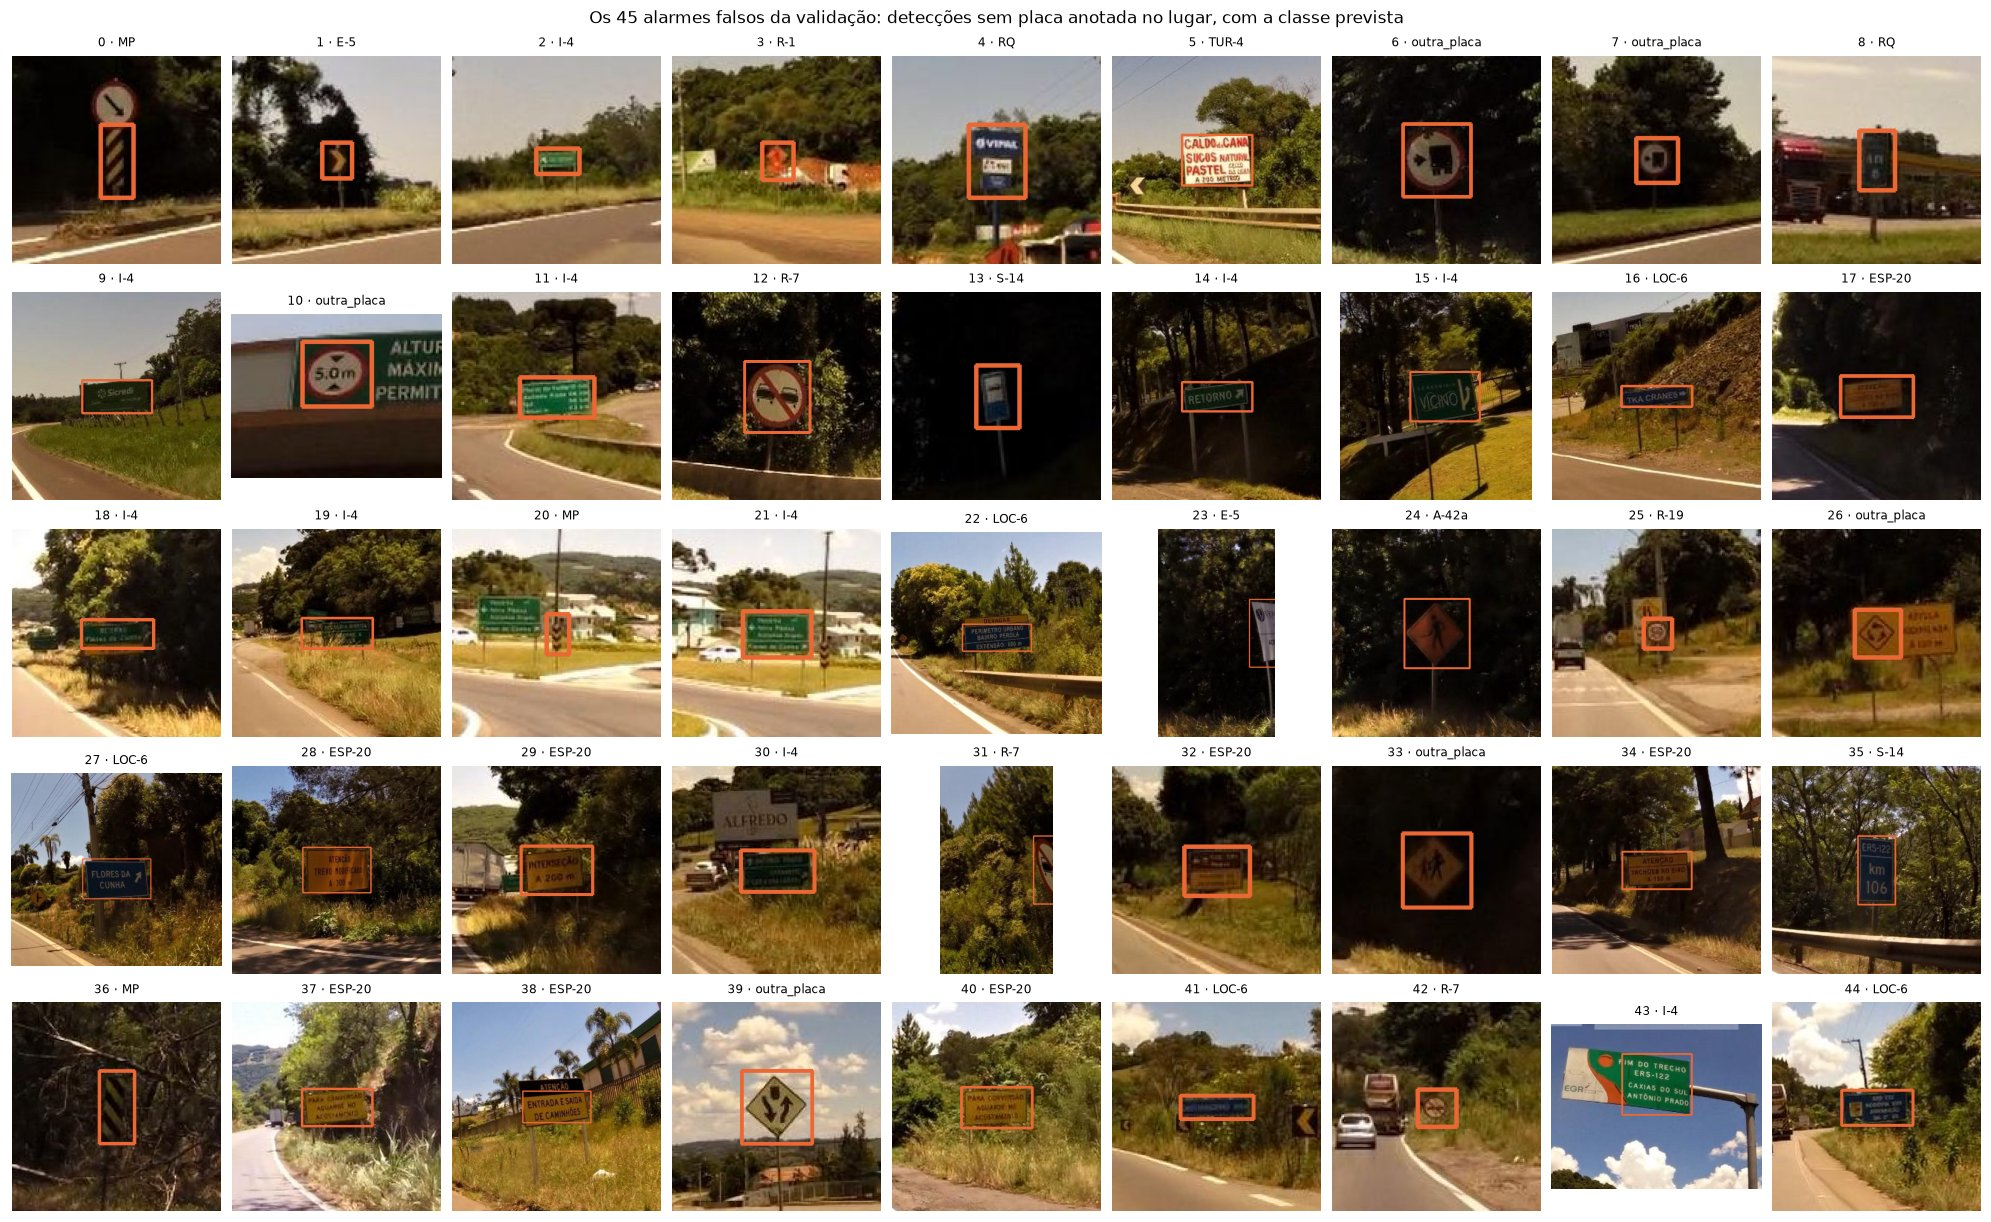

Inspecao visual (05/11/2026): vale para esta execucao, os alarmes sao os mesmos
julgamento
placa ou marcador real sem anotacao                  35
indefinido (cortado na borda, pequeno ou ambiguo)     6
nao e sinalizacao (anuncio ou objeto)                 4


In [47]:
FALSOS_VAL = ERROS_VAL[ERROS_VAL["anotada"] == FUNDO].reset_index(drop=True)
colunas = 9
linhas_fig = math.ceil(len(FALSOS_VAL) / colunas)
fig, eixos = plt.subplots(linhas_fig, colunas, figsize=(2.0 * colunas, 2.2 * linhas_fig), layout="constrained")
for k, eixo in enumerate(eixos.ravel()):
    eixo.axis("off")
    if k < len(FALSOS_VAL):
        r = FALSOS_VAL.loc[k]
        eixo.imshow(recorte(r["arquivo"], r["caixa"], "validacao", COR_CONJUNTO["validacao"], margem=1.6, minimo=70))
        eixo.set_title(f"{k} · {r['prevista']}", fontsize=8)
fig.suptitle(f"Os {len(FALSOS_VAL)} alarmes falsos da validação: detecções sem placa anotada no lugar, com a classe prevista")
salvar_figura(fig, DIR_FIGURAS / "09_alarmes_falsos_validacao.jpg")
mostrar_foto(fig)

# A inspecao visual foi feita uma vez, nesta figura, e ficou registrada em CSV, um julgamento por recorte.
INSPECAO = pd.read_csv(DIR_SAIDA / "inspecao_alarmes_falsos_validacao.csv")
mesmos = list(zip(INSPECAO["arquivo"], INSPECAO["prevista"])) == list(zip(FALSOS_VAL["arquivo"], FALSOS_VAL["prevista"]))
print("Inspecao visual (05/11/2026):", "vale para esta execucao, os alarmes sao os mesmos" if mesmos else
      "ATENCAO: os alarmes desta execucao mudaram; a inspecao registrada e a da execucao de 05/11")
print(INSPECAO["julgamento"].value_counts().to_string())

**Os alarmes falsos, na maioria, são placas de verdade que não foram anotadas.** Na inspeção
visual da figura acima, um recorte por vez, 35 dos 45 são placas ou marcadores reais sem
anotação: placas verdes de destino, placas amarelas de texto, marcadores de perigo e placas
circulares de proibição. Só 4 não são sinalização (anúncios, como o da Sicredi e o de uma banca
de caldo de cana), e 6 ficam indefinidos, cortados na borda ou pequenos demais. O caso mais
claro é o da `ESP-20`: o modelo a prevê 8 vezes, sempre em placas amarelas de texto, e o dia da
validação não tem nenhuma `ESP-20` anotada.

É a anotação esparsa já registrada na N1, e ela tem duas consequências para o diagnóstico: a
precisão medida é um piso, e o limiar de 0,41 foi escolhido contra um gabarito que pune acertos,
então tende a ficar um pouco alto. Cada julgamento está em
`outputs/n2/inspecao_alarmes_falsos_validacao.csv`.

---
## 9. Modelo contra a linha de base, no teste

O teste é usado uma vez, com o modelo escolhido e o limiar fixado na validação. A comparação
repete a Seção 5 ponto por ponto: as mesmas 403 imagens de 10/10 e 11/10, o mesmo gabarito sem
`Del`, a mesma função `avaliar_deteccao` e o mesmo casamento da N1. Só muda de onde vêm as
caixas. Como a linha de base não diz qual é a placa, a comparação direta é a de detecção. A
última linha da tabela exige também a classe certa, o que só o modelo faz.

In [48]:
inicio = time.time()
PRED_TESTE = predizer_conjunto("teste")
PRED_TESTE.to_csv(DIR_SAIDA / "predicoes_teste.csv", index=False, encoding="utf-8")
GAB_TESTE = gabarito_com_classe("teste")
assert {a: [c[1:] for c in g] for a, g in GAB_TESTE.items()} == GABARITO_TESTE, "gabarito diferente do da linha de base"
DET_TESTE = acima_do_limiar(PRED_TESTE, LIMIAR)
segundos = time.time() - inicio
print(f"Teste: {len(GAB_TESTE)} imagens em {segundos:.0f} s ({1000 * segundos / len(GAB_TESTE):.0f} ms por imagem) | "
      f"limiar {LIMIAR:.2f}, escolhido na validacao | {sum(map(len, DET_TESTE.values()))} deteccoes | "
      f"{sum(map(len, GAB_TESTE.values()))} placas anotadas")

# A mesma funcao, o mesmo gabarito e o mesmo casamento da Secao 5; muda so de onde vem a deteccao.
linhas = []
for l in (0.30, 0.50):
    linhas.append({"sistema": "Linha de base (N1)", "acerto": f"placa no lugar certo, IoU >= {l:.2f}",
                   **avaliar_deteccao(DET_CLASSICO, GABARITO_TESTE, l)})
    linhas.append({"sistema": f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})", "acerto": f"placa no lugar certo, IoU >= {l:.2f}",
                   **avaliar_deteccao(sem_classe(DET_TESTE), GABARITO_TESTE, l)})
linhas.append({"sistema": f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})", "acerto": "placa no lugar certo e classe certa, IoU >= 0.50",
               **avaliar_com_classe(DET_TESTE, GAB_TESTE, 0.50)})
MODELO_VS_BASE = pd.DataFrame(linhas).set_index(["acerto", "sistema"])
MODELO_VS_BASE.to_csv(DIR_SAIDA / "teste_modelo_vs_linha_de_base.csv", encoding="utf-8")
MODELO_VS_BASE

Teste: 403 imagens em 255 s (633 ms por imagem) | limiar 0.41, escolhido na validacao | 379 deteccoes | 263 placas anotadas


precisao  \
acerto                                           sistema                        
placa no lugar certo, IoU >= 0.30                Linha de base (N1)     0.115   
                                                 Modelo (small)         0.604   
placa no lugar certo, IoU >= 0.50                Linha de base (N1)     0.099   
                                                 Modelo (small)         0.604   
placa no lugar certo e classe certa, IoU >= 0.50 Modelo (small)         0.541   

                                                                     recall  \
acerto                                           sistema                      
placa no lugar certo, IoU >= 0.30                Linha de base (N1)   0.137   
                                                 Modelo (small)       0.871   
placa no lugar certo, IoU >= 0.50                Linha de base (N1)   0.118   
                                                 Modelo (small)       0.871   
placa no lugar certo e classe certa, IoU >= 0.50 Modelo (small)       0.779   

                                                                        f1  \
acerto                                           sistema                     
placa no lugar certo, IoU >= 0.30                Linha de base (N1)  0.125   
                                                 Modelo (small)      0.713   
placa no lugar certo, IoU >= 0.50                Linha de base (N1)  0.108   
                                                 Modelo (small)      0.713   
placa no lugar certo e classe certa, IoU >= 0.50 Modelo (small)      0.639   

                                                                      vp   fp  \
acerto                                           sistema                        
placa no lugar certo, IoU >= 0.30                Linha de base (N1)   36  277   
                                                 Modelo (small)      229  150   
placa no lugar certo, IoU >= 0.50                Linha de base (N1)   31  282   
                                                 Modelo (small)      229  150   
placa no lugar certo e classe certa, IoU >= 0.50 Modelo (small)      205  174   

                                                                      fn  
acerto                                           sistema                  
placa no lugar certo, IoU >= 0.30                Linha de base (N1)  227  
                                                 Modelo (small)       34  
placa no lugar certo, IoU >= 0.50                Linha de base (N1)  232  
                                                 Modelo (small)       34  
placa no lugar certo e classe certa, IoU >= 0.50 Modelo (small)       58

**No teste, o modelo tem F1 de detecção de 0,713, contra 0,108 da linha de base (IoU ≥ 0,50).**
Ele encontra 229 das 263 placas, contra 31 do pipeline clássico, e faz 150 detecções sem placa
anotada, contra 282. Com IoU ≥ 0,30, o critério da N1, a linha de base sobe para 0,125, e o
modelo não muda: as caixas dele que acertam uma placa já se sobrepõem a ela em pelo menos 0,50.
Exigindo também a classe certa, o F1 do modelo é 0,639: 205 das 263 placas saem localizadas e
identificadas.

### 9.1. Por dia de teste

A Seção 5.1 mostrou que a linha de base muda muito de um dia para outro. Aqui, os dois sistemas
são medidos em cada dia de teste separado.

In [49]:
dia_de = dict(zip(IMAGENS["arquivo"], IMAGENS["dia"]))
linhas = []
for dia in sorted({dia_de[a] for a in GAB_TESTE}):
    so_dia = {a for a in GAB_TESTE if dia_de[a] == dia}
    gab = {a: g for a, g in GABARITO_TESTE.items() if a in so_dia}
    base = avaliar_deteccao(DET_CLASSICO, gab, 0.50)
    modelo = avaliar_deteccao(sem_classe(DET_TESTE), gab, 0.50)
    com_classe = avaliar_com_classe(DET_TESTE, {a: g for a, g in GAB_TESTE.items() if a in so_dia}, 0.50)
    linhas.append({"dia": dia_curto(dia), "imagens": len(gab), "placas": sum(map(len, gab.values())),
                   "F1 linha de base": base["f1"], "F1 modelo": modelo["f1"],
                   "precisão modelo": modelo["precisao"], "recall modelo": modelo["recall"],
                   "F1 modelo, classe certa": com_classe["f1"]})
TESTE_POR_DIA = pd.DataFrame(linhas).set_index("dia")
TESTE_POR_DIA.to_csv(DIR_SAIDA / "teste_por_dia.csv", encoding="utf-8")
print("Deteccao com IoU >= 0,50, por dia de teste:")
TESTE_POR_DIA

Deteccao com IoU >= 0,50, por dia de teste:


,imagens,placas,F1 linha de base,F1 modelo,precisão modelo,recall modelo,"F1 modelo, classe certa"
dia,,,,,,,
10/10,228,145,0.071,0.689,0.584,0.841,0.610
11/10,175,118,0.160,0.743,0.629,0.907,0.674


O modelo ganha da linha de base nos dois dias e repete a ordem dela: 10/10 é o dia mais difícil
para os dois (F1 de 0,689 contra 0,071) e 11/10, o mais fácil (0,743 contra 0,160). A diferença
entre os dias cai de 0,09 de F1 na linha de base para 0,05 no modelo. O que torna 10/10 difícil,
então, está em parte nas próprias imagens, e não só no método.

### 9.2. mAP e desempenho por classe

O mAP é a métrica com que o modelo foi escolhido na validação, então é ele que mostra se a
validação previu bem o teste. A tabela por classe junta o recall com a classe certa, no limiar
de 0,41, ao AP50 de cada classe.

In [50]:
import contextlib, io

# mAP oficial do Ultralytics no teste, a mesma metrica da escolha do modelo na validacao. A barra de
# progresso vai para um buffer, para nao encher a saida da celula.
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    metricas = MODELO.val(data=str(ARQ_DATA_YAML), split="test", imgsz=IMGSZ, batch=4, plots=False, verbose=False,
                          project=str(DIR_TREINOS / "_validacao"), name="teste", exist_ok=True)
MAP_TESTE = {"mAP50": round(float(metricas.box.map50), 3), "mAP50_95": round(float(metricas.box.map), 3)}
ap50_teste = dict(zip((CLASSES_MODELO[int(k)] for k in metricas.box.ap_class_index), metricas.box.ap50))

ERROS_TESTE = tabela_de_erros(DET_TESTE, GAB_TESTE)
anot_teste = ERROS_TESTE[ERROS_TESTE["anotada"] != FUNDO]
POR_CLASSE_TESTE = pd.DataFrame({
    "placas_teste": anot_teste.groupby("anotada").size(),
    "classe_certa": anot_teste[anot_teste["anotada"] == anot_teste["prevista"]].groupby("anotada").size(),
    "nao_encontradas": anot_teste[anot_teste["prevista"] == FUNDO].groupby("anotada").size(),
}).reindex(CLASSES_MODELO).fillna(0).astype(int)
POR_CLASSE_TESTE["recall"] = (POR_CLASSE_TESTE["classe_certa"] / POR_CLASSE_TESTE["placas_teste"]).round(2)
POR_CLASSE_TESTE["AP50"] = pd.Series(ap50_teste).reindex(CLASSES_MODELO).round(3)
POR_CLASSE_TESTE["placas_treino"] = CONTAGEM_MODELO["treino"]
POR_CLASSE_TESTE = POR_CLASSE_TESTE.sort_values("placas_teste", ascending=False, kind="stable")
POR_CLASSE_TESTE.to_csv(DIR_SAIDA / "teste_por_classe.csv", encoding="utf-8")

(DIR_SAIDA / "teste_resumo.json").write_text(json.dumps({
    "modelo": MODELO_ESCOLHIDO, "limiar_confianca": LIMIAR, "limiar_escolhido_em": "validacao",
    "imagens": len(GAB_TESTE), "placas_anotadas": int(sum(map(len, GAB_TESTE.values()))), **MAP_TESTE,
    "deteccao_iou_050": MODELO_VS_BASE.loc[("placa no lugar certo, IoU >= 0.50", f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})")].to_dict(),
    "classe_certa_iou_050": MODELO_VS_BASE.loc[("placa no lugar certo e classe certa, IoU >= 0.50", f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})")].to_dict(),
    "linha_de_base_iou_050": MODELO_VS_BASE.loc[("placa no lugar certo, IoU >= 0.50", "Linha de base (N1)")].to_dict(),
}, ensure_ascii=False, indent=2, default=int), encoding="utf-8")

print(f"Teste: mAP50 {MAP_TESTE['mAP50']:.3f} e mAP50-95 {MAP_TESTE['mAP50_95']:.3f} "
      f"(validacao: {COMPARACAO.loc[MODELO_ESCOLHIDO, 'mAP50']:.3f} e {COMPARACAO.loc[MODELO_ESCOLHIDO, 'mAP50_95']:.3f})")
desfechos = anot_teste.assign(certa=anot_teste["anotada"] == anot_teste["prevista"], perdida=anot_teste["prevista"] == FUNDO)
print(f"{len(anot_teste)} placas: {desfechos['certa'].sum()} com a classe certa, {desfechos['perdida'].sum()} nao encontradas, "
      f"{(~desfechos['certa'] & ~desfechos['perdida']).sum()} com a classe errada | "
      f"{int((ERROS_TESTE['anotada'] == FUNDO).sum())} alarmes falsos")
POR_CLASSE_TESTE

Ultralytics 8.4.182  Python-3.14.4 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-1355U)


YOLO26s summary (fused): 120 layers, 9,475,629 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 448.0±95.7 MB/s, size: 87.8 KB)


val: New cache created: <dados locais>\n2_yolo\teste\labels.cache


                   all        403        263      0.513      0.751      0.736      0.478


Speed: 4.0ms preprocess, 495.3ms inference, 0.0ms loss, 1.4ms postprocess per image


Teste: mAP50 0.736 e mAP50-95 0.478 (validacao: 0.770 e 0.443)
263 placas: 205 com a classe certa, 34 nao encontradas, 24 com a classe errada | 150 alarmes falsos


,placas_teste,classe_certa,nao_encontradas,recall,AP50,placas_treino
anotada,,,,,,
outra_placa,33,16,10,0.48,0.511,109
R-19,31,31,0,1.00,0.586,222
R-1,27,23,3,0.85,0.824,61
R-2,19,17,1,0.89,0.933,58
S-14,18,16,2,0.89,0.899,91
I-4,16,14,1,0.88,0.853,121
MP,15,13,2,0.87,0.961,41
A-2b,13,13,0,1.00,0.896,78
LOC-6,11,10,1,0.91,0.794,57


**O teste confirma a validação.** O mAP50 vai de 0,770 na validação para 0,736 no teste, e o
mAP50-95 sobe de 0,443 para 0,478. A validação, que é um dia só, não estava otimista, e o modelo
generaliza para dois dias que nunca viu. Se essa generalização é para placas novas ou só para dias
novos depende de a mesma placa física não estar no treino, o que a Seção 9.4 verifica.

Dois pontos da tabela por classe:

- **`R-19` tem recall de 100% e AP50 de só 0,586.** O modelo acerta as 31 placas de velocidade
  máxima anotadas, mas faz outras 61 detecções de `R-19` onde não há anotação. A Seção 9.3
  mostra o que elas são.
- **As oito `A-21e` do teste saem todas com a classe errada:** quatro como `A-22`, duas como
  `A-42a`, uma como `A-6` e uma como `outra_placa`. São todas losangos amarelos cujo pictograma
  são linhas de pista que se estreitam, se alargam ou se cruzam, e cada uma tem de 10 a 14
  exemplos no treino. É a mesma família de trocas da validação, mais visível porque o teste tem
  mais `A-21e`.

### 9.3. Os erros no teste

A primeira figura sorteia seis exemplos de cada tipo de erro. A segunda sorteia 54 dos 150
alarmes falsos, inspecionados um a um, como na validação.

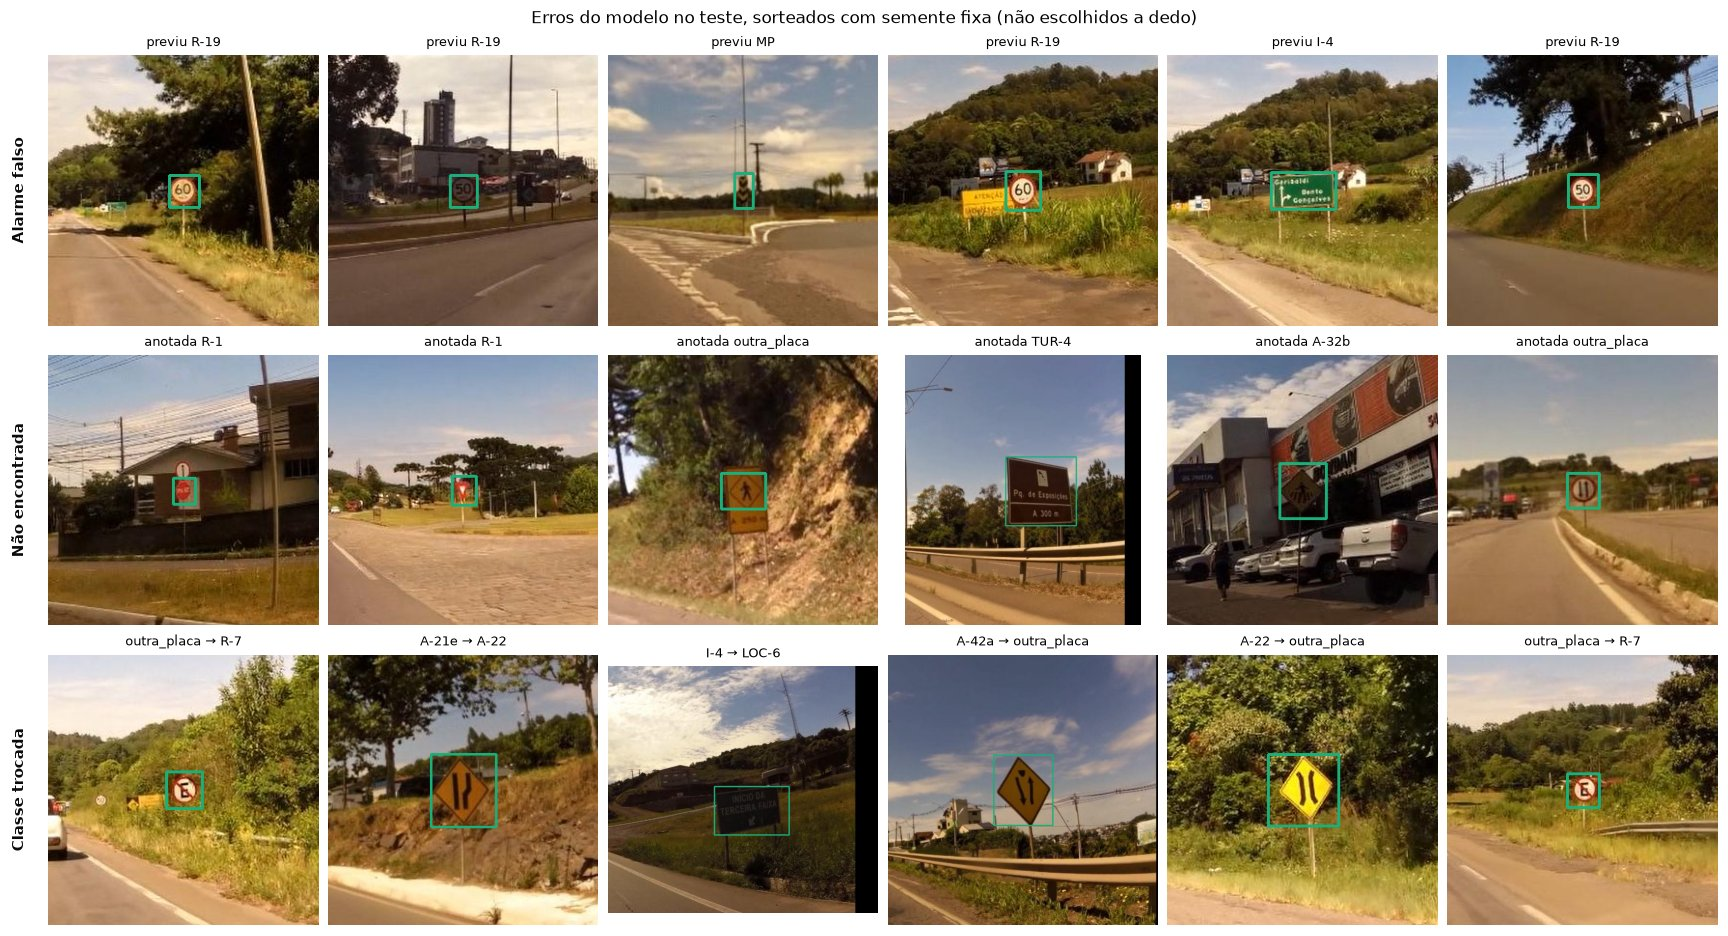

In [51]:
painel_de_erros(ERROS_TESTE, "teste", 6, "10_erros_teste.jpg",
                "Erros do modelo no teste, sorteados com semente fixa (não escolhidos a dedo)")

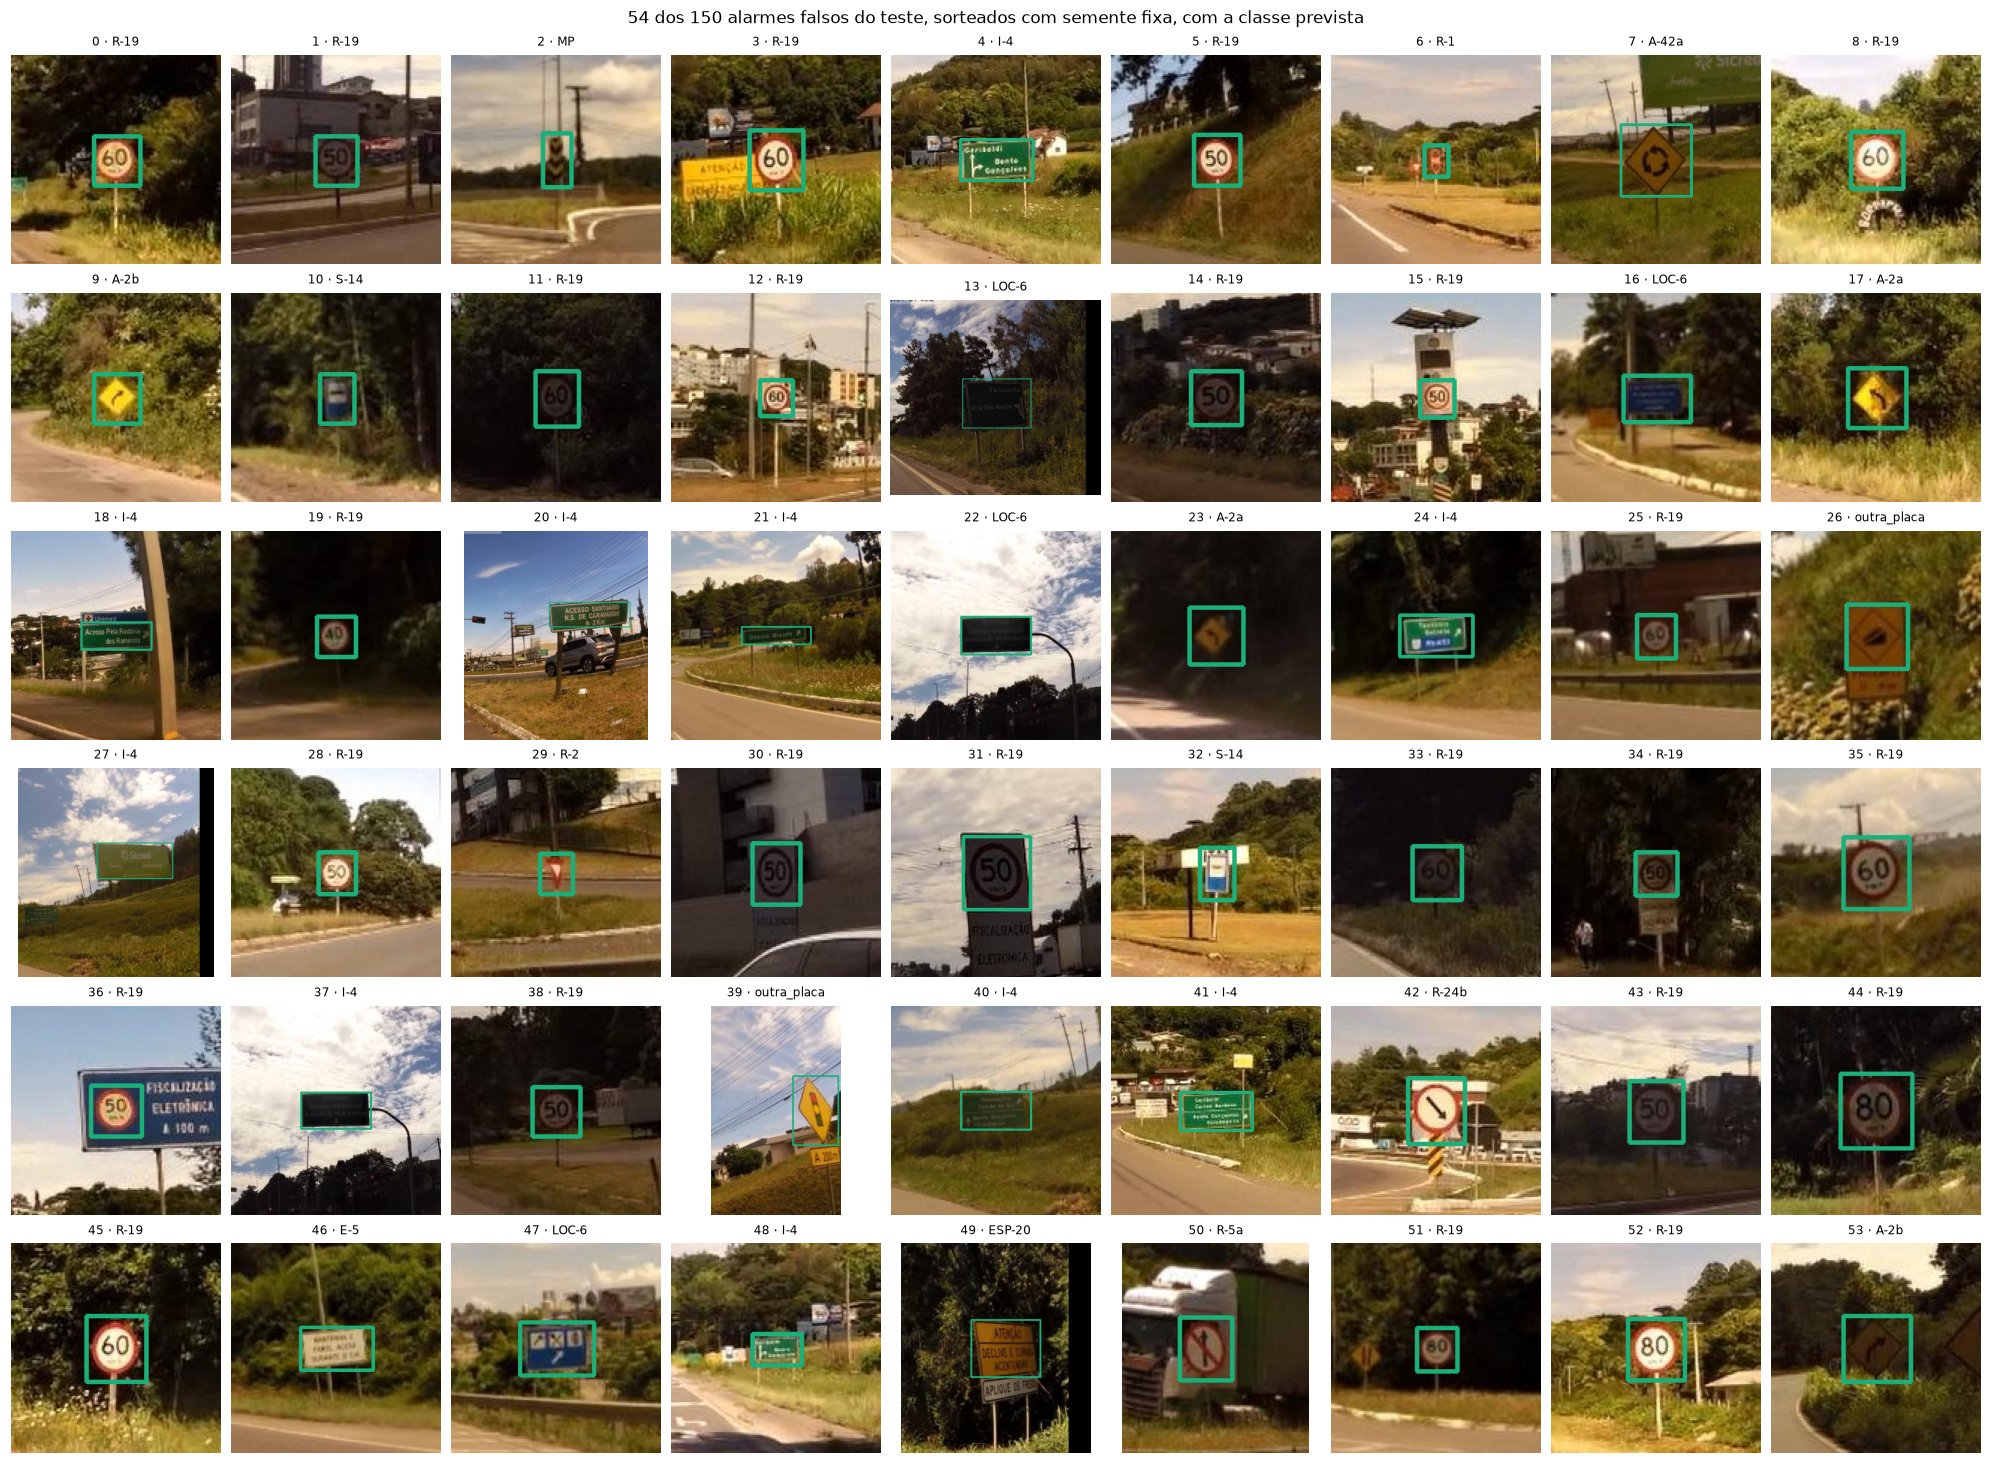

Inspecao visual (06/11/2026): vale para esta execucao, a amostra e a mesma
julgamento
placa ou marcador real sem anotacao                  49
indefinido (cortado na borda, pequeno ou ambiguo)     4
nao e placa (anuncio, semaforo ou objeto)             1

Alarmes falsos por classe prevista (todos os 150): {'R-19': 61, 'I-4': 29, 'LOC-6': 9, 'R-1': 7}


In [52]:
FALSOS_TESTE = ERROS_TESTE[ERROS_TESTE["anotada"] == FUNDO]
AMOSTRA_FALSOS = FALSOS_TESTE.sample(54, random_state=SEMENTE).reset_index(drop=True)
colunas = 9
fig, eixos = plt.subplots(len(AMOSTRA_FALSOS) // colunas, colunas, figsize=(2.0 * colunas, 13.2), layout="constrained")
for k, eixo in enumerate(eixos.ravel()):
    r = AMOSTRA_FALSOS.loc[k]
    eixo.imshow(recorte(r["arquivo"], r["caixa"], "teste", COR_CONJUNTO["teste"], margem=1.6, minimo=70))
    eixo.set_title(f"{k} · {r['prevista']}", fontsize=8)
    eixo.axis("off")
fig.suptitle(f"54 dos {len(FALSOS_TESTE)} alarmes falsos do teste, sorteados com semente fixa, com a classe prevista")
salvar_figura(fig, DIR_FIGURAS / "11_alarmes_falsos_teste.jpg")
mostrar_foto(fig)

INSPECAO_TESTE = pd.read_csv(DIR_SAIDA / "inspecao_alarmes_falsos_teste_amostra.csv")
mesmos = list(zip(INSPECAO_TESTE["arquivo"], INSPECAO_TESTE["prevista"])) == list(zip(AMOSTRA_FALSOS["arquivo"], AMOSTRA_FALSOS["prevista"]))
print("Inspecao visual (06/11/2026):", "vale para esta execucao, a amostra e a mesma" if mesmos else
      "ATENCAO: a amostra desta execucao mudou; a inspecao registrada e a da execucao de 06/11")
print(INSPECAO_TESTE["julgamento"].value_counts().to_string())
print(f"\nAlarmes falsos por classe prevista (todos os {len(FALSOS_TESTE)}):",
      FALSOS_TESTE["prevista"].value_counts().head(4).to_dict())

**No teste, quase todo alarme falso é uma placa real sem anotação.** Dos 54 sorteados, 49 são
placas reais, a maioria com a classe certa: placas de velocidade máxima de 40, 50, 60 e 80 km/h,
curvas, placas verdes de destino. Só 1 não é placa (um semáforo, previsto como `MP`), e 4 ficam
indefinidos. As 61 `R-19` sem anotação são, em boa parte, placas de velocidade máxima legíveis, a
poucos metros da câmera. Nos dois dias de teste, a anotação deixou de fora uma fração maior das
placas do que no dia da validação (49 de 54 contra 35 de 45).

A consequência é direta: a precisão de 0,604 no teste é um piso, bem abaixo do valor real. O
número oficial continua sendo 0,604, medido contra o gabarito como ele é; corrigi-lo pela
amostra dependeria de um julgamento visual, e a correção certa é revisar as anotações (Seção 11).
Para a comparação com a linha de base, isso joga a favor do clássico: os dois são medidos contra
o mesmo gabarito, a placa não anotada só pune quem a encontra, e o modelo encontra muito mais. O
ganho medido é um ganho mínimo. Cada julgamento da amostra está em
`outputs/n2/inspecao_alarmes_falsos_teste_amostra.csv`.

### 9.4. A mesma placa em dias diferentes?

A divisão por dia (Seção 2) separa as sessões de captura, mas não garante que a mesma placa física
fique fora do teste: se o carro passou pela mesma estrada em dois dias, a placa aparece nos dois. O
enunciado proíbe exatamente isso ("imagens do mesmo objeto"), e o mAP50 de 0,77 na validação ficou
acima do que a equipe esperava, então a verificação vem antes de aceitar o número.

Sem GPS, ela é visual, em duas etapas:

1. **Busca automática.** A cena em volta de cada placa de validação e teste é comparada com a cena
   em volta de cada placa de treino da mesma classe, por pontos SIFT e uma homografia estimada com
   RANSAC: são 44 mil pares. A própria placa é mascarada, porque o pictograma é igual em toda placa
   do mesmo tipo e casaria sempre; o que identifica o lugar é o entorno (poste, cerca, morro,
   construções). O resultado de cada par é o número de correspondências que cabem numa mesma
   geometria.
2. **Revisão a olho.** O número sozinho não decide: vegetação e o texto de outras placas produzem
   dezenas de correspondências entre lugares diferentes. Por isso, todo par com 30 correspondências
   ou mais, ou com 20 ou mais e uma vez e meia o segundo melhor par da mesma placa, foi aberto em
   quadro inteiro e julgado. O julgamento de cada par está em `outputs/n2/inspecao_vazamento.csv`.

Na CPU, a busca leva de 6 a 13 minutos.

In [53]:
SIFT = cv2.SIFT_create(nfeatures=1500)
BF = cv2.BFMatcher(cv2.NORM_L2)


def placas_do_conjunto(nome: str) -> pd.DataFrame:
    """Uma linha por placa anotada na base do YOLO: arquivo, posicao no rotulo, classe e caixa."""
    linhas = []
    for rotulo in sorted((DIR_YOLO / nome / "labels").glob("*.txt")):
        for k, linha in enumerate(rotulo.read_text(encoding="utf-8").split("\n")):
            if linha.strip():
                c, cx, cy, w, h = linha.split()
                linhas.append({"conjunto": nome, "arquivo": rotulo.stem + ".jpg", "k": k,
                               "classe": CLASSES_MODELO[int(c)], "cx": float(cx), "cy": float(cy),
                               "w": float(w), "h": float(h)})
    return pd.DataFrame(linhas)


def descrever_contexto(reg) -> tuple:
    """Pontos SIFT da cena em volta da placa, com a propria placa mascarada.

    O pictograma e igual em toda placa do mesmo tipo e casaria sempre; o que identifica o lugar
    e o entorno: poste, cerca, morro, construcoes. A janela tem 8 x 6 vezes o tamanho da placa
    (no minimo 480 x 320 px) e e levada a 480 px no lado maior.
    """
    cinza = cv2.imdecode(np.fromfile(str(DIR_YOLO / reg.conjunto / "images" / reg.arquivo), np.uint8),
                         cv2.IMREAD_GRAYSCALE)
    H, W = cinza.shape
    bw, bh = reg.w * W, reg.h * H
    jw, jh = min(W, max(480, 8 * bw)), min(H, max(320, 6 * bh))
    x0 = int(np.clip(reg.cx * W - jw / 2, 0, W - jw))
    y0 = int(np.clip(reg.cy * H - jh / 2, 0, H - jh))
    janela = cinza[y0:y0 + int(jh), x0:x0 + int(jw)]
    escala = 480 / max(janela.shape)
    janela = cv2.resize(janela, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    mascara = np.full(janela.shape, 255, np.uint8)
    mx0, my0 = int((reg.cx * W - 0.65 * bw - x0) * escala), int((reg.cy * H - 0.65 * bh - y0) * escala)
    mx1, my1 = int((reg.cx * W + 0.65 * bw - x0) * escala), int((reg.cy * H + 0.65 * bh - y0) * escala)
    mascara[max(0, my0):max(0, my1), max(0, mx0):max(0, mx1)] = 0
    pontos, desc = SIFT.detectAndCompute(janela, mascara)
    return np.float32([p.pt for p in pontos]).reshape(-1, 2), desc


def correspondencias(a: tuple, b: tuple) -> int:
    """Pares SIFT que passam no teste da razao de Lowe e cabem numa mesma homografia (RANSAC)."""
    (pa, da), (pb, db) = a, b
    if da is None or db is None or len(da) < 8 or len(db) < 8:
        return 0
    boas = [m for m, n in (x for x in BF.knnMatch(da, db, k=2) if len(x) == 2) if m.distance < 0.75 * n.distance]
    if len(boas) < 8:
        return len(boas) // 4
    _, dentro = cv2.findHomography(pa[[m.queryIdx for m in boas]], pb[[m.trainIdx for m in boas]], cv2.RANSAC, 6.0)
    return int(dentro.sum()) if dentro is not None else 0


inicio = time.time()
PLACAS_TREINO = placas_do_conjunto("treino")
PLACAS_RETIDAS = pd.concat([placas_do_conjunto("validacao"), placas_do_conjunto("teste")], ignore_index=True)
CONTEXTO_TREINO = [descrever_contexto(r) for r in PLACAS_TREINO.itertuples()]
mesma_classe = {c: np.flatnonzero(PLACAS_TREINO["classe"].to_numpy() == c) for c in CLASSES_MODELO}
cv2.setRNGSeed(SEMENTE)          # o RANSAC sorteia amostras; a semente fixa o resultado
linhas, n_pares = [], 0
for r in PLACAS_RETIDAS.itertuples(index=False):
    contexto = descrever_contexto(r)
    candidatos = mesma_classe[r.classe]
    notas = np.array([correspondencias(contexto, CONTEXTO_TREINO[j]) for j in candidatos])
    n_pares += len(candidatos)
    j = candidatos[int(np.argmax(notas))]
    linhas.append({**r._asdict(), "inliers": int(notas.max()),
                   "segundo": int(np.sort(notas)[-2]) if len(notas) > 1 else 0,
                   "par_arquivo": PLACAS_TREINO.loc[j, "arquivo"], "par_k": int(PLACAS_TREINO.loc[j, "k"])})
PARES_VAZAMENTO = pd.DataFrame(linhas)
PARES_VAZAMENTO.to_csv(DIR_SAIDA / "vazamento_pares.csv", index=False, encoding="utf-8")
melhor = PARES_VAZAMENTO["inliers"]
print(f"{len(PLACAS_RETIDAS)} placas de validacao e teste comparadas com as {len(PLACAS_TREINO)} do treino "
      f"da mesma classe: {n_pares} pares em {time.time() - inicio:.0f} s")
print(f"Melhor par de cada placa, em correspondencias: mediana {melhor.median():.0f}, "
      f"percentil 90 {melhor.quantile(0.9):.0f}, maximo {melhor.max()}")

517 placas de validacao e teste comparadas com as 1219 do treino da mesma classe: 44387 pares em 987 s
Melhor par de cada placa, em correspondencias: mediana 11, percentil 90 22, maximo 77


Pares revisados a olho: 40 (30 correspondencias ou mais, ou 20 ou mais e 1,5 vez o segundo melhor par)
Revisao visual (06/11/2026): vale para esta execucao, os pares sao os mesmos
julgamento
lugares diferentes                                                                27
lugares diferentes (a foto do par tem um portico com varias placas de texto)       9
mesmo lugar                                                                        3
mesma placa de um caso confirmado (o mesmo PARE); o par apontado e outro lugar     1


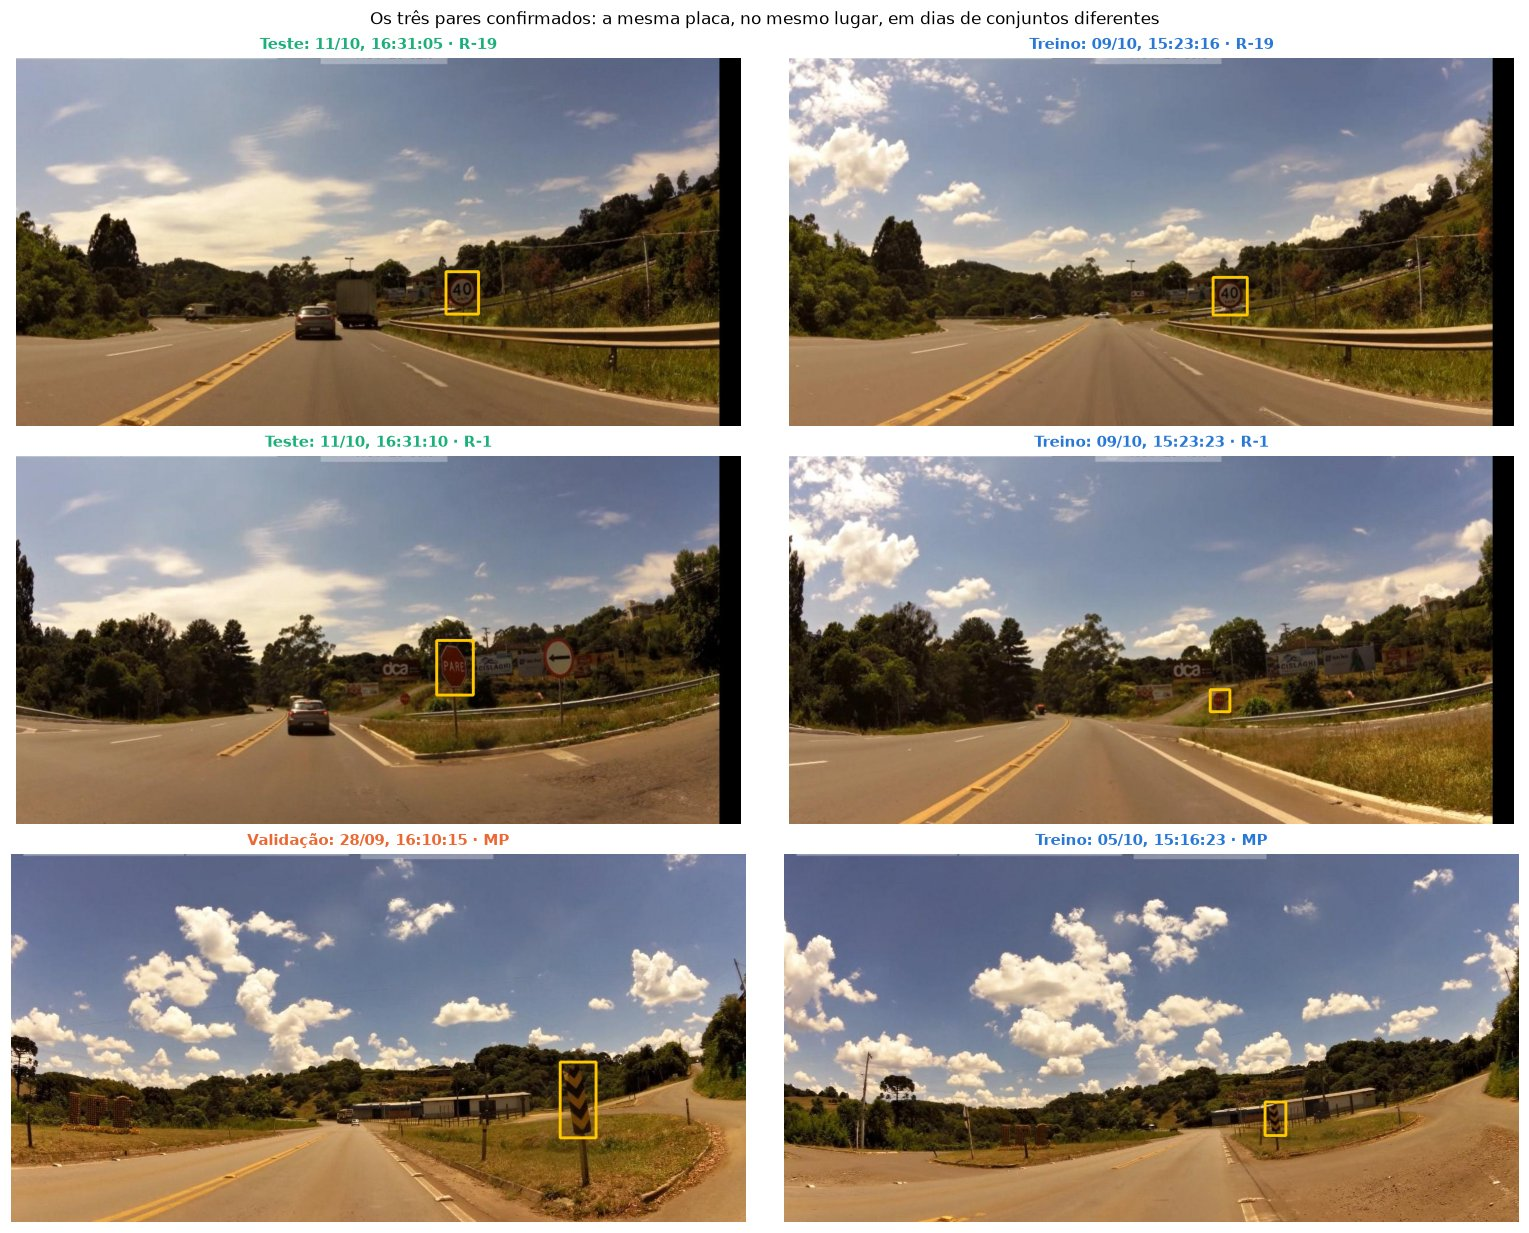

Placas de validacao e teste que estao tambem no treino: 5


,conjunto,arquivo,classe,par_no_treino,como_foi_confirmado
0,teste,"11/10, 16:31:05",R-19,"09/10, 15:23:16","par revisado: mesmo lugar (placa de 40 km/h, m..."
1,teste,"11/10, 16:31:10",R-1,"09/10, 15:23:23","par revisado: mesmo lugar (PARE no trevo, mesm..."
2,teste,"11/10, 16:31:10",outra_placa,"09/10, 15:23:21","a placa redonda ao lado do PARE confirmado, an..."
3,teste,"11/10, 16:31:11",R-1,"09/10, 15:23:23","o mesmo PARE, um quadro depois"
4,validacao,"28/09, 16:10:15",MP,"05/10, 15:16:23","par revisado: mesmo lugar (marcador de perigo,..."


In [54]:
REVISADOS = PARES_VAZAMENTO[(PARES_VAZAMENTO["inliers"] >= 30)
                            | ((PARES_VAZAMENTO["inliers"] >= 20)
                               & (PARES_VAZAMENTO["inliers"] >= 1.5 * PARES_VAZAMENTO["segundo"]))]
INSPECAO_VAZ = pd.read_csv(DIR_SAIDA / "inspecao_vazamento.csv")
chave = lambda t: set(zip(t["arquivo"], t["k"], t["par_arquivo"]))    # noqa: E731
print(f"Pares revisados a olho: {len(REVISADOS)} (30 correspondencias ou mais, ou 20 ou mais e 1,5 vez o "
      f"segundo melhor par)")
print("Revisao visual (06/11/2026):", "vale para esta execucao, os pares sao os mesmos"
      if chave(INSPECAO_VAZ) == chave(REVISADOS) else
      "ATENCAO: os pares desta execucao mudaram; a revisao registrada e a da execucao de 06/11")
print(INSPECAO_VAZ["julgamento"].value_counts().to_string())

REPETIDAS = pd.read_csv(DIR_SAIDA / "vazamento_confirmado.csv")


def quadro_com_caixa(conjunto: str, arquivo: str, k: int) -> np.ndarray:
    """Quadro inteiro, RGB, com a k-esima caixa do rotulo desenhada."""
    bgr = cv2.imdecode(np.fromfile(str(DIR_YOLO / conjunto / "images" / arquivo), np.uint8), cv2.IMREAD_COLOR)
    H, W = bgr.shape[:2]
    linha = (DIR_YOLO / conjunto / "labels" / f"{Path(arquivo).stem}.txt").read_text(encoding="utf-8").split("\n")[k]
    _, cx, cy, w, h = (float(v) for v in linha.split())
    cv2.rectangle(bgr, (int((cx - w / 2) * W) - 6, int((cy - h / 2) * H) - 6),
                  (int((cx + w / 2) * W) + 6, int((cy + h / 2) * H) + 6), (0, 200, 255), 4)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def quando(arquivo: str) -> str:
    d = re.search(PADRAO_INSTANTE, arquivo).group(1)
    return f"{d[8:10]}/{d[5:7]}, {d[11:13]}:{d[14:16]}:{d[17:19]}"


revisados_ok = REPETIDAS[REPETIDAS["como_foi_confirmado"].str.startswith("par revisado")]
fig, eixos = plt.subplots(len(revisados_ok), 2, figsize=(14, 3.7 * len(revisados_ok)), layout="constrained")
for (a, b), r in zip(eixos, revisados_ok.itertuples()):
    a.imshow(quadro_com_caixa(r.conjunto, r.arquivo, r.k))
    a.set_title(f"{NOME_CONJUNTO[r.conjunto]}: {quando(r.arquivo)} · {r.classe}", color=COR_CONJUNTO[r.conjunto],
                fontweight="bold")
    b.imshow(quadro_com_caixa("treino", r.par_no_treino, r.par_k))
    b.set_title(f"Treino: {quando(r.par_no_treino)} · {r.classe}", color=COR_CONJUNTO["treino"], fontweight="bold")
    a.axis("off")
    b.axis("off")
fig.suptitle("Os três pares confirmados: a mesma placa, no mesmo lugar, em dias de conjuntos diferentes")
salvar_figura(fig, DIR_FIGURAS / "12_mesma_placa_em_dias_diferentes.jpg")
mostrar_foto(fig)

print(f"Placas de validacao e teste que estao tambem no treino: {len(REPETIDAS)}")
REPETIDAS.assign(arquivo=REPETIDAS["arquivo"].map(quando), par_no_treino=REPETIDAS["par_no_treino"].map(quando))[
    ["conjunto", "arquivo", "classe", "par_no_treino", "como_foi_confirmado"]]

**Há vazamento, e ele é pequeno.** Dos 40 pares revisados, 3 são o mesmo lugar: uma placa de
40 km/h e um PARE num trevo, no teste de 11/10 e no treino de 09/10, e um marcador de perigo, na
validação de 28/09 e no treino de 05/10. Os outros 37 são lugares diferentes com o mesmo tipo de
placa. Contando os quadros vizinhos da mesma passagem e a placa redonda ao lado do PARE, que também
está anotada no treino, são 5 placas: 4 das 263 do teste (1,5%) e 1 das 254 da validação (0,4%).
Outro PARE do mesmo trevo, numa alça à direita, ficou fora da lista: é outra placa física, e não
aparece anotada em nenhuma foto do treino.

A tabela abaixo mede o efeito: as métricas com todas as imagens e sem as imagens dessas 5 placas.

In [55]:
imagens_repetidas = set(REPETIDAS["arquivo"])
linhas = []
for nome, gabarito, deteccoes in (("validacao", GAB_VALIDACAO, DET_VALIDACAO), ("teste", GAB_TESTE, DET_TESTE)):
    for rotulo, manter in (("todas", lambda a: True), ("sem as imagens repetidas", lambda a: a not in imagens_repetidas)):
        g = {a: v for a, v in gabarito.items() if manter(a)}
        deteccao = avaliar_deteccao(sem_classe(deteccoes), {a: [x[1:] for x in v] for a, v in g.items()}, 0.50)
        com_classe = avaliar_com_classe(deteccoes, g, 0.50)
        linhas.append({"conjunto": NOME_CONJUNTO[nome], "imagens": rotulo, "n_imagens": len(g),
                       "placas": sum(map(len, g.values())), "F1 detecção": deteccao["f1"],
                       "F1 classe certa": com_classe["f1"]})
IMPACTO_VAZAMENTO = pd.DataFrame(linhas).set_index(["conjunto", "imagens"])
IMPACTO_VAZAMENTO.to_csv(DIR_SAIDA / "vazamento_impacto.csv", encoding="utf-8")

erros = pd.concat([ERROS_VAL, ERROS_TESTE])
nas_repetidas = erros[erros["arquivo"].isin(imagens_repetidas) & (erros["anotada"] != FUNDO)]
certas = int((nas_repetidas["anotada"] == nas_repetidas["prevista"]).sum())
print(f"Nas {len(nas_repetidas)} placas repetidas, o modelo acerta {certas} com a classe certa (IoU >= 0,50, "
      f"limiar {LIMIAR:.2f}).\n")
IMPACTO_VAZAMENTO

Nas 5 placas repetidas, o modelo acerta 4 com a classe certa (IoU >= 0,50, limiar 0.41).



n_imagens  placas  F1 detecção  \
conjunto  imagens                                                    
Validação todas                           399     254        0.806   
          sem as imagens repetidas        398     253        0.806   
Teste     todas                           403     263        0.713   
          sem as imagens repetidas        400     259        0.712   

                                    F1 classe certa  
conjunto  imagens                                    
Validação todas                               0.731  
          sem as imagens repetidas            0.729  
Teste     todas                               0.639  
          sem as imagens repetidas            0.636

**O vazamento não muda os resultados.** Sem as imagens repetidas, o F1 de detecção no teste vai de
0,713 para 0,712, e o F1 com a classe certa, de 0,639 para 0,636; na validação, o F1 com a classe
certa vai de 0,731 para 0,729. O modelo acerta 4 das 5 placas repetidas, mas elas são poucas demais
para pesar no resultado. A divisão por dia cumpriu o papel dela: o teste mede placas que o modelo
não viu, com exceção de um trevo.

O limite da verificação é o da busca: ela acha a mesma placa quando a câmera passou perto do mesmo
ponto e na mesma mão. Uma placa vista de muito mais longe, ou do outro lado da estrada, pode escapar,
assim como um par abaixo do corte de revisão. Os dois casos encontrados ficam registrados em
`outputs/n2/vazamento_confirmado.csv`; para a entrega final, a opção mais limpa é mover o trevo de
11/10 para fora do teste, o que exige retreinar.

### 9.5. O ganho justifica o custo?

O modelo ganha da linha de base em acerto; esta seção mede quanto ele custa para rodar. Os dois
sistemas processam as mesmas 100 imagens de teste, sorteadas, na mesma máquina, e o tempo vai da
leitura do arquivo até o resultado final, com tudo o que cada um faz no meio. A linha da GPU é a
medida do Colab na Seção 7, só a passagem pela rede.

In [56]:
import platform

# As mesmas 100 imagens de teste, sorteadas, para os dois sistemas. O tempo vai da leitura do
# arquivo ate o resultado final, nesta maquina; a primeira chamada de cada um fica de fora.
AMOSTRA_TEMPO = pd.Series(sorted(GAB_TESTE)).sample(100, random_state=SEMENTE).tolist()
caminhos_tempo = [DIR_YOLO / "teste" / "images" / a for a in AMOSTRA_TEMPO]
N1["executar_pipeline"](caminhos_tempo[0], PARAMS_N1)
inferir.inferir(MODELO, CONFIG_INFERENCIA, caminhos_tempo[0], LIMIAR)


def cronometrar(funcao) -> np.ndarray:
    """Milissegundos de cada chamada."""
    tempos = []
    for caminho in caminhos_tempo:
        inicio = time.perf_counter()
        funcao(caminho)
        tempos.append(1000 * (time.perf_counter() - inicio))
    return np.array(tempos)


TEMPO_BASE = cronometrar(lambda c: N1["executar_pipeline"](c, PARAMS_N1))
TEMPO_MODELO = cronometrar(lambda c: inferir.inferir(MODELO, CONFIG_INFERENCIA, c, LIMIAR))
processador = platform.processor() or platform.machine()
print(f"Tempo medido em {len(caminhos_tempo)} imagens de teste, CPU desta execucao: {processador} "
      f"({os.cpu_count()} nucleos logicos) | GPU: {GPU or 'nenhuma'}")

linha_base = MODELO_VS_BASE.loc[("placa no lugar certo, IoU >= 0.50", "Linha de base (N1)")]
linha_modelo = MODELO_VS_BASE.loc[("placa no lugar certo, IoU >= 0.50", f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})")]
CUSTO = pd.DataFrame({
    "F1 de detecção no teste (IoU >= 0,50)": [linha_base["f1"], linha_modelo["f1"]],
    "placas encontradas no teste": [f"{int(linha_base['vp'])} de 263", f"{int(linha_modelo['vp'])} de 263"],
    "ms por imagem na CPU (mediana)": [round(np.median(TEMPO_BASE)), round(np.median(TEMPO_MODELO))],
    "ms por imagem na CPU (percentil 90)": [round(np.percentile(TEMPO_BASE, 90)), round(np.percentile(TEMPO_MODELO, 90))],
    "imagens por segundo na CPU": [round(1000 / np.median(TEMPO_BASE), 1), round(1000 / np.median(TEMPO_MODELO), 1)],
    "ms por imagem na GPU T4 (só a rede)": ["não usa GPU", COMPARACAO.loc[MODELO_ESCOLHIDO, "ms_por_imagem"]],
    "tamanho do que precisa ser distribuído": ["código + parametros_adotados.json (poucos kB)",
                                                f"código + modelo_n2.pt ({ARQ_MODELO.stat().st_size / 1e6:.0f} MB)"],
}, index=["Linha de base (N1)", f"Modelo ({NOME_TAMANHO[MODELO_ESCOLHIDO]})"]).T
CUSTO.to_csv(DIR_SAIDA / "custo_linha_de_base_vs_modelo.csv", encoding="utf-8")
CUSTO

Tempo medido em 100 imagens de teste, CPU desta execucao: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel (12 nucleos logicos) | GPU: nenhuma


,Linha de base (N1),Modelo (small)
"F1 de detecção no teste (IoU >= 0,50)",0.108,0.713
placas encontradas no teste,31 de 263,229 de 263
ms por imagem na CPU (mediana),148,513
ms por imagem na CPU (percentil 90),168,597
imagens por segundo na CPU,6.8,1.9
ms por imagem na GPU T4 (só a rede),não usa GPU,28.5
tamanho do que precisa ser distribuído,código + parametros_adotados.json (poucos kB),código + modelo_n2.pt (20 MB)


**O modelo é cerca de 3,5 vezes mais lento que a linha de base na CPU, e encontra 7 vezes mais
placas.** Numa CPU de notebook, a linha de base processa uma imagem em 148 ms (6,8 por segundo) e o
modelo em 513 ms (1,9 por segundo), da leitura do arquivo ao resultado. Numa GPU T4, a rede leva
28,5 ms por imagem, mais de 30 imagens por segundo, o que basta para vídeo em tempo real; a linha
de base não tem como usar GPU.

**O ganho justifica o custo.** A linha de base perde 7 de cada 8 placas, e 9 de cada 10 detecções
dela não batem com nenhuma placa anotada: nenhuma velocidade compensa isso. O custo a mais do modelo
tem três partes:

- **Tempo de inferência:** 3,5 vezes o da linha de base na CPU, e resolvido com GPU.
- **Distribuição:** um arquivo de pesos de 20 MB, contra poucos kB de parâmetros.
- **Treino:** cerca de 1 hora de GPU T4 para os dois tamanhos, gratuita no Colab. A anotação, que é
  o custo mais caro de um detector, já veio pronta na base.

Uma ressalva sobre a medida: os tempos são de um notebook com outros programas abertos. Numa execução
anterior, sem essa concorrência, o modelo levou cerca de 350 ms por imagem. A proporção entre os dois
sistemas, medidos lado a lado nas mesmas imagens, é o número que vale.

---
## 10. Pipeline de inferência

O pipeline de ponta a ponta está em [`inferir.py`](../inferir.py), na raiz do repositório. É o
mesmo código que gerou as predições das Seções 8 e 9, então o número medido lá é o do sistema que
roda aqui. São cinco etapas:

| Etapa | O que faz | Função |
|---|---|---|
| 1. Entrada | Lê a imagem (JPG, PNG, BMP ou WebP) com 3 canais; cinza e transparência são convertidos | `ler_imagem` |
| 2. Pré-processamento | *Letterbox*: redimensiona para 1.280 px no lado maior, mantendo a proporção, e completa as bordas com cinza até um múltiplo de 32. Depois, BGR para RGB e valores de 0 a 1 | `preprocessar` |
| 3. Modelo | O YOLO26s da Seção 7. É ponta a ponta: a rede já entrega uma caixa por placa, sem NMS | `executar_modelo` |
| 4. Pós-processamento | Descarta o que fica abaixo do limiar de 0,41 (Seção 8.2), leva as caixas de volta à imagem original (desfaz o letterbox), troca o número da classe pelo código e pela descrição do CONTRAN e ordena por confiança | `posprocessar` |
| 5. Saída | As placas, com código, descrição, confiança e caixa em pixels da imagem original. Pela linha de comando, também a imagem ou o vídeo anotado e um JSON | `desenhar` |

O pré-processamento é o mesmo que o modelo teve na validação durante o treino, e nenhum filtro
clássico entra nele. O CLAHE da N1, por exemplo, ficou de fora de propósito: o modelo aprendeu
com as imagens cruas, e mudar a imagem só na inferência seria entregar a ele algo diferente do
que viu no treino.

Pela linha de comando, a partir da raiz do repositório:

```bash
python inferir.py caminho/da/foto.jpg                 # uma imagem
python inferir.py pasta_de_fotos/ --saida resultados  # todas as imagens de uma pasta
python inferir.py video.mp4                          # um vídeo, quadro a quadro
python inferir.py foto.jpg --limiar 0.25              # outro limiar de confiança
```

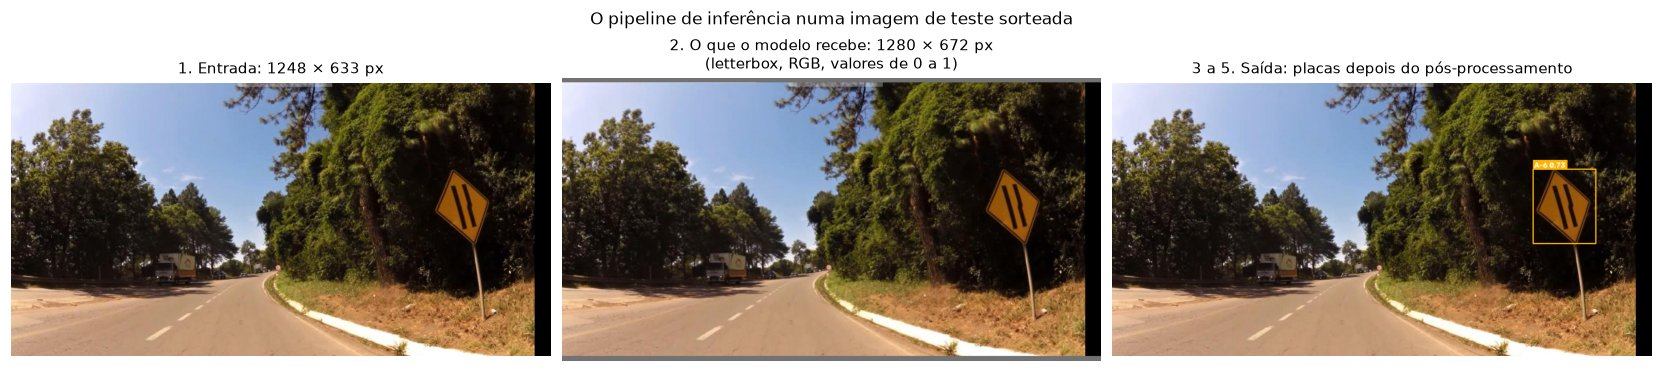

captura_2023-10-11_16-20-40_png.rf.1ee71f6ca0d73ceef40e167300eb9e2e.jpg: anotadas ['A-21e']
3. O modelo devolve 9 candidatos com confianca >= 0.01
4. Depois do pos-processamento (limiar 0.41, caixas na imagem original): 1 placa(s)
   A-6          0.73  caixa (973, 200, 1118, 372)  Cruzamento de vias


In [57]:
com_placa = sorted(a for a, g in GAB_TESTE.items() if g)
SORTEADAS = pd.Series(com_placa).sample(5, random_state=SEMENTE).tolist()
caminho = DIR_YOLO / "teste" / "images" / SORTEADAS[0]

imagem = inferir.ler_imagem(caminho)                                         # 1. entrada
entrada = inferir.preprocessar(imagem, CONFIG_INFERENCIA["imgsz"])          # 2. pre-processamento
bruta = inferir.executar_modelo(MODELO, entrada)                            # 3. modelo
placas = inferir.posprocessar(bruta, entrada.shape[2:], imagem.shape,      # 4. pos-processamento
                              MODELO.names, LIMIAR)
anotada = inferir.desenhar(imagem, placas)                                   # 5. saida

vista_entrada = (entrada[0].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
paineis = [
    (cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB), f"1. Entrada: {imagem.shape[1]} × {imagem.shape[0]} px"),
    (vista_entrada, f"2. O que o modelo recebe: {entrada.shape[3]} × {entrada.shape[2]} px\n(letterbox, RGB, valores de 0 a 1)"),
    (cv2.cvtColor(anotada, cv2.COLOR_BGR2RGB), "3 a 5. Saída: placas depois do pós-processamento"),
]
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6), layout="constrained")
for eixo, (img, titulo) in zip(eixos, paineis):
    eixo.imshow(img)
    eixo.set_title(titulo)
    eixo.axis("off")
fig.suptitle("O pipeline de inferência numa imagem de teste sorteada")
salvar_figura(fig, DIR_FIGURAS / "13_pipeline_de_inferencia.jpg")
mostrar_foto(fig)

print(f"{caminho.name}: anotadas {[g[0] for g in GAB_TESTE[caminho.name]]}")
print(f"3. O modelo devolve {len(bruta)} candidatos com confianca >= {inferir.CONF_BRUTA}")
print(f"4. Depois do pos-processamento (limiar {LIMIAR:.2f}, caixas na imagem original): {len(placas)} placa(s)")
for p in placas:
    print(f"   {p.classe:<12} {p.confianca:.2f}  caixa {p.caixa}  {p.descricao}")

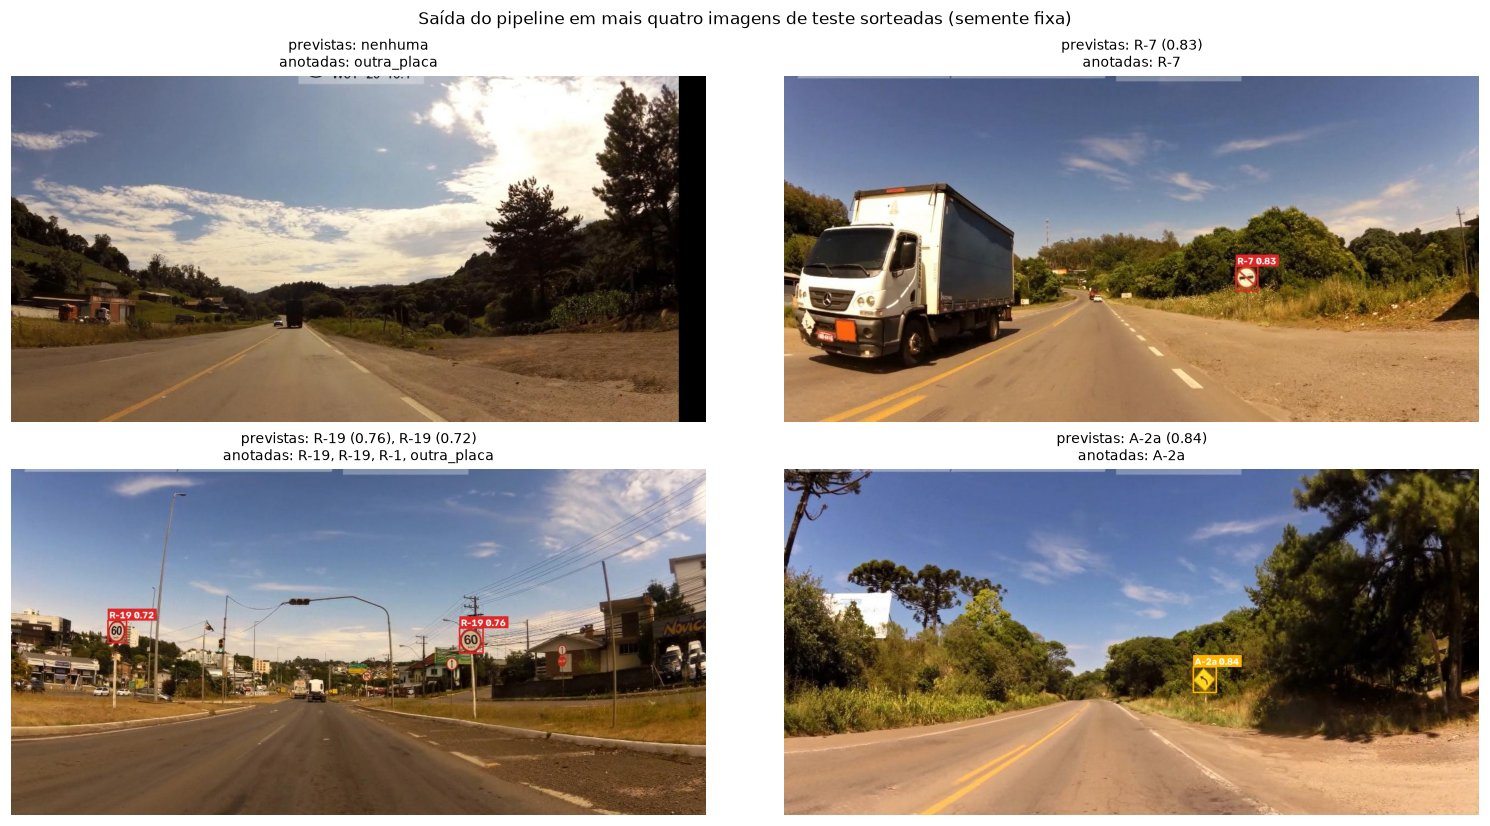

In [58]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 7.4), layout="constrained")
for eixo, nome in zip(eixos.ravel(), SORTEADAS[1:]):
    imagem, placas = inferir.inferir(MODELO, CONFIG_INFERENCIA, DIR_YOLO / "teste" / "images" / nome, LIMIAR)
    eixo.imshow(cv2.cvtColor(inferir.desenhar(imagem, placas), cv2.COLOR_BGR2RGB))
    previstas = ", ".join(f"{p.classe} ({p.confianca:.2f})" for p in placas) or "nenhuma"
    anotadas = ", ".join(g[0] for g in GAB_TESTE[nome])
    eixo.set_title(f"previstas: {previstas}\nanotadas: {anotadas}", fontsize=9)
    eixo.axis("off")
fig.suptitle("Saída do pipeline em mais quatro imagens de teste sorteadas (semente fixa)")
salvar_figura(fig, DIR_FIGURAS / "14_inferencia_exemplos.jpg")
mostrar_foto(fig)

Na imagem sorteada para o passo a passo, o modelo erra a classe: a placa anotada é uma `A-21e` e
sai como `A-6`, a família de losangos de pista da Seção 9.2. A figura fica como saiu do sorteio.
Nas outras quatro, o modelo acerta a `R-7`, as duas `R-19` e a `A-2a`, e perde três placas
pequenas e distantes: uma `R-1` e duas `outra_placa`.

Duas conferências fecham a seção. A primeira compara o pipeline explícito do `inferir.py` com o
`predict` do Ultralytics, que faz o pré-processamento por dentro, em 20 imagens de teste
sorteadas: as placas têm de sair iguais. A segunda roda o script pela linha de comando, como o
README manda, e mostra o JSON que ele grava.

In [59]:
# Conferencia 1: o pre-processamento explicito do inferir.py da as mesmas placas que o predict do
# Ultralytics, que faz tudo por dentro. Vinte imagens de teste com placa, sorteadas.
diferencas, iguais = [], 0
conferidas = pd.Series(com_placa).sample(20, random_state=SEMENTE + 1).tolist()
for nome in conferidas:
    caminho = DIR_YOLO / "teste" / "images" / nome
    _, nossas = inferir.inferir(MODELO, CONFIG_INFERENCIA, caminho, LIMIAR)
    ref = MODELO.predict(str(caminho), imgsz=CONFIG_INFERENCIA["imgsz"], conf=LIMIAR, verbose=False)[0]
    deles = sorted(zip(ref.boxes.conf.tolist(), ref.boxes.cls.tolist(), ref.boxes.xyxy.tolist()), reverse=True)
    if [p.classe for p in nossas] == [MODELO.names[int(k)] for _, k, _ in deles]:
        iguais += 1
    diferencas += [float(np.abs(np.array(p.caixa) - np.array(b)).max()) for p, (_, _, b) in zip(nossas, deles)]
print(f"Mesmas placas e classes em {iguais} de {len(conferidas)} imagens | maior diferenca de caixa: "
      f"{max(diferencas):.1f} px (o inferir.py arredonda para pixel inteiro)")
assert iguais == len(conferidas) and max(diferencas) < 1.0

# Conferencia 2: o script roda sozinho, pela linha de comando, como o README manda.
saida_cli = DIR_TREINOS.parent / "inferencia_exemplo"
comando = [sys.executable, str(RAIZ / "inferir.py"), str(DIR_YOLO / "teste" / "images" / SORTEADAS[0]),
           "--saida", str(saida_cli)]
resultado = subprocess.run(comando, capture_output=True, text=True, encoding="utf-8")
print("\n$ python inferir.py <imagem de teste> --saida <pasta>")
print(resultado.stdout.replace(str(saida_cli), "<pasta>"))
assert resultado.returncode == 0, resultado.stderr
print((saida_cli / f"{Path(SORTEADAS[0]).stem}_placas.json").read_text(encoding="utf-8"))

Mesmas placas e classes em 20 de 20 imagens | maior diferenca de caixa: 0.5 px (o inferir.py arredonda para pixel inteiro)



$ python inferir.py <imagem de teste> --saida <pasta>
Modelo modelo_n2.pt | entrada de 1280 px | limiar de confiança 0.41

captura_2023-10-11_16-20-40_png.rf.1ee71f6ca0d73ceef40e167300eb9e2e.jpg: 1 placa(s) em 5017 ms
  A-6          0.73  caixa (973, 200, 1118, 372)  Cruzamento de vias

Saídas anotadas e JSON em: <pasta>

{
  "imagem": "captura_2023-10-11_16-20-40_png.rf.1ee71f6ca0d73ceef40e167300eb9e2e.jpg",
  "largura": 1248,
  "altura": 633,
  "modelo": "modelo_n2.pt",
  "limiar_confianca": 0.41,
  "contagem": {
    "A-6": 1
  },
  "placas": [
    {
      "classe": "A-6",
      "descricao": "Cruzamento de vias",
      "confianca": 0.726,
      "caixa": [
        973,
        200,
        1118,
        372
      ]
    }
  ]
}


---
## 11. Limitações e próximos passos

O que o Checkpoint 2 deixa em aberto, na ordem em que entra no trabalho até a Ex2 (24/11):

1. **A mesma placa em dias diferentes.** A Seção 9.4 encontrou 5 placas de validação e teste que
   também estão no treino, em dois lugares, sem efeito mensurável nas métricas. A busca não acha
   uma placa vista de ângulo muito diferente. Para a entrega final, a opção mais limpa é tirar o
   trevo de 11/10 do teste e retreinar.
2. **Anotação esparsa, sobretudo no teste.** A maior parte dos alarmes falsos são placas reais
   sem anotação: 35 de 45 na validação e 49 de 54 na amostra do teste (Seções 8.3 e 9.3). A
   precisão medida é um piso, e o limiar foi escolhido contra um gabarito que pune acertos.
   Revisar as anotações dos dias de validação e teste é o que mais pode mudar os números, e vem
   antes de ajustar hiperparâmetros.
3. **Orçamento de 20 épocas.** O nano parou com a taxa de aprendizado quase em zero, e um treino
   de 100 épocas dele já estava em 0,708 na época 21 (Seção 8.1). A Ex2 repete nano e small com
   100 épocas e reaplica a regra de escolha.
4. **Placas pequenas.** O acerto cai de 76% para 60% abaixo de 25 px de lado. As opções a testar
   são resolução de entrada maior e inferência em recortes sobrepostos da imagem.
5. **Classes com poucos exemplos.** Várias classes têm de um a seis exemplos na validação e no
   teste, e o recall delas muda 15 a 20 pontos com uma placa a mais ou a menos. A `outra_placa`
   está na maioria das trocas de classe.

Os hiperparâmetros da Ex2 saem dessa lista: épocas, resolução de entrada, fração de fundo no
treino (10% hoje, Seção 4) e o limiar de confiança.